# Análise Exploratória de Dados (Avaliação do Modelo)

Avaliação do modelo antes de submetê-lo para treinamento do modelo.

## Fase 01 - Tokenização

Fase custosa, exige GPU, só execute se realmente necessário. Se o dataset já estiver com o pré-processamento textual e com a quantidade de tokens mapeado, avance para segunda esta.

## Fase 02 - Undersampling

Análise e aplicação de undersampling.

**Período:** 01/2021 a 12/2025

**Dataset:** Full (Acórdãos e Decisões)

**Aceleradores de Hardware - Ordem de Custo**

1. CPU
2. GPUs: T4
2. GPUs: L4
4. TPU v5e-1
5. TPU v6e-1
6. GPUs: A100
7. GPUs: G4
8. GPUs: H100

##Preparação do Ambiente

In [ ]:
BASE_PATH_GENERAL = '/content/drive/MyDrive/_Mestrado/'
BASE_PATH_DATASET = f'{BASE_PATH_GENERAL}Datasets/'
BASE_PATH_GRAPHIC = f'{BASE_PATH_GENERAL}models/'

RANDOM_SEED = 42
TEST_SIZE_SPLIT = 0.2
PUNCTUATION = "S"
TRAIN_LONG_TEXT = "S"

class_names = ['Desfavorável ao Réu', 'Favorável ao Réu']

FONT_SIZE = 25 # fonte para gráficos que serão adicionados em artigos científicos padrão IEEE.
SAVE_GRAPHIC = True
DPI_RESOLUTION = 500
SHOW_LEGEND = False

In [ ]:
# Silenciar warings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
def mount_drive():
  from google.colab import drive
  drive.mount('/content/drive')

In [ ]:
mount_drive()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#!pip install transformers

In [ ]:
import numpy as np
import torch
from pylab import rcParams
import pandas as pd
import os

In [ ]:
# 1. Instalação das fontes Microsoft no Linux do Colab
!apt-get update -qq
!echo "ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true" | debconf-set-selections
!apt-get install -y --no-install-recommends ttf-mscorefonts-installer

# 2. Imports
import glob
import shutil
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.interpolate import make_interp_spline

# 3. Limpeza preventiva de cache antigo
shutil.rmtree(os.path.expanduser('~/.cache/matplotlib'), ignore_errors=True)

# 4. Registro de todas as variações da Times (Regular, Bold, Italic, etc.)
font_files = glob.glob('/usr/share/fonts/truetype/msttcorefonts/Times*.ttf')
for f in font_files:
    fm.fontManager.addfont(f)

# 5. Configuração global para dissertação acadêmica
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'axes.unicode_minus': False  # Garante renderização correta de números negativos nos eixos
})

print("✅ Ambiente configurado: Times New Roman pronta para uso global!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ttf-mscorefonts-installer is already the newest version (3.8.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 53 not upgraded.
✅ Ambiente configurado: Times New Roman pronta para uso global!


In [ ]:
# Padronização dos Gráficos
%config InlineBackend.figure_format='retina'

sns.set(style='whitegrid', palette='muted', font_scale=1.2)
COLORS_PALETTE = ["#0098CC", "#CCA100", "#CC6400", "#CC0057", "#8ACC02", "#7200CC"]
sns.set_palette(sns.color_palette(COLORS_PALETTE))
rcParams['figure.figsize'] = 12, 8

In [ ]:
# Garante que processos que dependem de aleatoriedade gerem sempre o mesmo resultado,
#   caso ocorra a execução do notebook novamente.

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

## Abertura do Dataset Principal

In [ ]:
# Define the correct file path
file_path = f"{BASE_PATH_DATASET}dataset_decisoes_acordaos_HC_2021_2025.csv" # Fase 1 - Apenas carregado dos dados abertos (dados brutos)
#file_path = f"{BASE_PATH_DATASET}dataset_decisoes_acordaos_HC_2021_2025_tokenized.csv" # Fase 2 - Tokenizado
#file_path = f"{BASE_PATH_DATASET}preprocessed_geral_HC_2021_2025.csv" # Fase 3: Engenharia de Atributos e remoção de vieses

#file_path = f"{BASE_PATH_DATASET}preprocessed_HC_acordaos_2025_goldset.csv" # Plus: Goldset para validar a qualidade textual da petição inicial

df = None
loaded_from = None

if os.path.exists(file_path):
    try:
        df = pd.read_csv(file_path, sep=';')
        loaded_from = file_path
        print(f"✅ Arquivo carregado com sucesso de: {file_path}")
        print(f"Shape: {df.shape}")
        display(df.head(3))
    except Exception as e:
        print(f"❌ Erro ao ler {file_path}: {e}")
else:
    print(f"⚠️ Arquivo CSV não encontrado no caminho: {file_path}")
    print("Por favor, verifique se o arquivo existe ou o caminho está correto.")

✅ Arquivo carregado com sucesso de: /content/drive/MyDrive/_Mestrado/Datasets/dataset_decisoes_acordaos_HC_2021_2025_tokenized.csv
Shape: (404578, 19)


,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,DECISAO_FAVORAVEL,RELATORIO,NUM_TOKENS_RELATORIO,TEXTO_LONGO,classe,ANO_RECEBIMENTO
0,353105536,2025-12-31,DECISÃO,202505102484,2025-12-20,2025-12-23,HERMAN BENJAMIN,NaN,Negando,4355,11,HC,1063382,N,Cuida-se de Habeas Corpus com pedido de limina...,307,N,0,2025
1,353128400,2025-12-31,DECISÃO,202505106071,2025-12-22,2025-12-26,HERMAN BENJAMIN,NaN,Negando,5897,9,HC,1063851,N,Trata-se de Habeas Corpus com pedido de limina...,441,N,0,2025
2,353128835,2025-12-31,DECISÃO,202505109521,2025-12-23,2025-12-26,HERMAN BENJAMIN,NaN,Negando,3608,8,HC,1064262,N,Cuida-se de Habeas Corpus com pedido de limina...,407,N,0,2025


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404578 entries, 0 to 404577
Data columns (total 19 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   SEQDOCUMENTO                 404578 non-null  int64 
 1   DATAPUBLICACAO               404578 non-null  object
 2   TIPODOCUMENTO                404578 non-null  object
 3   NUMEROREGISTRO               404578 non-null  int64 
 4   DATARECEBIMENTO              404578 non-null  object
 5   DATADISTRIBUICAO             404571 non-null  object
 6   MINISTRO                     404578 non-null  object
 7   RECURSO                      68147 non-null   object
 8   TEOR                         403941 non-null  object
 9   ASSUNTOS                     404578 non-null  object
 10  NUM_DIAS_CONCLUSAO_PROCESSO  404578 non-null  int64 
 11  TIPOPROCESSO                 404578 non-null  object
 12  NUMEROPROCESSO               404578 non-null  int64 
 13  DECISAO_FAVORA

In [ ]:
df.query("NUM_TOKENS_RELATORIO == 750").head()

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,DECISAO_FAVORAVEL,RELATORIO,NUM_TOKENS_RELATORIO,TEXTO_LONGO,classe,ANO_RECEBIMENTO
4508,351432730,2025-12-17,DECISÃO,202504876892,2025-12-09,2025-12-10,ANTONIO SALDANHA PALHEIRO,NaN,Negando,3608,8,HC,1059506,N,Trata-se de habeas corpus com pedido liminar i...,750,S,0,2025
5936,351117579,2025-12-15,ACÓRDÃO,202504213783,2025-10-27,2025-10-28,ANTONIO SALDANHA PALHEIRO,AgRg,Não Conhecendo,3372,49,HC,1047454,N,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,750,S,0,2025
9343,348734613,2025-12-02,DECISÃO,202504633593,2025-11-24,2025-11-25,ROGERIO SCHIETTI CRUZ,NaN,Negando,5560,8,HC,1055124,N,"F. A. L., acusado de lesão corporal praticada ...",750,S,0,2025
10970,348603137,2025-11-28,DECISÃO,202504626225,2025-11-24,2025-11-25,HERMAN BENJAMIN,NaN,Negando,10636,4,HC,1055037,N,Cuida-se de Habeas Corpus impetrado em favor d...,750,S,0,2025
14851,346575394,2025-11-17,ACÓRDÃO,202500421560,2025-02-11,2025-02-12,MARIA MARLUCE CALDAS,AgRg,Negando,"3633, 3608",279,HC,980672,N,Trata-se de agravo regimental interposto por A...,750,S,0,2025


In [ ]:
2/0

#Só avance se necessário... Fase 1 | Fase 2

ZeroDivisionError: division by zero

## Análise Exploratória de Dados

Feita com dataset pré-processado sem remoção de viesses antes da etapa de treinamento.

In [ ]:
#df = df_acordaos_2025.copy()
df['RECURSO'].unique()

array(['AgRg', 'EDcl', nan, 'RCD'], dtype=object)

In [ ]:
# RE	RECURSO EXTRAORDINÁRIO
# PET	PETIÇÃO
# IAC	INCIDENTE DE ASSUNÇÃO DE COMPETÊNCIA
# RO	RECURSO ORDINÁRIO
# ARE	AGRAVO EM RECURSO EXTRAORDINÁRIO
# AgInt	AGRAVO INTERNO
# AgRg	AGRAVO REGIMENTAL
# EDcl	EMBARGOS DE DECLARAÇÃO
# IAC	INCIDENTE DE ASSUNÇÃO DE COMPETÊNCIA
# PExt	PEDIDO DE EXTENSÃO
# PDist	PEDIDO DE DISTINÇÃO
# RCD	PEDIDO DE RECONSIDERAÇÃO
# nan : SEM RECURSO
# '': SEM RECURSO

In [ ]:
import pandas as pd
import numpy as np

# 1. Limpeza do campo RECURSO: remover espaços em branco e colocar em maiúsculo
df['RECURSO_CLEAN'] = df['RECURSO'].astype(str).str.replace(' ', '', regex=False).str.upper()

# 2. Dicionário de mapeamento conforme regras fornecidas
recurso_mapping = {
    'RE': 'RECURSO EXTRAORDINÁRIO',
    'PET': 'PETIÇÃO',
    'IAC': 'INCIDENTE DE ASSUNÇÃO DE COMPETÊNCIA',
    'RO': 'RECURSO ORDINÁRIO',
    'ARE': 'AGRAVO EM RECURSO EXTRAORDINÁRIO',
    'AGINT': 'AGRAVO INTERNO',
    'AGRG': 'AGRAVO REGIMENTAL',
    'EDCL': 'EMBARGOS DE DECLARAÇÃO',
    'PEXT': 'PEDIDO DE EXTENSÃO',
    'PDIST': 'PEDIDO DE DISTINÇÃO',
    'RCD': 'PEDIDO DE RECONSIDERAÇÃO',
    'AGRAVOREGIMENTAL': 'AGRAVO REGIMENTAL',
    'PETIÇÃO': 'PETIÇÃO',
    'PEDIDODEEXTENSÃO': 'PEDIDO DE EXTENSÃO',
    'PEDIDODERECONSIDERAÇÃO': 'PEDIDO DE RECONSIDERAÇÃO',
    'EMBARGOSDEDECLARAÇÃO': 'EMBARGOS DE DECLARAÇÃO',
    'RECURSOEXTRAORDINÁRIO': 'RECURSO EXTRAORDINÁRIO',
    'RECURSOORDINÁRIO': 'RECURSO ORDINÁRIO',
    'AGRAVOINTERNO': 'AGRAVO INTERNO'
}

# 3. Criar campo DS_RECURSO aplicando o mapeamento e tratando nulos/vazios
df['DS_RECURSO'] = df['RECURSO_CLEAN'].map(recurso_mapping)

# Caso o valor original seja nulo, vazio ou 'NAN', definir como 'SEM RECURSO'
df.loc[df['RECURSO'].isna() | (df['RECURSO_CLEAN'] == 'NAN') | (df['RECURSO_CLEAN'] == ''), 'DS_RECURSO'] = 'SEM RECURSO'

# Se houver algum caso não mapeado que não seja nulo, mantém o valor limpo original
df['DS_RECURSO'] = df['DS_RECURSO'].fillna(df['RECURSO_CLEAN'])

# Remover coluna temporária de limpeza
df.drop(columns=['RECURSO_CLEAN'], inplace=True)

# Exibir distribuição para validação
print("Distribuição do novo campo DS_RECURSO:")
display(df['DS_RECURSO'].value_counts(dropna=False))

Distribuição do novo campo DS_RECURSO:


,count
DS_RECURSO,
AGRAVO REGIMENTAL,375
EMBARGOS DE DECLARAÇÃO,32
SEM RECURSO,14
PEDIDO DE RECONSIDERAÇÃO,2


### Gráficos

In [ ]:
# Garantir que DATARECEBIMENTO seja do tipo datetime e extrair o ano
df['DATARECEBIMENTO'] = pd.to_datetime(df['DATARECEBIMENTO'], errors='coerce')
df['ANO_RECEBIMENTO'] = df['DATARECEBIMENTO'].dt.year.astype('Int64')
# Agrupar os dados por ano e decisão favorável
df_ano_decisao = df.groupby(['ANO_RECEBIMENTO', 'DECISAO_FAVORAVEL']).size().reset_index(name='Quantidade')

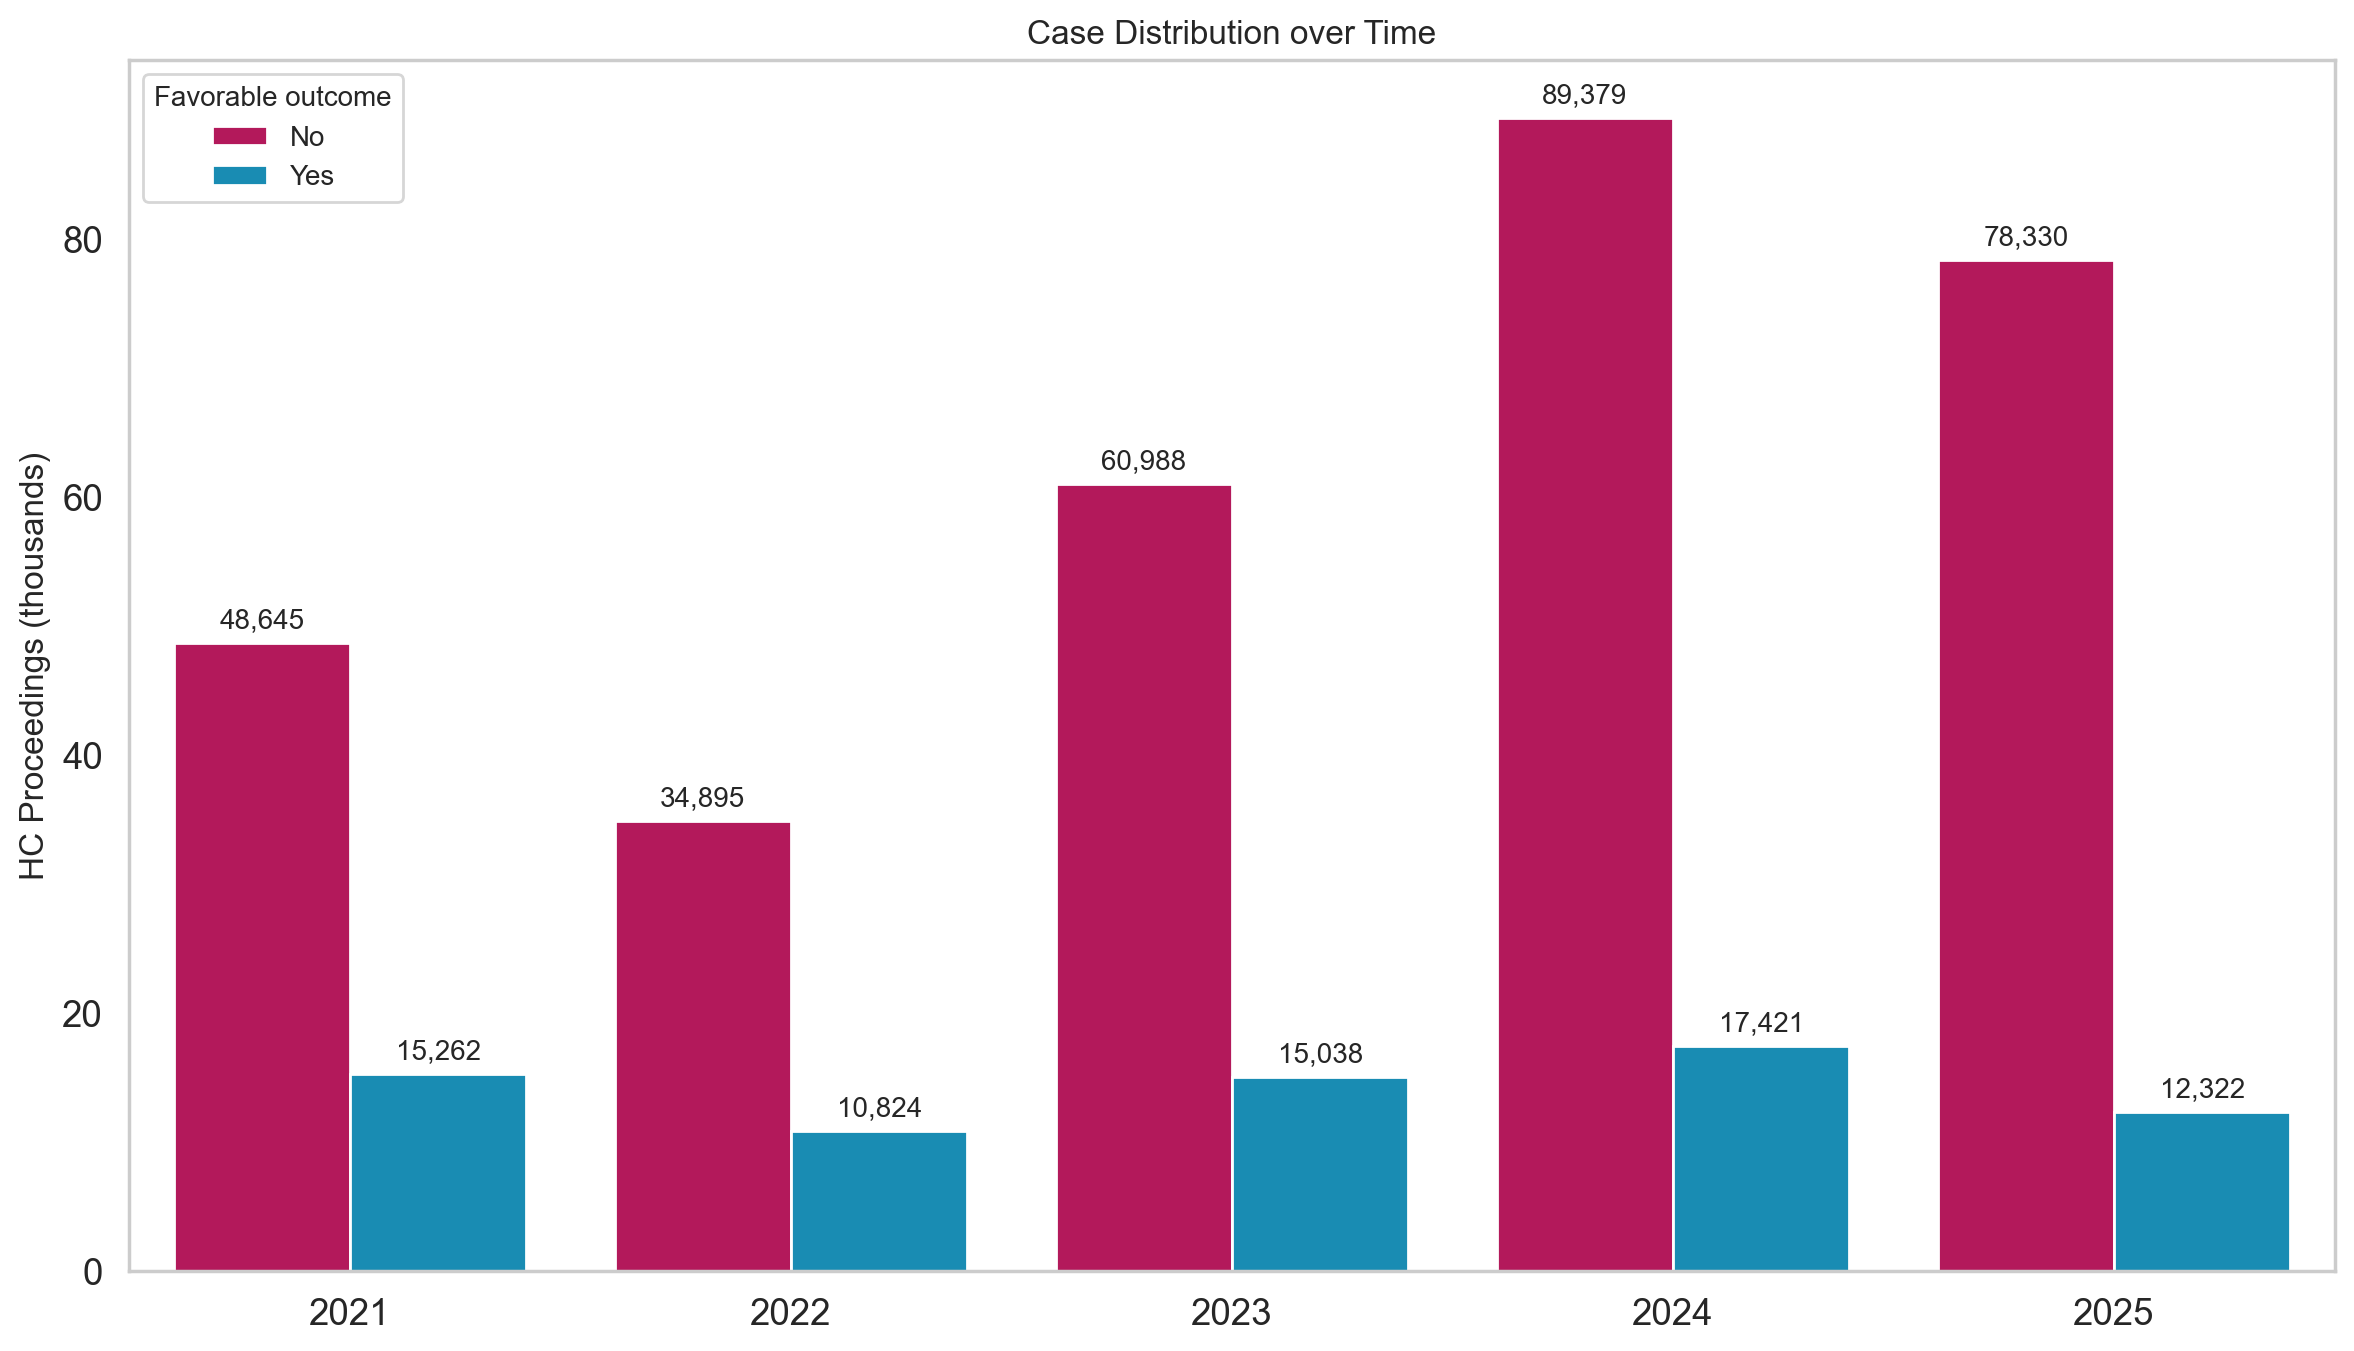

In [ ]:
# Filtrar apenas a partir de 2021
df_ano_decisao = df_ano_decisao[df_ano_decisao['ANO_RECEBIMENTO'] >= 2021]

# Ajustar valores para milhares no DataFrame de plotagem
df_plot = df_ano_decisao.copy()
df_plot['Quantidade_K'] = df_plot['Quantidade'] / 1000

# Plotar o gráfico de barras
plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=df_plot,
    x='ANO_RECEBIMENTO',
    y='Quantidade_K',
    hue='DECISAO_FAVORAVEL',
    palette=['#CC0057', '#0098CC']
)

plt.title('Case Distribution over Time', fontsize=12)
plt.xlabel('')
plt.ylabel('HC Proceedings (thousands)', fontsize=12)

# Garantir que o grid esteja desativado para não sobrepor os números
ax.grid(False)

# Formatar o eixo Y para exibir números simples
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))

# Corrigir a legenda
handles, _ = ax.get_legend_handles_labels()
plt.legend(handles=handles, title='Favorable outcome', labels=['No', 'Yes'], title_fontsize=10, fontsize=10, loc='upper left')

# Adicionar os rótulos com os valores absolutos formatados acima de cada barra
for container in ax.containers:
    # Exibe o valor total original com separador de milhar
    labels = [f'{int(v*1000):,}' for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=10)

plt.tight_layout()
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})
plt.show()

####Total Volume and Decision Percentage per Year (Stacked)

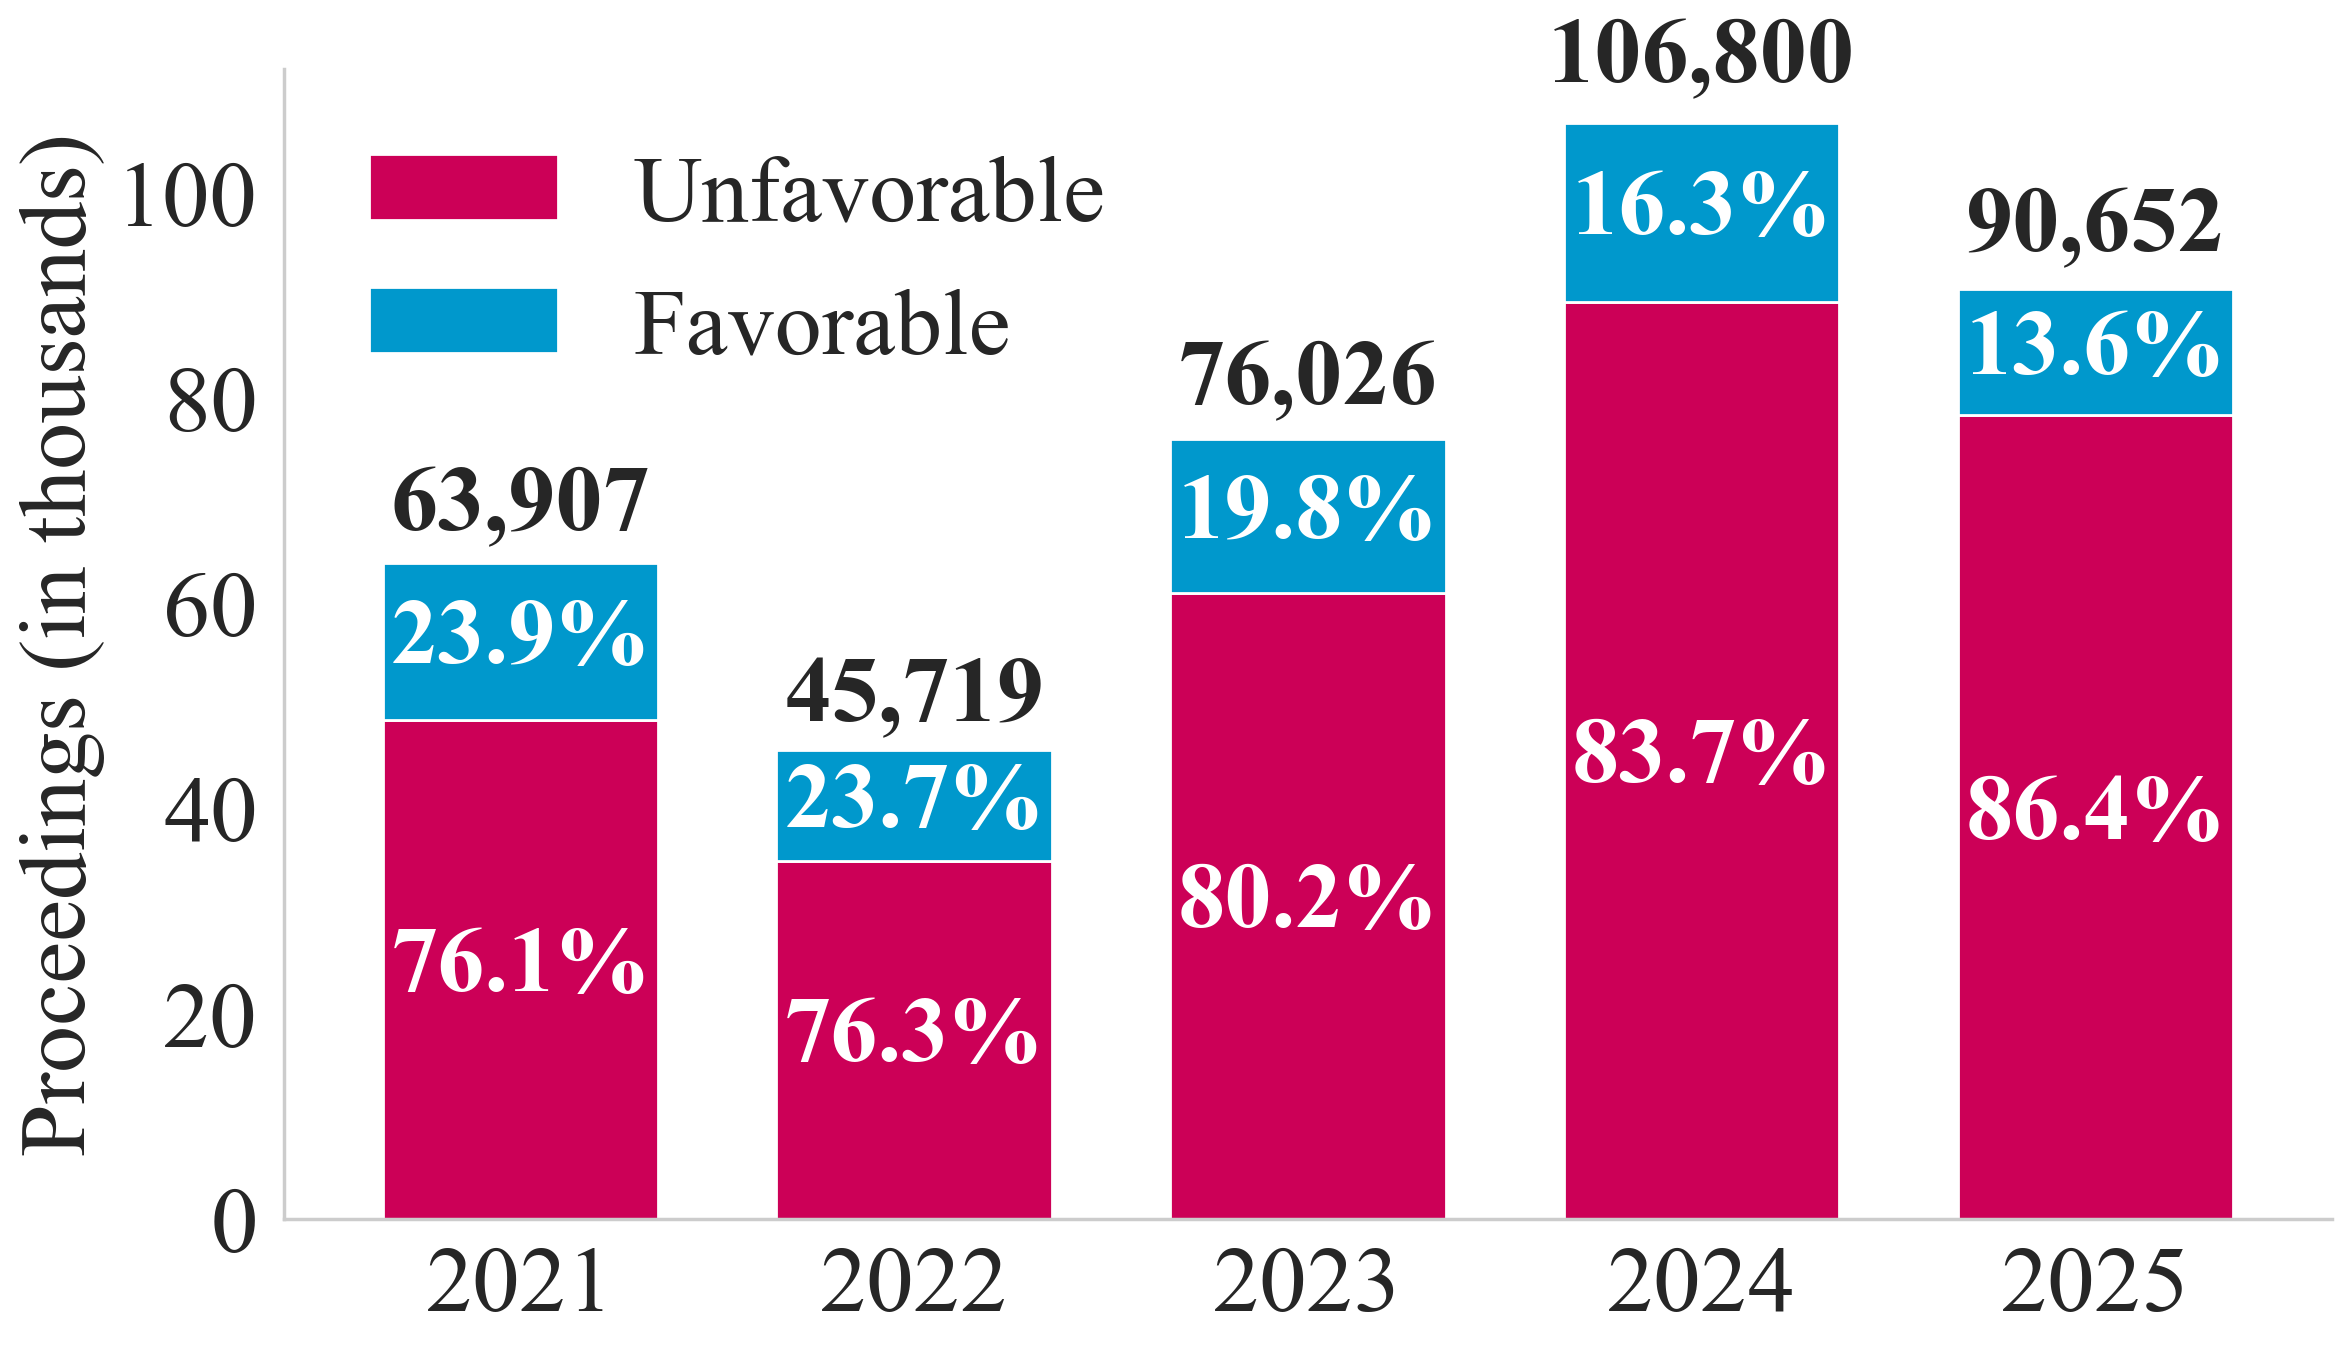

In [ ]:
#Total Volume and Decision Percentage per Year (Stacked)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})

vFONT_SIZE = FONT_SIZE_TWO_COLUMN

# Preparar os dados pivotando para o formato empilhado
df_stacked = df_ano_decisao.pivot(index='ANO_RECEBIMENTO', columns='DECISAO_FAVORAVEL', values='Quantidade').fillna(0)

# Criar o gráfico
ax = df_stacked.plot(kind='bar', stacked=True, figsize=(12, 7), color=['#CC0057', '#0098CC'], width=0.7)

plt.title('', fontsize=FONT_SIZE, pad=20) #Total Volume and Decision Percentage per Year (Stacked)
plt.xlabel('', fontsize=FONT_SIZE) #Year of Filing
plt.ylabel('Proceedings (in thousands)', fontsize=vFONT_SIZE)
plt.xticks(rotation=0, fontsize=vFONT_SIZE)
plt.yticks(fontsize=vFONT_SIZE)

# Formatar eixo Y exibindo valores em milhares de forma limpa
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{int(x/1000)}'))

# Adicionar rótulos de totais no topo e PERCENTUAIS dentro dos segmentos
for i, (index, row) in enumerate(df_stacked.iterrows()):
    total = row.sum()
    y_offset = 0
    for col in df_stacked.columns:
        val = row[col]
        if val > 0:
            # Calcular o percentual
            percentage = (val / total) * 100
            # Rótulo PERCENTUAL dentro do segmento
            ax.text(i, y_offset + val/2, f'{percentage:.1f}%',
                    ha='center', va='center', color='white', fontweight='bold', fontsize=vFONT_SIZE)
            y_offset += val

    # Rótulo do total no topo
    ax.text(i, total + (total * 0.02), f'{int(total):,}', ha='center', va='bottom', fontweight='bold', fontsize=vFONT_SIZE)

plt.legend(title='', labels=['Unfavorable', 'Favorable'], loc='upper left', fontsize=vFONT_SIZE, frameon=False)
sns.despine()
plt.grid(False)
plt.tight_layout()

if SAVE_GRAPHIC:
    plt.savefig(f"{BASE_PATH_GRAPHIC}total_volume_and_decision_percentage.pdf", format='pdf', bbox_inches='tight', dpi=DPI_RESOLUTION)

plt.show()

#### Paper ACM

Graphic salved...


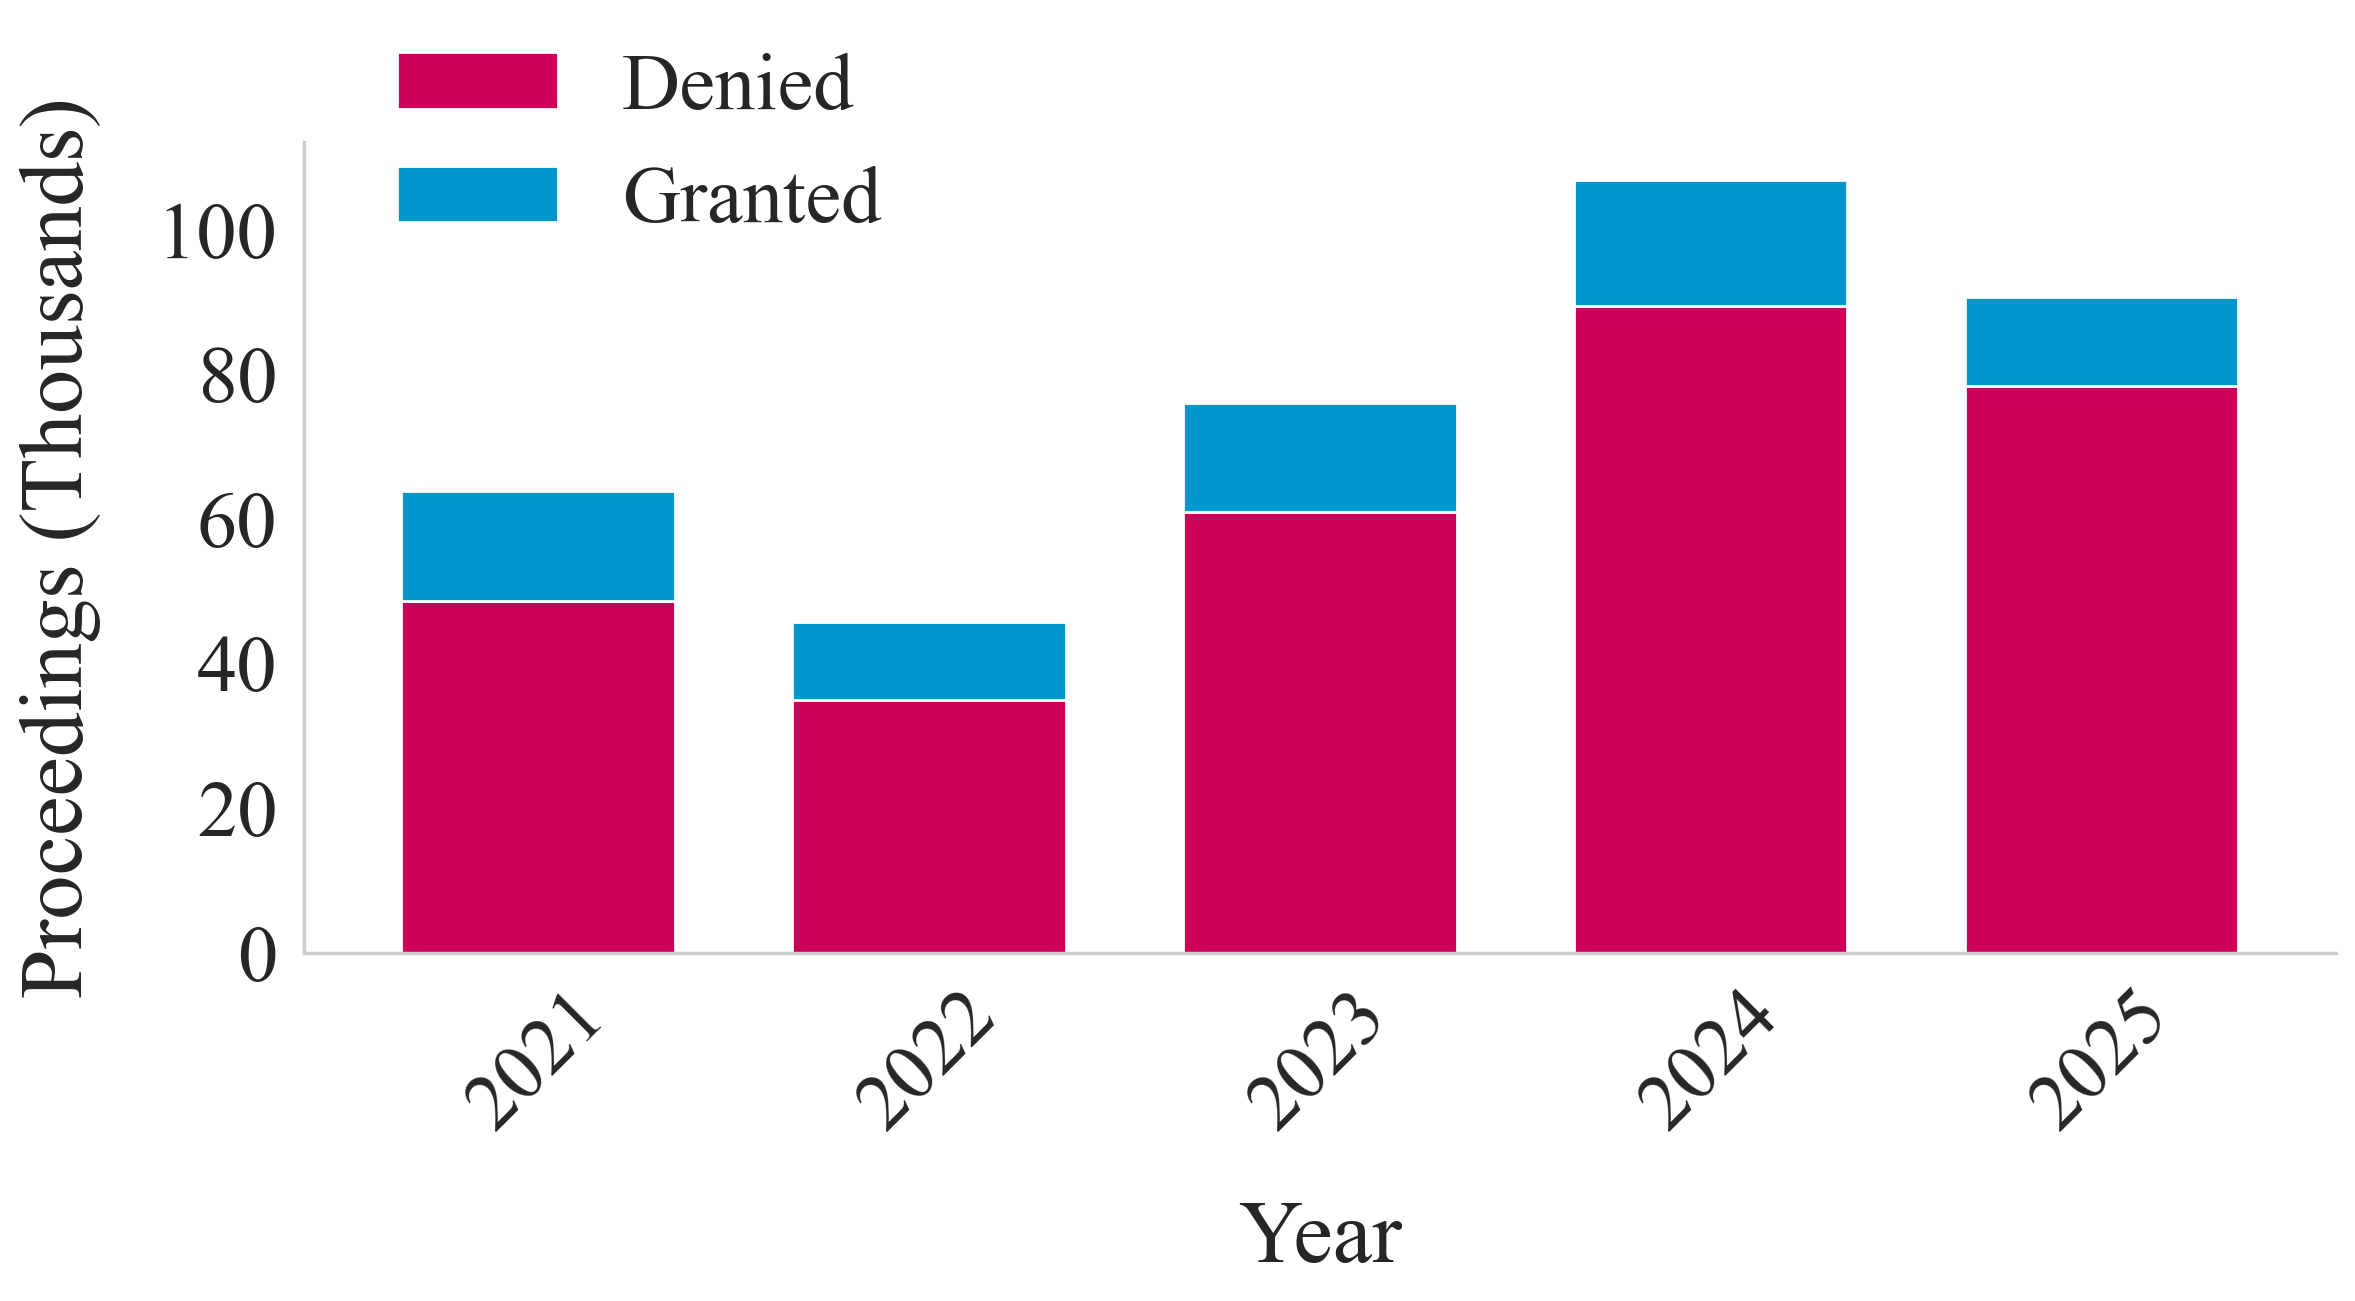

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Configurações de estilo globais
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})

vFONT_SIZE = 32

# Preparar os dados pivotando para o formato empilhado
df_stacked = df_ano_decisao.pivot(index='ANO_RECEBIMENTO', columns='DECISAO_FAVORAVEL', values='Quantidade').fillna(0)

# Criar o gráfico
ax = df_stacked.plot(kind='bar', stacked=True, figsize=(12, 7), color=['#CC0057', '#0098CC'], width=0.7)

plt.title('', fontsize=vFONT_SIZE, pad=20)
plt.xlabel('Year', fontsize=vFONT_SIZE, labelpad=20)
plt.ylabel('Proceedings (Thousands)', fontsize=vFONT_SIZE, labelpad=20)
plt.xticks(rotation=45, fontsize=(vFONT_SIZE-3))
plt.yticks(fontsize=(vFONT_SIZE-3))

# Formatar eixo Y exibindo valores em milhares de forma limpa
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{int(x/1000)}'))

# Legenda com os rótulos atualizados para 'Denied' e 'Granted' posicionada mais no topo
plt.legend(title='', labels=['Denied', 'Granted'], loc='upper left', bbox_to_anchor=(0.01, 1.2), fontsize=(vFONT_SIZE-3), frameon=False)

sns.despine()
plt.grid(False)
plt.tight_layout()

if SAVE_GRAPHIC:
    plt.savefig(f"{BASE_PATH_GRAPHIC}total_volume_and_decision_percentage_column.pdf", format='pdf', bbox_inches='tight', dpi=DPI_RESOLUTION)
    print("Graphic salved...")

plt.show()

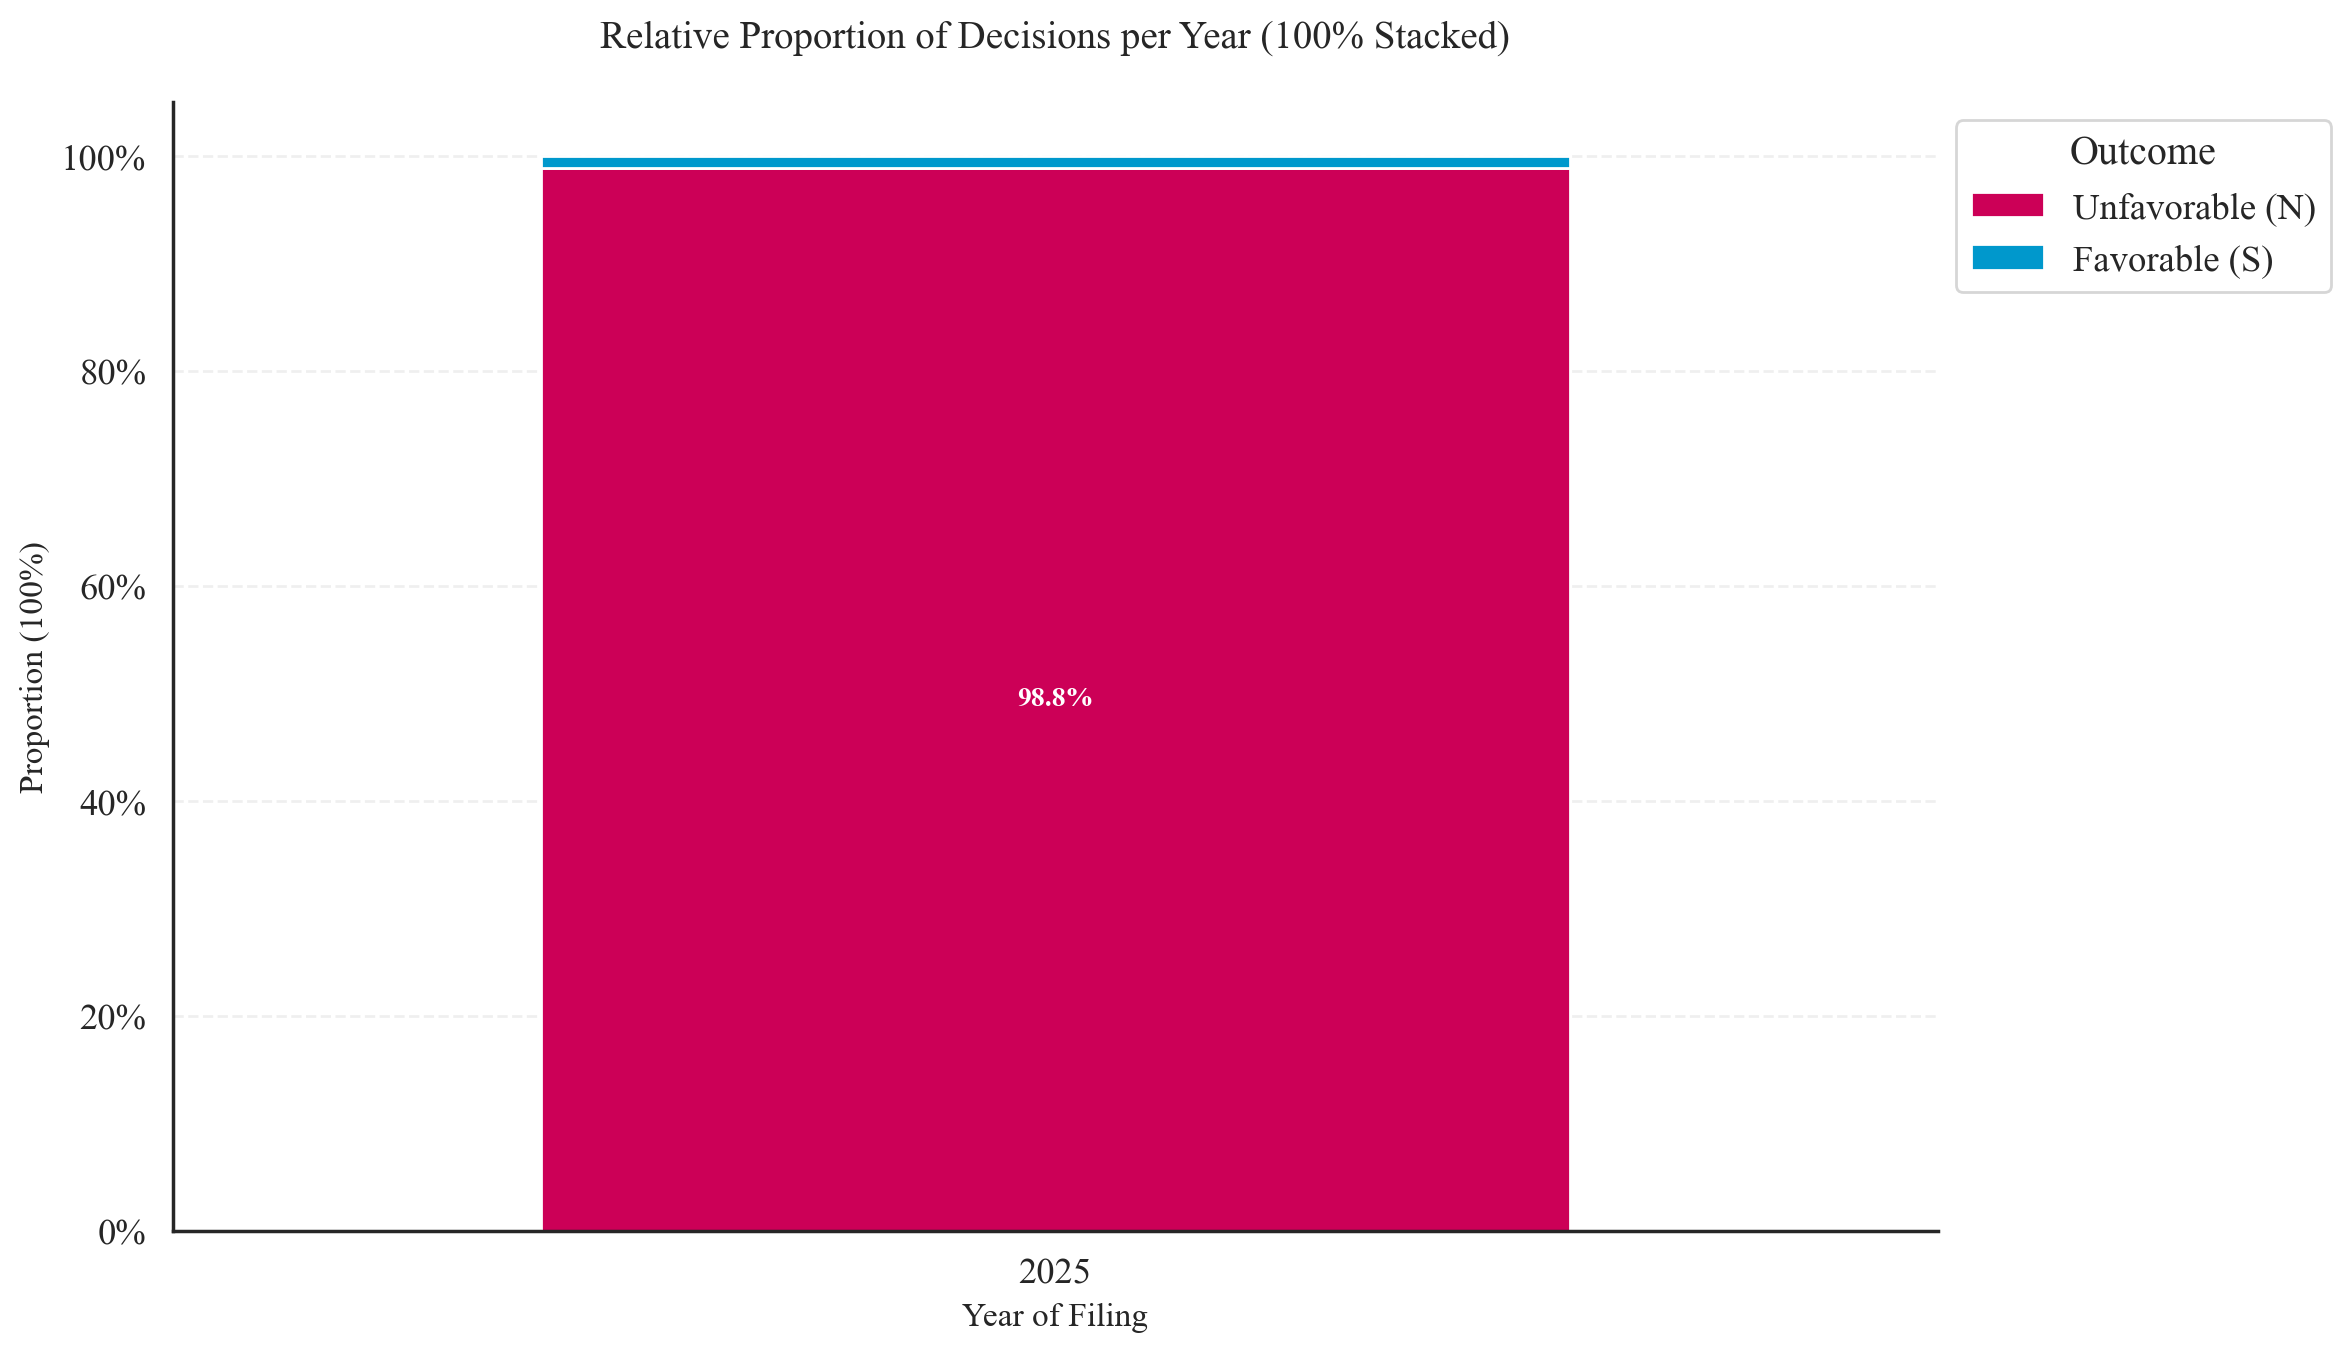

In [ ]:
# Preparar os dados normalizados (proporção 0 a 1)
df_100_percent = df_stacked.div(df_stacked.sum(axis=1), axis=0)

# Criar o gráfico
ax = df_100_percent.plot(kind='bar', stacked=True, figsize=(12, 7), color=['#CC0057', '#0098CC'], width=0.7)

plt.title('Relative Proportion of Decisions per Year (100% Stacked)', fontsize=14, pad=20)
plt.xlabel('Year of Filing', fontsize=12)
plt.ylabel('Proportion (100%)', fontsize=12)
plt.xticks(rotation=0)

# Formatar o eixo Y para exibir percentuais de 0 a 100%
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Adicionar rótulos percentuais dentro dos segmentos
for i, (index, row) in enumerate(df_100_percent.iterrows()):
    y_offset = 0
    for col in df_100_percent.columns:
        val = row[col]
        if val > 0.05: # Só exibe o texto se o segmento for grande o suficiente (>5%)
            ax.text(i, y_offset + val/2, f'{val*100:.1f}%',
                    ha='center', va='center', color='white', fontweight='bold', fontsize=10)
            y_offset += val

plt.legend(title='Outcome', labels=['Unfavorable (N)', 'Favorable (S)'], loc='upper left', bbox_to_anchor=(1, 1))
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

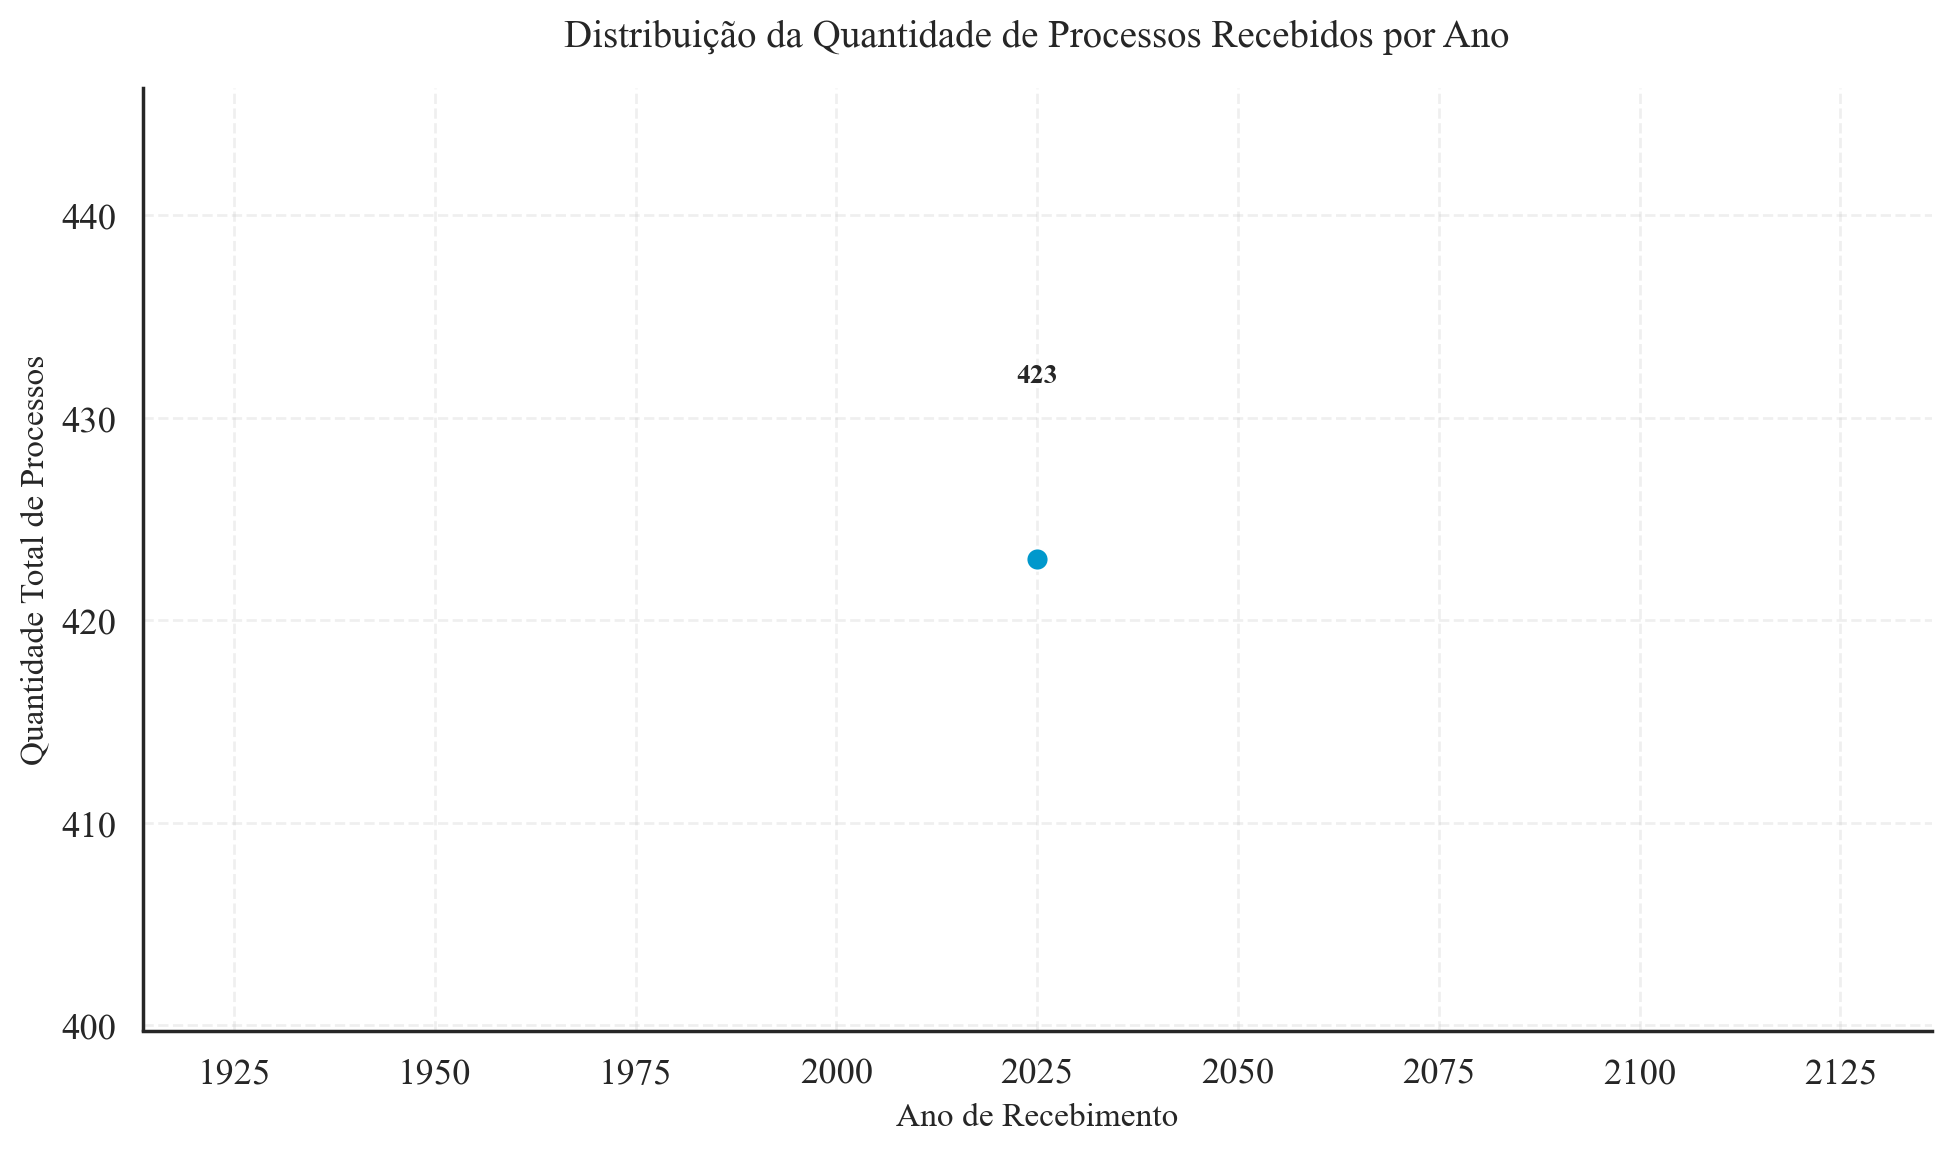

In [ ]:
# Agrupar a quantidade total de processos por ano
df_tendencia_ano = df.groupby('ANO_RECEBIMENTO').size().reset_index(name='Total')

# Filtrar a partir de 2021 (conforme o escopo do projeto)
df_tendencia_ano = df_tendencia_ano[df_tendencia_ano['ANO_RECEBIMENTO'] >= 2021]

# Configuração do gráfico de linhas
plt.figure(figsize=(10, 6))
ax = sns.lineplot(
    data=df_tendencia_ano,
    x='ANO_RECEBIMENTO',
    y='Total',
    marker='o',
    markersize=8,
    linewidth=2.5,
    color='#0098CC'
)

plt.title('Distribuição da Quantidade de Processos Recebidos por Ano', fontsize=14, pad=15)
plt.xlabel('Ano de Recebimento', fontsize=12)
plt.ylabel('Quantidade Total de Processos', fontsize=12)

# Configurar eixo X para mostrar anos como números inteiros e o eixo Y com separador de milhar
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# Adicionar os rótulos numéricos exatos em cima de cada ponto da linha
for x, y in zip(df_tendencia_ano['ANO_RECEBIMENTO'], df_tendencia_ano['Total']):
    plt.text(x, y + (y * 0.02), f'{int(y):,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

sns.despine()
plt.grid(axis='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

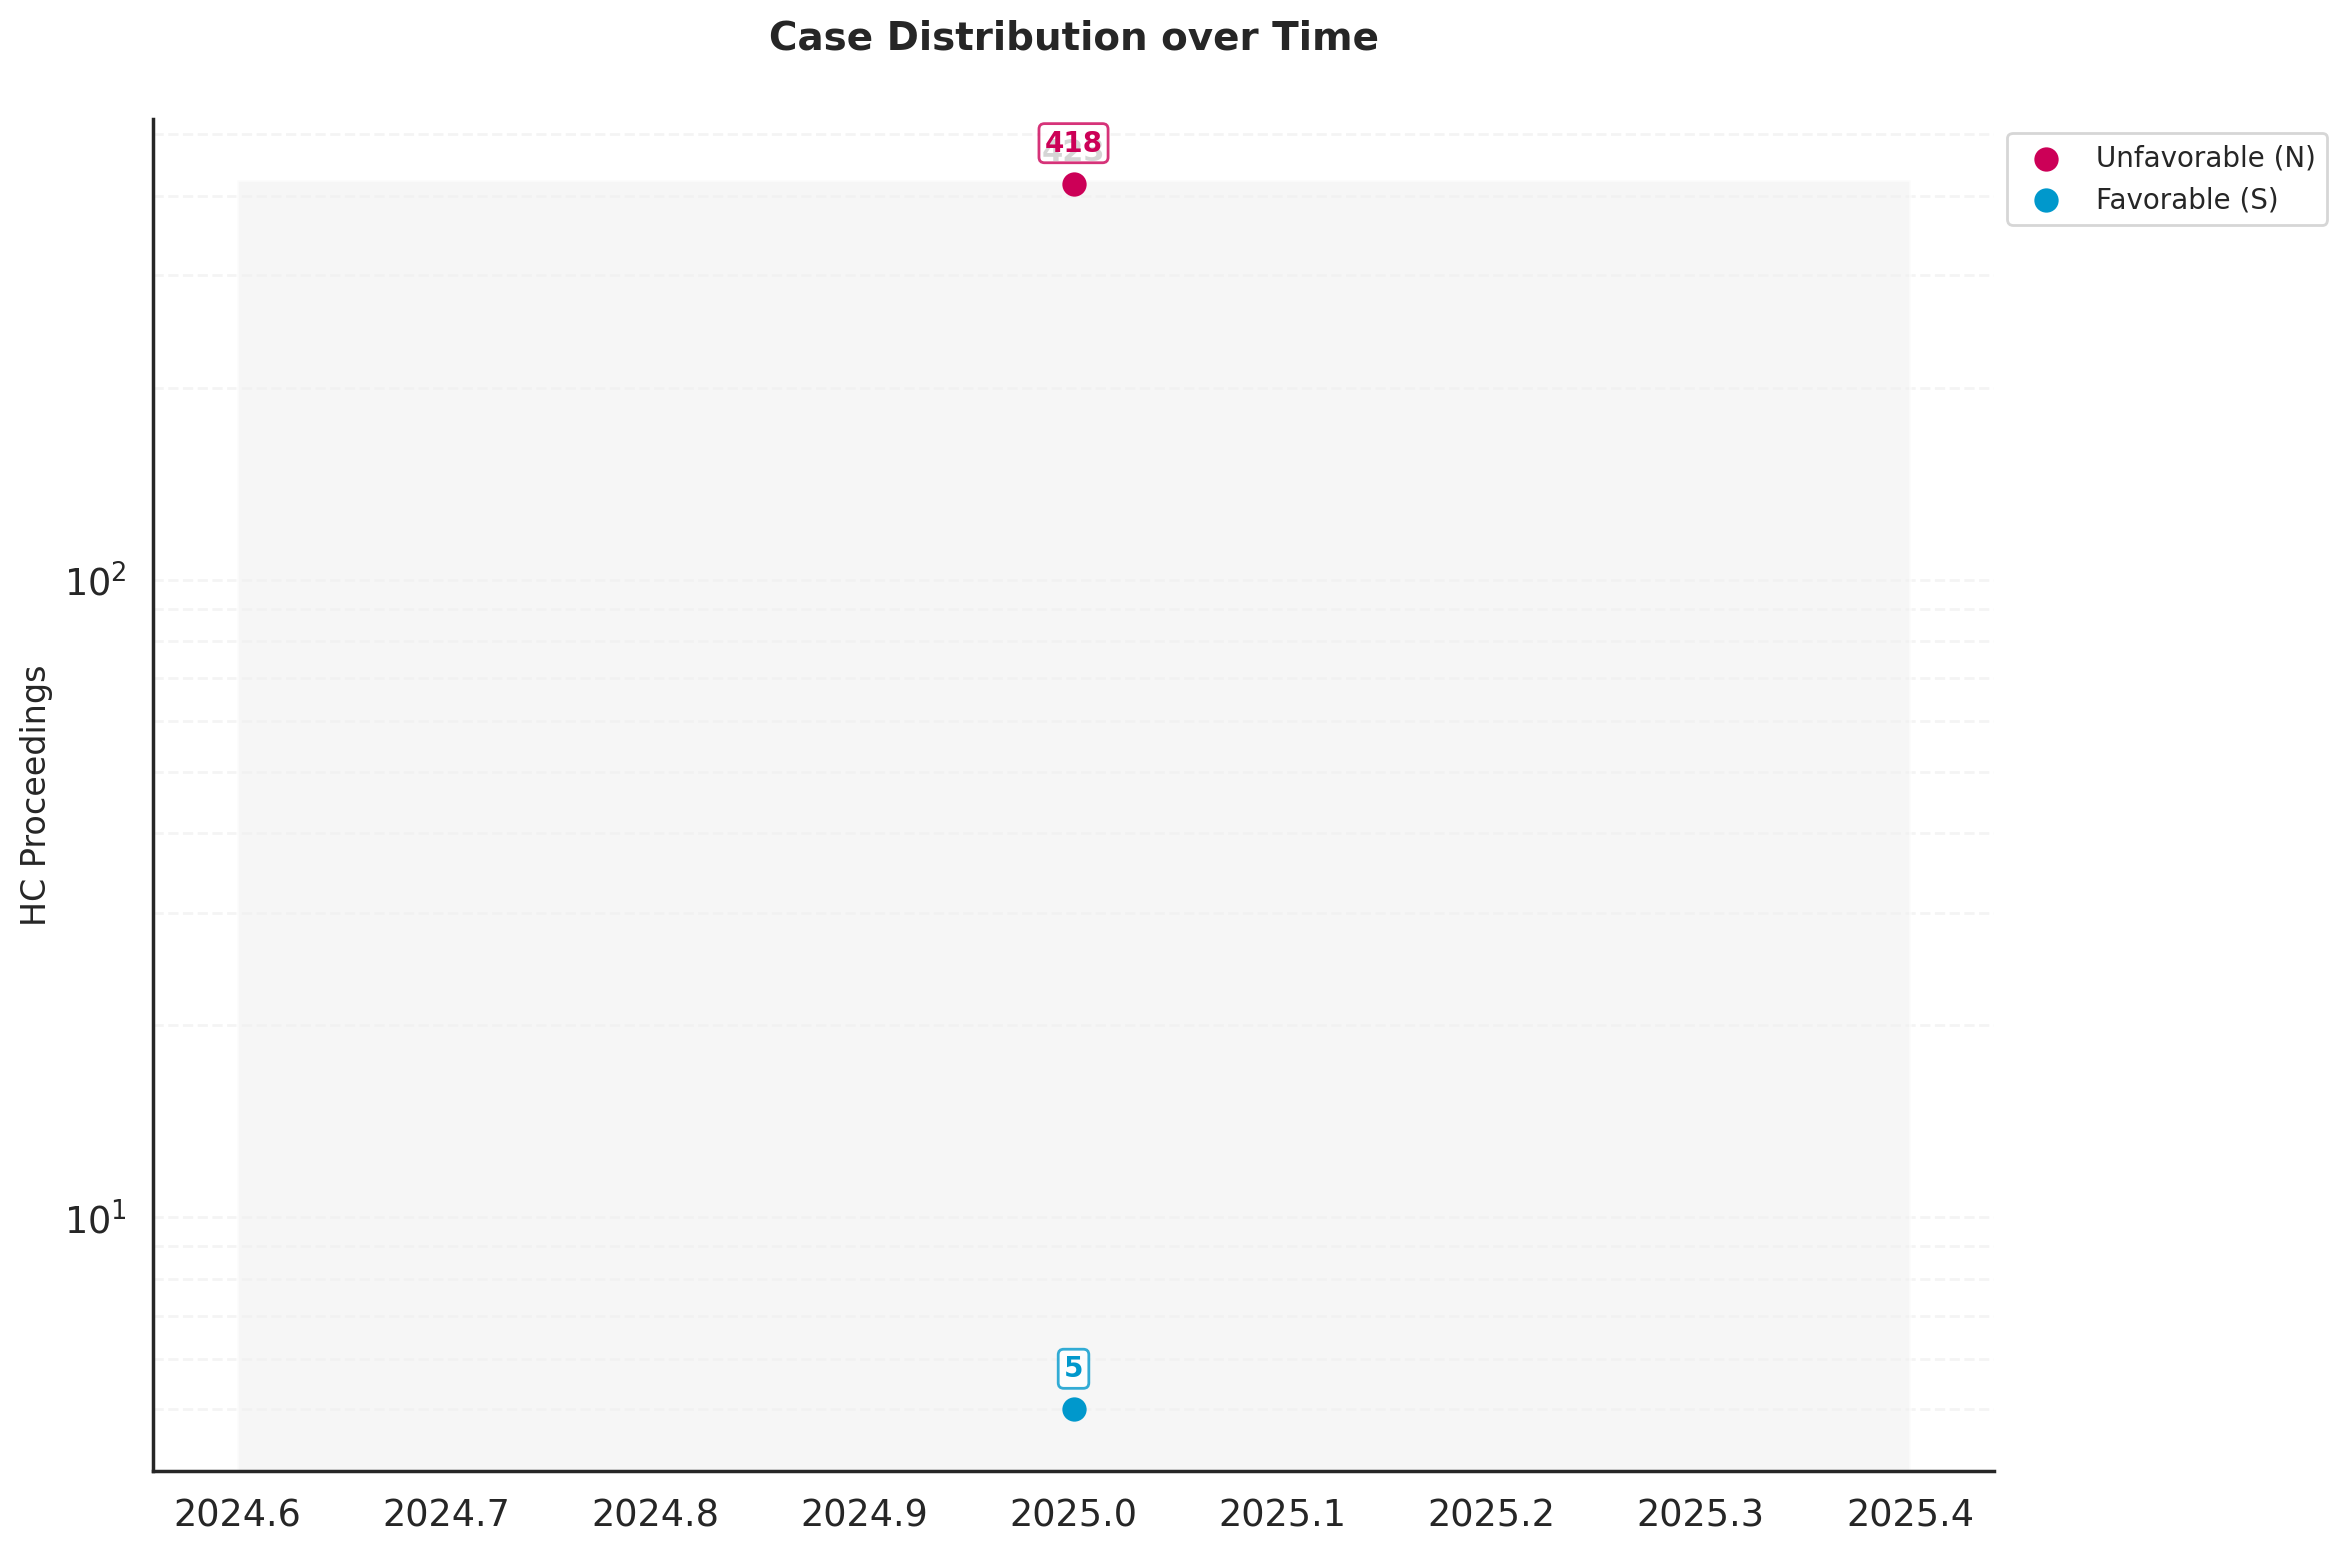

In [ ]:
# Gráfico Escala Logaritma com destaque de valores por categoria

# Agrupar a quantidade de processos por ano e por decisão favorável
df_tendencia = df.groupby(['ANO_RECEBIMENTO', 'DECISAO_FAVORAVEL']).size().reset_index(name='Total')

# Filtrar para considerar apenas os anos de 2021 a 2025
df_tendencia = df_tendencia[(df_tendencia['ANO_RECEBIMENTO'] >= 2021) & (df_tendencia['ANO_RECEBIMENTO'] <= 2025)]

# Configurar o estilo do seaborn
sns.set_style('white')

# Criar a figura
plt.figure(figsize=(12, 8))
ax = plt.gca()

# Calcular o total geral por ano para as barras de fundo
totais_ano = df_tendencia.groupby('ANO_RECEBIMENTO')['Total'].sum()
ax.bar(totais_ano.index, totais_ano.values, color='#F0F0F0', alpha=0.6, zorder=1)

# Anos para a suavização da curva
anos_smooth = np.linspace(2021, 2025, 300)

# Cores e Labels
classes = {'N': {'color': '#CC0057', 'label': 'Unfavorable (N)'},
           'S': {'color': '#0098CC', 'label': 'Favorable (S)'}}

for cls, props in classes.items():
    df_cls = df_tendencia[df_tendencia['DECISAO_FAVORAVEL'] == cls].sort_values('ANO_RECEBIMENTO')

    # Plotar Linha Suavizada
    if len(df_cls) > 3:
        spline = make_interp_spline(df_cls['ANO_RECEBIMENTO'], df_cls['Total'], k=3)
        y_smooth = spline(anos_smooth)
        ax.plot(anos_smooth, y_smooth, color=props['color'], linewidth=2.5, zorder=3, alpha=0.8)

    # Plotar Pontos Reais
    ax.scatter(df_cls['ANO_RECEBIMENTO'], df_cls['Total'], color=props['color'], s=60, zorder=5, label=props['label'])

    # Adicionar rótulos com os valores absolutos (origem) acima dos pontos
    for x, y in zip(df_cls['ANO_RECEBIMENTO'], df_cls['Total']):
        # Ajuste: Ambos agora usam 'bottom' e offset > 1 para ficar no topo
        ax.text(x, y * 1.1, f'{int(y):,}'.replace(',', '.'), color=props['color'],
                va='bottom', ha='center', fontsize=10, fontweight='bold',
                bbox=dict(facecolor='white', alpha=0.8, edgecolor=props['color'], boxstyle='round,pad=0.2'), zorder=6)

# Configurar a escala logarítmica no eixo Y
ax.set_yscale('log')

# Adicionar os rótulos de totais anuais no topo das barras
for ano, total in totais_ano.items():
    ax.text(ano, total * 1.05, f'{int(total):,}'.replace(',', '.'),
            ha='center', va='bottom', fontsize=11, fontweight='bold', color='#333333', zorder=2)

# Customizar títulos e rótulos
plt.title('Case Distribution over Time', fontsize=14, pad=25, fontweight='bold')
plt.ylabel('HC Proceedings', fontsize=12)
#plt.xlabel('Ano de Recebimento', fontsize=12)

# Formatação de eixos
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, which='both', axis='y', linestyle='--', alpha=0.2)

# Customizar a legenda
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=10, frameon=True)

sns.despine()
plt.tight_layout()
plt.show()

Distribuição da Classe DECISAO_FAVORAVEL:
N: 418 (98.82%)
S: 5 (1.18%)


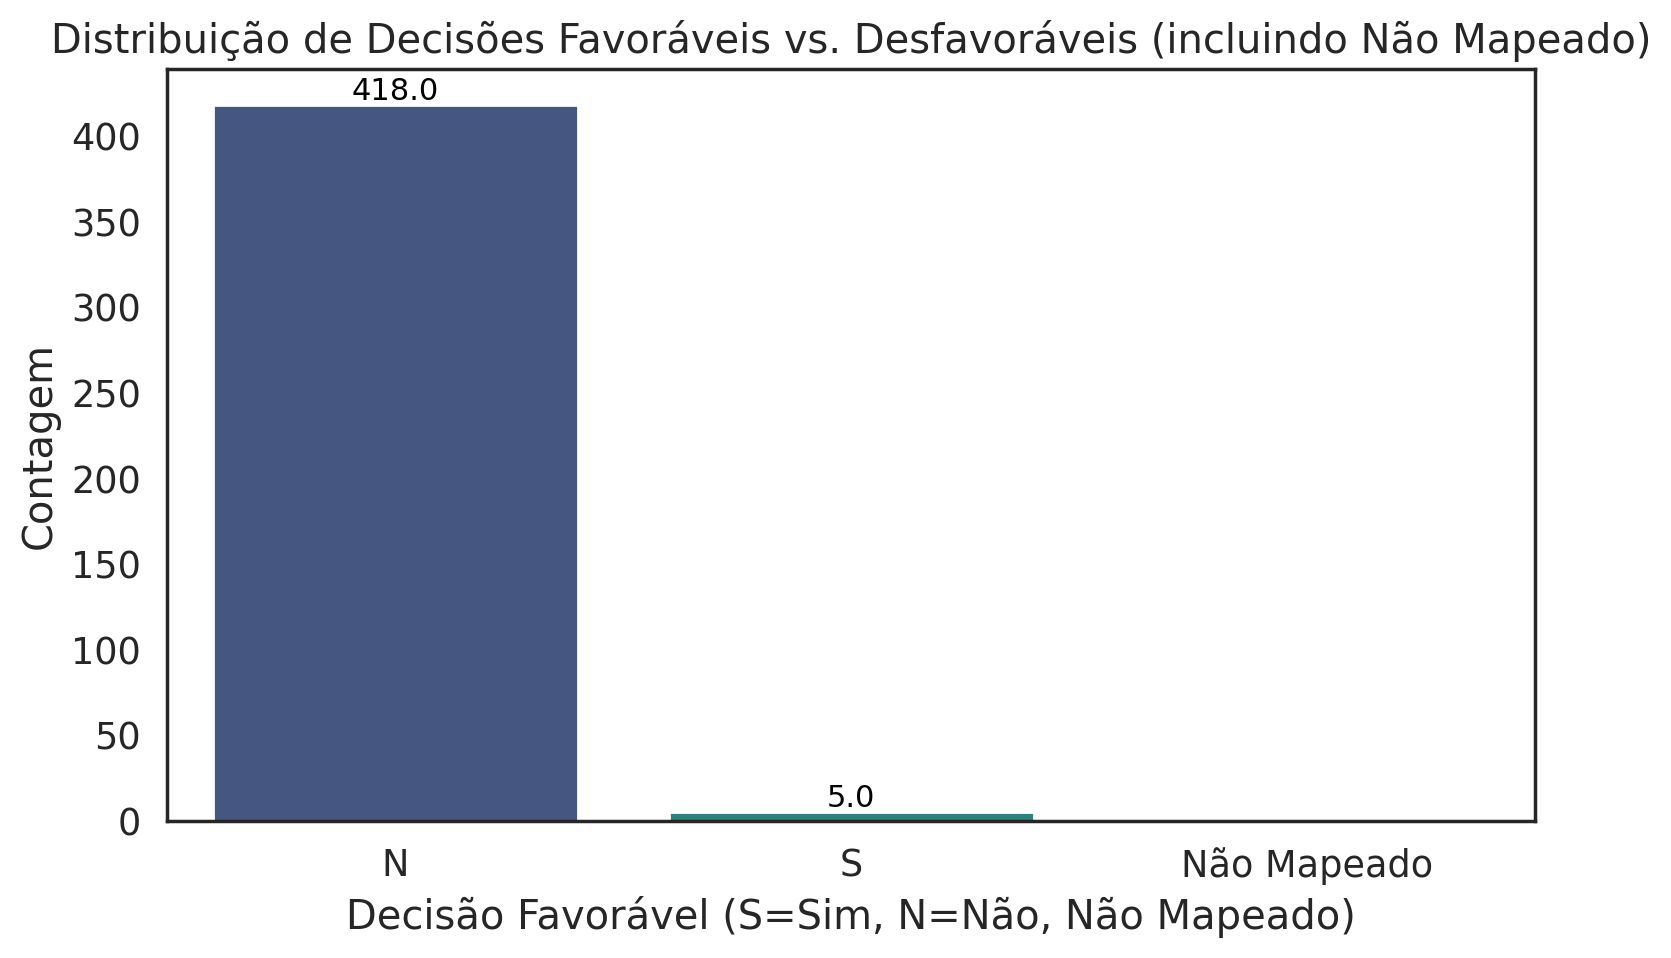

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Preencher valores NaN na coluna 'DECISAO_FAVORAVEL' com 'Não Mapeado'
df_temp = df.copy()
df_temp['DECISAO_FAVORAVEL'] = df_temp['DECISAO_FAVORAVEL'].fillna('Não Mapeado')

# Calculate distribution
class_counts = df_temp['DECISAO_FAVORAVEL'].value_counts()
class_percents = df_temp['DECISAO_FAVORAVEL'].value_counts(normalize=True) * 100

print("Distribuição da Classe DECISAO_FAVORAVEL:")
for idx, val in class_counts.items():
    print(f"{idx}: {val} ({class_percents[idx]:.2f}%)")

# Visualize the distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='DECISAO_FAVORAVEL', data=df_temp, palette='viridis', order=['N', 'S', 'Não Mapeado'])
plt.title('Distribuição de Decisões Favoráveis vs. Desfavoráveis (incluindo Não Mapeado)')
plt.xlabel('Decisão Favorável (S=Sim, N=Não, Não Mapeado)')
plt.ylabel('Contagem')

# Add percentage labels on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()


In [ ]:
# A partir deste momento haverá remoção de registros.
2/0

### Engenharia de Atributos e Remoção de Vieses

1.   Padronizar o TIPODOCUMENTO
2.   Remoção dos registros nos quais os campos TEOR e DECISAO_FAVORAVEL estejam em branco;
3.   Remoção de processos publicados - manutenção da decisão mais recente
4.  Manutenção apenas dos processos de origem penal



In [ ]:
# Uniformização do campo TIPODOCUMENTO para remover acentuações e padronizar os tipos
if 'df' in globals() and df is not None:
    print("Distribuição original de TIPODOCUMENTO:")
    print(df['TIPODOCUMENTO'].value_counts(dropna=False))

    # Dicionário de mapeamento para uniformizar os valores
    mapeamento_tipo = {
        'DECISÃO': 'DECISAO',
        'DECISAO': 'DECISAO',
        'ACÓRDÃO': 'ACORDAO',
        'ACORDAO': 'ACORDAO'
    }

    df['TIPODOCUMENTO'] = df['TIPODOCUMENTO'].map(mapeamento_tipo).fillna(df['TIPODOCUMENTO'])

    print("\nDistribuição de TIPODOCUMENTO após uniformização:")
    print(df['TIPODOCUMENTO'].value_counts(dropna=False))

Distribuição original de TIPODOCUMENTO:
TIPODOCUMENTO
ACORDAO    423
Name: count, dtype: int64

Distribuição de TIPODOCUMENTO após uniformização:
TIPODOCUMENTO
ACORDAO    423
Name: count, dtype: int64


In [ ]:
print('Agregando o campo TEOR...')

# Contar a frequência de cada TEOR, incluindo valores nulos
teor_counts = df['TEOR'].value_counts(dropna=False)

print(f"Total de valores únicos no campo TEOR (incluindo nulos): {len(teor_counts)}")
print("Top 10 TEORs mais frequentes:")
display(teor_counts.head(10))


Agregando o campo TEOR...
Total de valores únicos no campo TEOR (incluindo nulos): 4
Top 10 TEORs mais frequentes:


,count
TEOR,
Negando,358
Não Conhecendo,60
Concedendo,4
Admitindo Embargo,1


In [ ]:
print('Agregando o campo DECISAO_FAVORAVEL...')

# Contar a frequência de cada DECISAO_FAVORAVEL, incluindo valores nulos
decisao_counts = df['DECISAO_FAVORAVEL'].value_counts(dropna=False)

print(f"Total de valores únicos no campo DECISAO_FAVORAVEL (incluindo nulos): {len(decisao_counts)}")
print("Frequência de DECISAO_FAVORAVEL:")
display(decisao_counts)


Agregando o campo DECISAO_FAVORAVEL...
Total de valores únicos no campo DECISAO_FAVORAVEL (incluindo nulos): 2
Frequência de DECISAO_FAVORAVEL:


,count
DECISAO_FAVORAVEL,
N,418
S,5


In [ ]:
print(f"Shape do DataFrame antes da remoção: {df.shape}")

# Remover registros com TEOR nulo
df_filtered = df.dropna(subset=['TEOR']).copy()
print(f"Shape do DataFrame após remover TEOR nulo: {df_filtered.shape}")

# Remover registros com TEOR 'Outros'
df_filtered = df_filtered[df_filtered['TEOR'] != 'Outros'].copy()
print(f"Shape do DataFrame após remover TEOR 'Outros': {df_filtered.shape}")

df_filtered.info()

print("Filtragem do campo TEOR concluída. O DataFrame 'df' foi atualizado.")


Shape do DataFrame antes da remoção: (423, 20)
Shape do DataFrame após remover TEOR nulo: (423, 20)
Shape do DataFrame após remover TEOR 'Outros': (423, 20)
<class 'pandas.core.frame.DataFrame'>
Index: 423 entries, 11 to 18115
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   SEQDOCUMENTO                 423 non-null    int64         
 1   DATAPUBLICACAO               423 non-null    object        
 2   TIPODOCUMENTO                423 non-null    object        
 3   NUMEROREGISTRO               423 non-null    int64         
 4   DATARECEBIMENTO              423 non-null    datetime64[ns]
 5   DATADISTRIBUICAO             423 non-null    object        
 6   MINISTRO                     423 non-null    object        
 7   RECURSO                      409 non-null    object        
 8   TEOR                         423 non-null    object        
 9   ASSUNTOS            

In [ ]:
# Atualizar o DataFrame principal 'df' com o resultado filtrado
df = df_filtered.copy()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 423 entries, 11 to 18115
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   SEQDOCUMENTO                 423 non-null    int64         
 1   DATAPUBLICACAO               423 non-null    object        
 2   TIPODOCUMENTO                423 non-null    object        
 3   NUMEROREGISTRO               423 non-null    int64         
 4   DATARECEBIMENTO              423 non-null    datetime64[ns]
 5   DATADISTRIBUICAO             423 non-null    object        
 6   MINISTRO                     423 non-null    object        
 7   RECURSO                      409 non-null    object        
 8   TEOR                         423 non-null    object        
 9   ASSUNTOS                     423 non-null    object        
 10  NUM_DIAS_CONCLUSAO_PROCESSO  423 non-null    int64         
 11  TIPOPROCESSO                 423 non-null    ob

In [ ]:
del df_filtered
print("Variável 'df_filtered' removida da memória.")

Variável 'df_filtered' removida da memória.


In [ ]:
# 1. Garantir que DATAPUBLICACAO esteja em formato datetime para ordenação correta
df['DATAPUBLICACAO'] = pd.to_datetime(df['DATAPUBLICACAO'])

# 2. Ordenar por NUMEROREGISTRO e DATAPUBLICACAO (mais recente por último)
df_sorted = df.sort_values(by=['NUMEROREGISTRO', 'DATAPUBLICACAO'], ascending=[True, True])

# 3. Remover duplicatas mantendo o último registro (o mais recente)
registros_antes = len(df)
df = df_sorted.drop_duplicates(subset='NUMEROREGISTRO', keep='last').reset_index(drop=True)
registros_depois = len(df)

print(f"Processo de limpeza concluído.")
print(f"Registros originais: {registros_antes}")
print(f"Registros removidos: {registros_antes - registros_depois}")
print(f"Total de registros únicos mantidos: {registros_depois}")

# Exibir os primeiros registros para conferência
display(df.head())

Processo de limpeza concluído.
Registros originais: 423
Registros removidos: 0
Total de registros únicos mantidos: 423


,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,DECISAO_FAVORAVEL,RELATORIO,NUM_TOKENS_RELATORIO,ANO_RECEBIMENTO,classe,TEXTO_LONGO,DS_RECURSO
0,341425692,2025-10-24,ACORDAO,202500005626,2025-01-06,2025-01-07,OG FERNANDES,EDcl,Negando,"3633, 3608",291,HC,973190,N,Trata-se de embargos de declaração opostos por...,906,2025,0,S,EMBARGOS DE DECLARAÇÃO
1,303538413,2025-03-26,ACORDAO,202500060439,2025-01-13,2025-01-13,REYNALDO SOARES DA FONSECA,AgRg,Não Conhecendo,3608,72,HC,974152,N,Trata-se de agravo regimental interposto por E...,3824,2025,0,S,AGRAVO REGIMENTAL
2,302532390,2025-03-25,ACORDAO,202500069962,2025-01-13,2025-01-14,SEBASTIÃO REIS JÚNIOR,NaN,Concedendo,"3372, 14685",71,HC,974316,S,Trata-se de habeas corpus impetrado em favor d...,2004,2025,1,S,SEM RECURSO
3,320628916,2025-06-25,ACORDAO,202500074541,2025-01-14,2025-01-15,RIBEIRO DANTAS,EDcl,Negando,10637,162,HC,974424,N,Trata-se de embargos de declaração opostos pel...,1241,2025,0,S,EMBARGOS DE DECLARAÇÃO
4,307285401,2025-04-15,ACORDAO,202500084699,2025-01-15,2025-01-15,ANTONIO SALDANHA PALHEIRO,AgRg,Negando,3416,90,HC,974626,N,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,1090,2025,0,S,AGRAVO REGIMENTAL


In [ ]:
# Listar os valores únicos da coluna MINISTRO
ministros_unicos = df['MINISTRO'].unique()
ministros_unicos.sort()

print(f"Total de ministros únicos: {len(ministros_unicos)}")
print("\nLista de Ministros:")
for ministro in ministros_unicos:
    print(f"- {ministro}")

Total de ministros únicos: 9

Lista de Ministros:
- ANTONIO SALDANHA PALHEIRO
- CARLOS PIRES BRANDÃO
- JOEL ILAN PACIORNIK
- MESSOD AZULAY NETO
- OG FERNANDES
- REYNALDO SOARES DA FONSECA
- RIBEIRO DANTAS
- ROGERIO SCHIETTI CRUZ
- SEBASTIÃO REIS JÚNIOR


In [ ]:
MINISTROS_SECAO_PENAL = [
    "OG FERNANDES",
    "SEBASTIÃO REIS JÚNIOR",
    "ROGERIO SCHIETTI CRUZ",
    "REYNALDO SOARES DA FONSECA",
    "RIBEIRO DANTAS",
    "ANTONIO SALDANHA PALHEIRO",
    "JOEL ILAN PACIORNIK",
    "MESSOD AZULAY NETO",
    "MARLUCE CALDAS",
    "CARLOS PIRES BRANDÃO",
]

In [ ]:
# Filtrar o DataFrame para manter apenas os ministros da Seção Penal
print(f"Registros antes do filtro: {len(df)}")

df = df[df['MINISTRO'].isin(MINISTROS_SECAO_PENAL)].copy()

print(f"Registros após filtrar pela Seção Penal: {len(df)}")
print("\nDistribuição por Ministro com Decisões (S/N):")

# Agrupar por Ministro e Decisão Favorável
dist_ministro = df.groupby('MINISTRO')['DECISAO_FAVORAVEL'].value_counts().unstack(fill_value=0)

# Adicionar coluna de Total para manter a referência da ordenação original
dist_ministro['Total'] = dist_ministro.sum(axis=1)

# Ordenar pelo Total de processos (decrescente)
dist_ministro = dist_ministro.sort_values('Total', ascending=False)

display(dist_ministro)

Registros antes do filtro: 423
Registros após filtrar pela Seção Penal: 423

Distribuição por Ministro com Decisões (S/N):


DECISAO_FAVORAVEL,N,S,Total
MINISTRO,,,
ANTONIO SALDANHA PALHEIRO,188,1,189
REYNALDO SOARES DA FONSECA,138,0,138
JOEL ILAN PACIORNIK,50,1,51
SEBASTIÃO REIS JÚNIOR,11,3,14
MESSOD AZULAY NETO,12,0,12
RIBEIRO DANTAS,8,0,8
CARLOS PIRES BRANDÃO,5,0,5
OG FERNANDES,4,0,4
ROGERIO SCHIETTI CRUZ,2,0,2


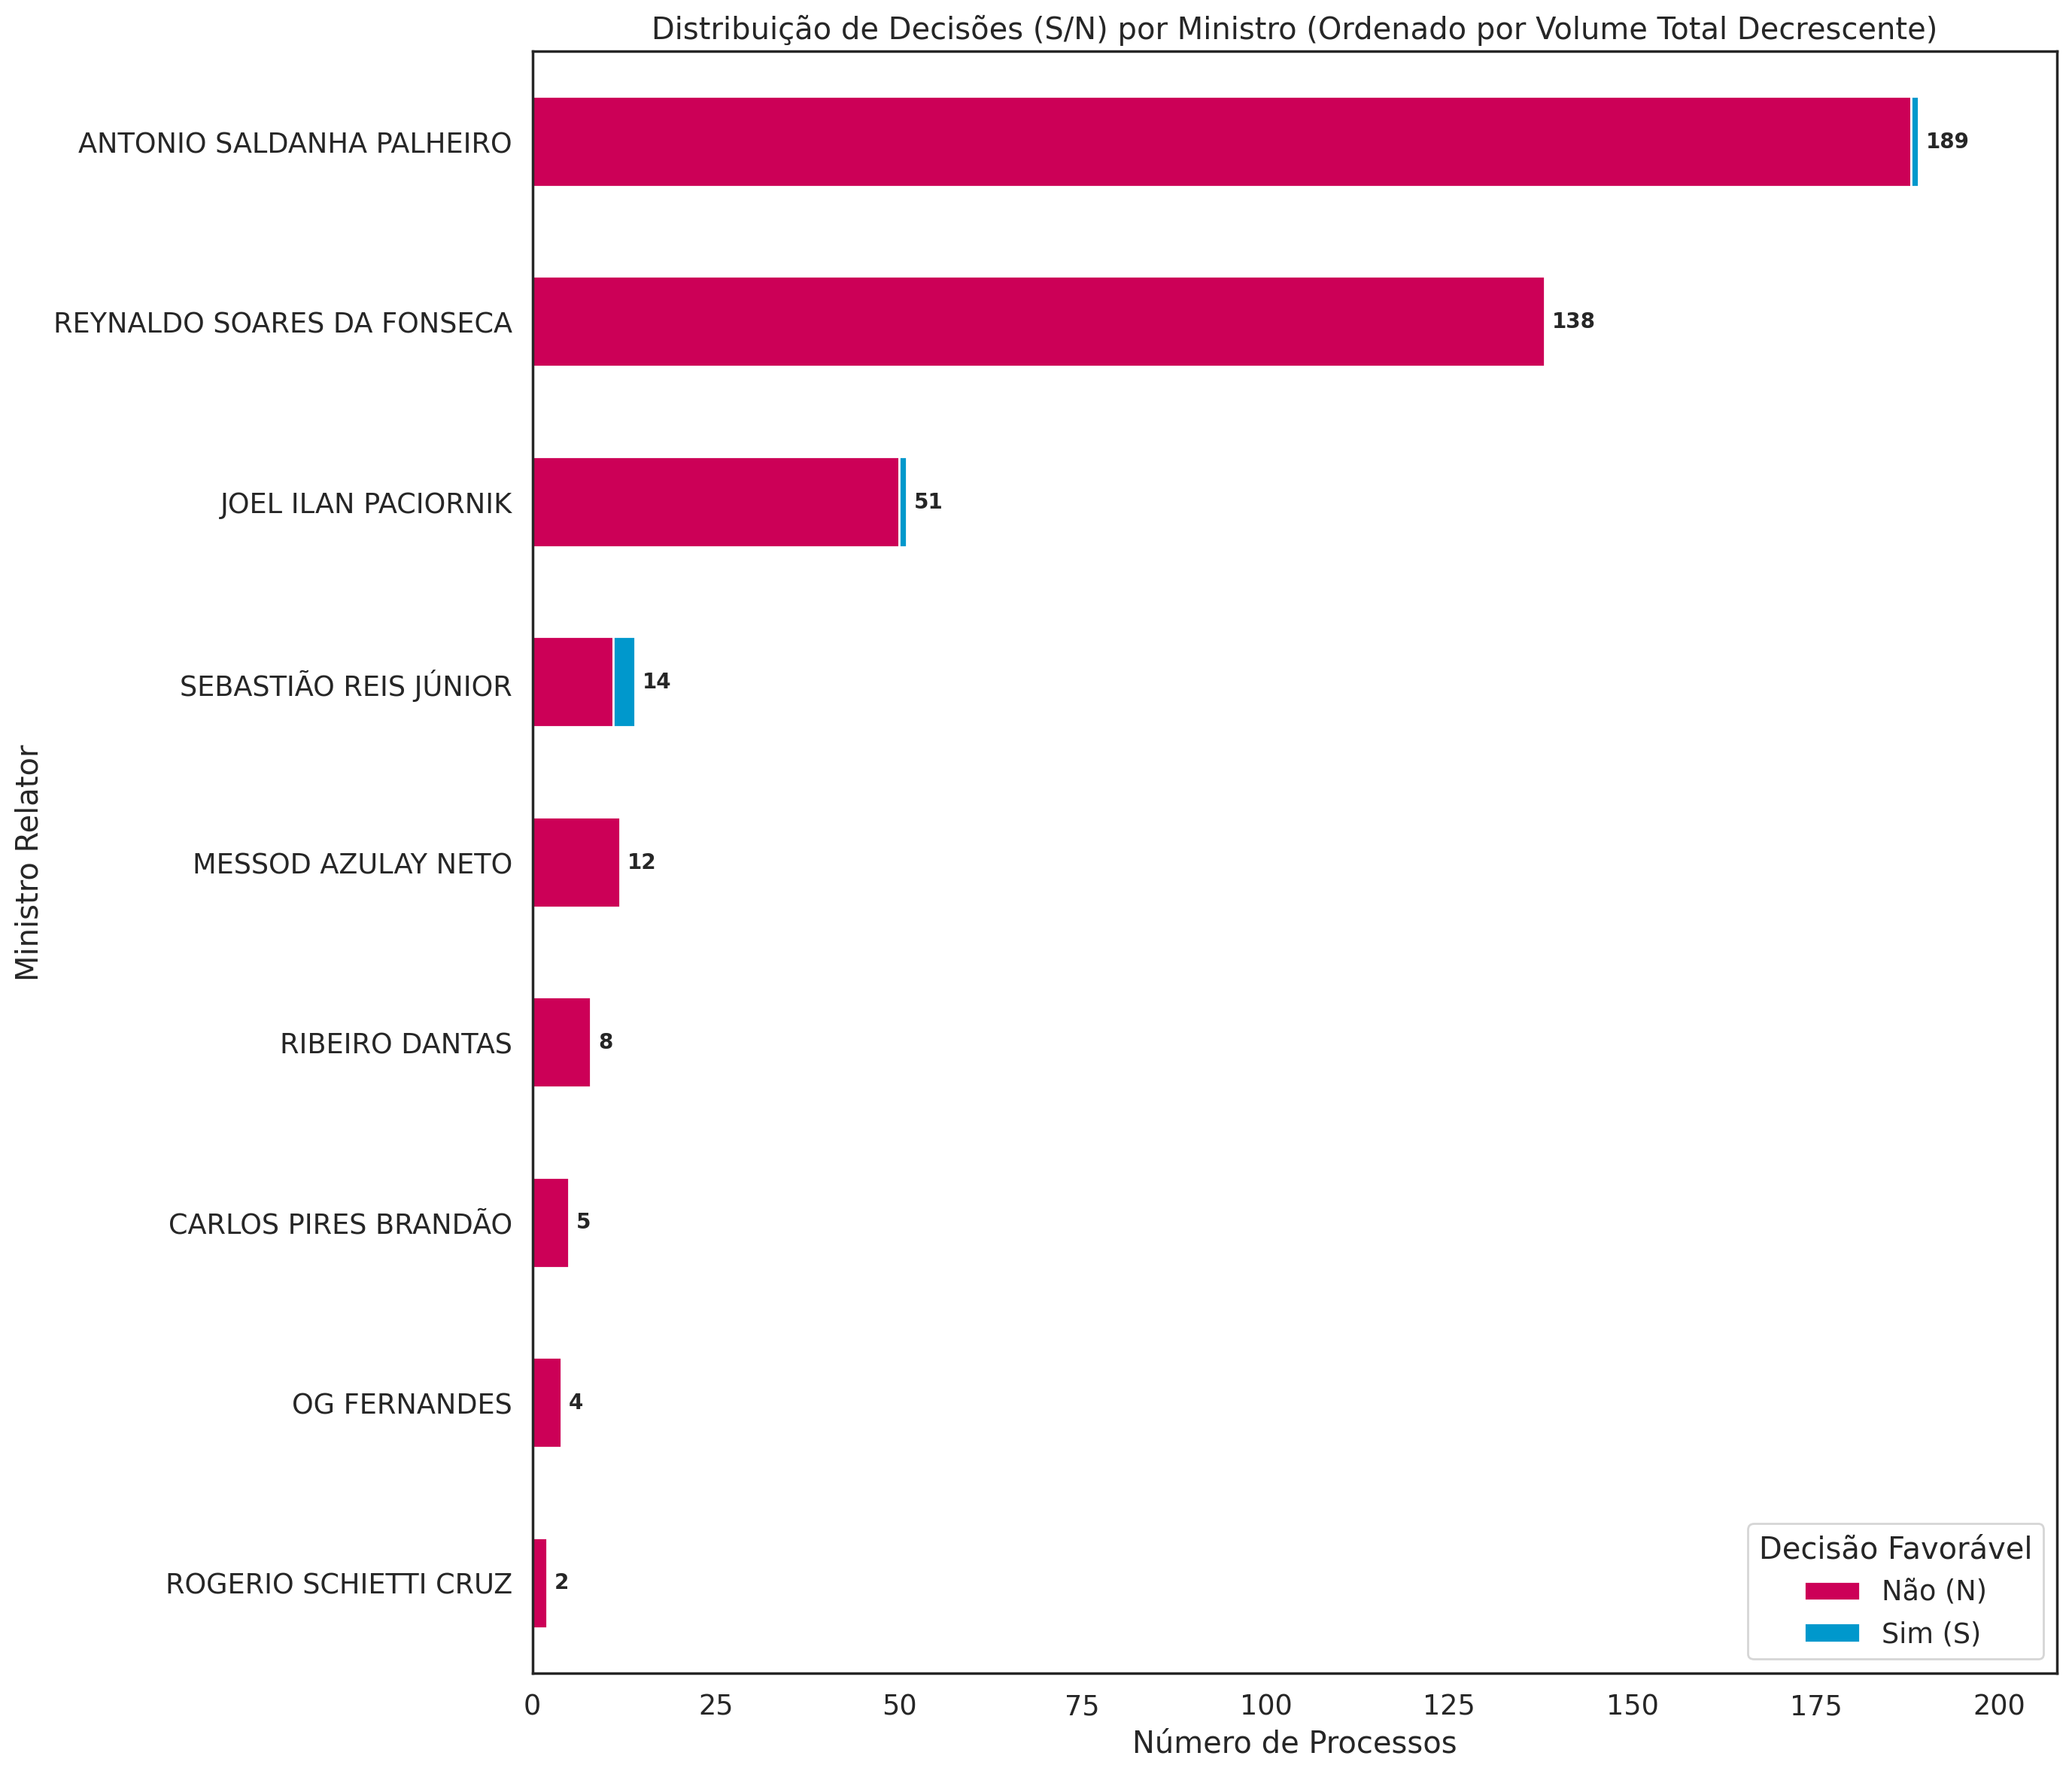

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

minister_col = 'MINISTRO'

# Calculando os totais para ordenar o gráfico de barras empilhadas de forma DECRESCENTE
minister_totals = df.groupby(minister_col).size().sort_values(ascending=False)

# Reordenando o dataframe de distribuição com base nos totais (invertendo a ordem para o gráfico de barras horizontais subir o maior)
# No matplotlib barh, o primeiro item do index fica na base, então invertemos para o maior ficar no topo
minister_decision_dist = df.groupby([minister_col, 'DECISAO_FAVORAVEL']).size().unstack(fill_value=0)
minister_decision_dist = minister_decision_dist.reindex(minister_totals.index[::-1])
ordered_totals = minister_totals.iloc[::-1]

# Plotagem
plt.figure(figsize=(14, 12))
ax = minister_decision_dist.plot(kind='barh', stacked=True, color=['#CC0057', '#0098CC'], ax=plt.gca())

# Adicionando rótulos de totais ao final de cada barra
for i, (name, total) in enumerate(ordered_totals.items()):
    ax.text(total + 1, i, f'{int(total)}', va='center', fontsize=10, fontweight='bold')

plt.title('Distribuição de Decisões (S/N) por Ministro (Ordenado por Volume Total Decrescente)')
plt.xlabel('Número de Processos')
plt.ylabel('Ministro Relator')
plt.legend(title='Decisão Favorável', labels=['Não (N)', 'Sim (S)'], loc='lower right')

# Ajuste de limite do eixo X para acomodar os labels
plt.xlim(0, minister_totals.max() * 1.1)

plt.tight_layout()
plt.show()

In [ ]:
# Function para converter a decisão em num valor contínuo
def cast_decisao_to_int(decisao_favoravel):

    # Convert to class
    if decisao_favoravel == 'S':
        return 1
    else:
        return 0

# Apply to the dataset
df['classe'] = df.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)

In [ ]:
df['classe'].value_counts()

,count
classe,
0,418
1,5


In [ ]:
# O pré-processamento textual já foi realizado, porém, se for necessário remover
#   a pontuação (no caso de testes com modelos rasos), o pré-processamento pode
#   ser acionando novamente com o parâmetro mantem_pontuacao = 'N'.

%run "{BASE_PATH_GENERAL}libs/preprocessing.ipynb"

version 1.08.0


In [ ]:
import multiprocessing
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm # For tqdm progress bars
import pandas as pd
import numpy as np # For np.array_split

# REDEFINIÇÃO DA FUNÇÃO apply_pre_processing_parallel PARA CORRIGIR O ERRO
def apply_pre_processing_parallel(df_series, remover_stopwords):
    num_cores = multiprocessing.cpu_count()
    print(f"\nUtilizando {num_cores} threads para o pré-processamento paralelo...")

    # CORREÇÃO: Divida os índices posicionais (0 a N-1) em vez dos rótulos do índice.
    # Isso garante que .iloc receba posições válidas, independentemente do índice original do DataFrame.
    split_indices = np.array_split(range(len(df_series)), num_cores)

    # Agora, use esses pedaços de índice posicionais com .iloc para obter os pedaços de dados reais
    chunks = [df_series.iloc[idx] for idx in split_indices]

    results_list = []
    with ThreadPoolExecutor(max_workers=num_cores) as executor:
        futures = {}
        for i, chunk in enumerate(chunks):
            def process_single_chunk_with_progress(sub_chunk, chunk_id_for_desc):
                processed_sub_chunk_values = []
                for item in tqdm(sub_chunk.values, desc=f"Thread {chunk_id_for_desc}", position=chunk_id_for_desc):
                    # Garante que `pre_processamento` esteja definida e acessível
                    processed_sub_chunk_values.append(pre_processamento(item, remover_stopwords))
                return pd.Series(processed_sub_chunk_values, index=sub_chunk.index)

            future = executor.submit(process_single_chunk_with_progress, chunk, i)
            futures[future] = i

        for future in tqdm(as_completed(futures), total=len(futures), desc="Coletando Resultados", position=num_cores):
            results_list.append(future.result())

    processed_series = pd.concat(results_list).sort_index()
    return processed_series

In [ ]:
# Aplicando o pré-processamento de forma otimizada com threads e barra de progresso
df['RELATORIO'] = apply_pre_processing_parallel(df['RELATORIO'], False)

print("Pré-processamento do campo RELATORIO concluído com sucesso.")


Utilizando 2 threads para o pré-processamento paralelo...


Thread 0:   0%|          | 0/212 [00:00<?, ?it/s]

Thread 1:   0%|          | 0/211 [00:00<?, ?it/s]

Coletando Resultados:   0%|          | 0/2 [00:00<?, ?it/s]

Pré-processamento do campo RELATORIO concluído com sucesso.


##Mapear a quantidade de tokens do campo RELATORIO

## Fase 01 - Tokenização

Realizar com GPU

In [ ]:
def count_tokens_by_report(df_tokenization):
  from transformers import AutoTokenizer
  import pandas as pd
  import numpy as np
  from concurrent.futures import ThreadPoolExecutor, as_completed
  import multiprocessing
  from tqdm.auto import tqdm

  MODEL_CHECKPOINT = 'raquelsilveira/legalbertpt_fp'

  print(f"Carregando tokenizador do modelo: {MODEL_CHECKPOINT}...")
  try:
      tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
      print("Tokenizador carregado com sucesso!")

      def count_tokens_chunk(chunk, chunk_id):
          """Conta tokens em um chunk de dados com barra de progresso."""
          tqdm.pandas(desc=f"Thread {chunk_id}", leave=False)

          def get_token_len(text):
              if not isinstance(text, str):
                  return 0
              return len(tokenizer.encode(text, add_special_tokens=True))

          return chunk.progress_apply(get_token_len)

      print("Iniciando a contagem de tokens com processamento paralelo...")

      # Determina o número de threads com base nos núcleos da CPU
      num_cores = multiprocessing.cpu_count()
      print(f"Utilizando {num_cores} threads para o processamento.")

      # Divide o DataFrame em chunks para processamento paralelo
      chunks = np.array_split(df_tokenization['RELATORIO'], num_cores)

      results = []
      with ThreadPoolExecutor(max_workers=num_cores) as executor:
          # Submete as tarefas para as threads
          futures = {executor.submit(count_tokens_chunk, chunk, i): i for i, chunk in enumerate(chunks)}

          # Coleta os resultados assim que terminarem
          for future in tqdm(as_completed(futures), total=len(futures), desc="Progresso Geral"):
              results.append(future.result())

      # Combina os resultados de volta na ordem original e adiciona ao DataFrame principal
      df_tokenization['NUM_TOKENS_RELATORIO'] = pd.concat(results).sort_index()

      print("Contagem concluída!")
      display(df_tokenization[['RELATORIO', 'NUM_TOKENS_RELATORIO']].head())

      print("\nEstatísticas da quantidade de tokens:")
      print(df_tokenization['NUM_TOKENS_RELATORIO'].describe())

  except Exception as e:
      print(f"Erro ao processar: {e}")

In [ ]:
# if 'NUM_TOKENS_RELATORIO' in df.columns:
#     print("Coluna 'NUM_TOKENS_RELATORIO' encontrada no DataFrame. Não haverá necessidade de realizar o contabilizar a quantidade de TOKENS.")
# else:

# Fazer o tokeização sobre o dataset geral para fins de Análise Exploratória de Dados

print("Contabilizando TOKENS...")

#p_df = df

p_df = df.copy()

count_tokens_by_report(p_df)

Contabilizando TOKENS...
Carregando tokenizador do modelo: raquelsilveira/legalbertpt_fp...


config.json:   0%|          | 0.00/863 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

Tokenizador carregado com sucesso!
Iniciando a contagem de tokens com processamento paralelo...
Utilizando 12 threads para o processamento.


...

Progresso Geral:   0%|          | 0/12 [00:00<?, ?it/s]

Thread 0:   0%|          | 0/36 [00:00<?, ?it/s]

Contagem concluída!


,RELATORIO,NUM_TOKENS_RELATORIO
0,Trata-se de embargos de declaração opostos por...,906
1,Trata-se de agravo regimental interposto por E...,3824
2,Trata-se de habeas corpus impetrado em favor d...,2004
3,Trata-se de embargos de declaração opostos pel...,1241
4,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,1090



Estatísticas da quantidade de tokens:
count     423.000000
mean     1511.061466
std       925.085492
min       741.000000
25%      1017.000000
50%      1188.000000
75%      1610.000000
max      9063.000000
Name: NUM_TOKENS_RELATORIO, dtype: float64


In [ ]:
# Fix: Use np.where for element-wise conditional assignment
df['TEXTO_LONGO'] = np.where(df['NUM_TOKENS_RELATORIO'] > 510, 'S', 'N')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423 entries, 0 to 422
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   SEQDOCUMENTO                 423 non-null    int64 
 1   DATAPUBLICACAO               423 non-null    object
 2   TIPODOCUMENTO                423 non-null    object
 3   NUMEROREGISTRO               423 non-null    int64 
 4   DATARECEBIMENTO              423 non-null    object
 5   DATADISTRIBUICAO             423 non-null    object
 6   MINISTRO                     423 non-null    object
 7   RECURSO                      409 non-null    object
 8   TEOR                         423 non-null    object
 9   ASSUNTOS                     423 non-null    object
 10  NUM_DIAS_CONCLUSAO_PROCESSO  423 non-null    int64 
 11  TIPOPROCESSO                 423 non-null    object
 12  NUMEROPROCESSO               423 non-null    int64 
 13  DECISAO_FAVORAVEL            423 no

** *fim tokenização* **

###Fase Intermediária (Executar para aproveitar ação já realizada)

In [ ]:
# Habilitar caso o dataset já tenha sido criado.
import pandas as pd

# mount_drive()

# #file_path = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train.csv"
file_path = f"{BASE_PATH_DATASET}dataset_decisoes_acordaos_HC_2021_2025_tokenized.csv"

print(f"Lendo o arquivo CSV em: {file_path}...")
df = pd.read_csv(file_path, sep=';')
# #df_geral = pd.read_csv(file_path, sep=';')

print("Arquivo CSV lido com sucesso!")
#print(f"Shape do DataFrame lido: {df_geral.shape}")
print(f"Shape do DataFrame lido: {df.shape}")

df.info()
#df_geral.info()

### Campos que evidenciam a conclusão da Fase 1:

*   NUM_TOKENS_RELATORIO
*   TEXTO_LONGO
*   ANO_RECEBIMENTO
*   classe


In [ ]:
df_geral['NUM_TOKENS_RELATORIO'].describe()

### Gráficos de Tokens

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.ticker as ticker

def plot_token_distribution(dataset):
    # Configurar tamanho da figura
    plt.figure(figsize=(12, 6))

    # Criar o histograma com linha de densidade (KDE)
    ax = sns.histplot(
        data=dataset,
        x='NUM_TOKENS_RELATORIO',
        bins=100,
        color='#0098CC',
        kde=True,
        edgecolor='black',
        alpha=0.7
    )

    # Calcular quantidades abaixo e acima do limite
    total_abaixo = (dataset['NUM_TOKENS_RELATORIO'] <= 510).sum()
    total_acima = (dataset['NUM_TOKENS_RELATORIO'] > 510).sum()

    # Formatar os números para o padrão brasileiro
    str_abaixo = f"{total_abaixo:,}".replace(',', '.')
    str_acima = f"{total_acima:,}".replace(',', '.')

    # Adicionar a linha destacando o limite do BERT com as quantidades na legenda
    plt.axvline(
        x=512,
        color='#CC0057',
        linestyle='--',
        linewidth=2.5,
        label=f'Limite BERT (512 Tokens)\n≤ 512: {str_abaixo} processos\n> 512: {str_acima} processos'
    )

    # Adicionar a linha indicando o ponto de corte em 130 tokens
    plt.axvline(
        x=130,
        color='#7200CC',
        linestyle=':',
        linewidth=2.5,
        label='Ponto de Corte (130 Tokens)'
    )

    # Adicionar a linha indicando o ponto de corte em 2500 tokens com a mesma cor
    plt.axvline(
        x=2500,
        color='#7200CC',
        linestyle=':',
        linewidth=2.5,
        label='Ponto de Corte (2500 Tokens)'
    )

    # Calcular as métricas adicionais (usando o dataset completo)
    min_tokens = dataset['NUM_TOKENS_RELATORIO'].min()
    max_tokens = dataset['NUM_TOKENS_RELATORIO'].max()
    mean_tokens = dataset['NUM_TOKENS_RELATORIO'].mean()
    median_tokens = dataset['NUM_TOKENS_RELATORIO'].median()

    # Adicionar linha destacando a Média
    plt.axvline(
        x=mean_tokens,
        color='#8ACC02',
        linestyle='-',
        linewidth=2.5,
        label=f'Média ({mean_tokens:.1f})'
    )

    # Adicionar linha destacando a Mediana
    plt.axvline(
        x=median_tokens,
        color='#CCA100',
        linestyle='-.',
        linewidth=2.5,
        label=f'Mediana ({median_tokens:.1f})'
    )

    # Formatar mínimos e máximos com o separador de milhar brasileiro
    str_min = f"{min_tokens:,}".replace(',', '.')
    str_max = f"{max_tokens:,}".replace(',', '.')

    # Adicionar métricas de Mínimo e Máximo na legenda (como entradas invisíveis)
    plt.plot([], [], ' ', label=f'Mínimo: {str_min}')
    plt.plot([], [], ' ', label=f'Máximo: {str_max}')

    # Customizações para o artigo científico
    plt.title('Tokens per HC Proceeding Distribution', fontsize=14, pad=15, fontweight='bold')
    plt.xlabel('') # Definido explicitamente como vazio para remover 'NUM_TOKENS_RELATORIO'
    plt.ylabel('Frequência (Quantidade de Processos)', fontsize=12)

    # Formatar o eixo Y com separador de milhar brasileiro tradicional (idêntico ao gráfico de linhas)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}".replace(',', '.')))

    # Ajustar limite visual do eixo X para exibir exatamente até 3000 tokens
    plt.xlim(0, 5000)

    # Definir intervalos de escala de 250 em 250 no eixo X
    plt.xticks(np.arange(0, 5001, 250))

    # Configurar legenda e grid
    plt.legend(fontsize=11, loc='upper right')
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Ajustar layout para não cortar elementos
    plt.tight_layout()

    # Exibir o gráfico
    plt.show()

# Chamada da função com o dataframe desejado
#plot_token_distribution(df_geral)

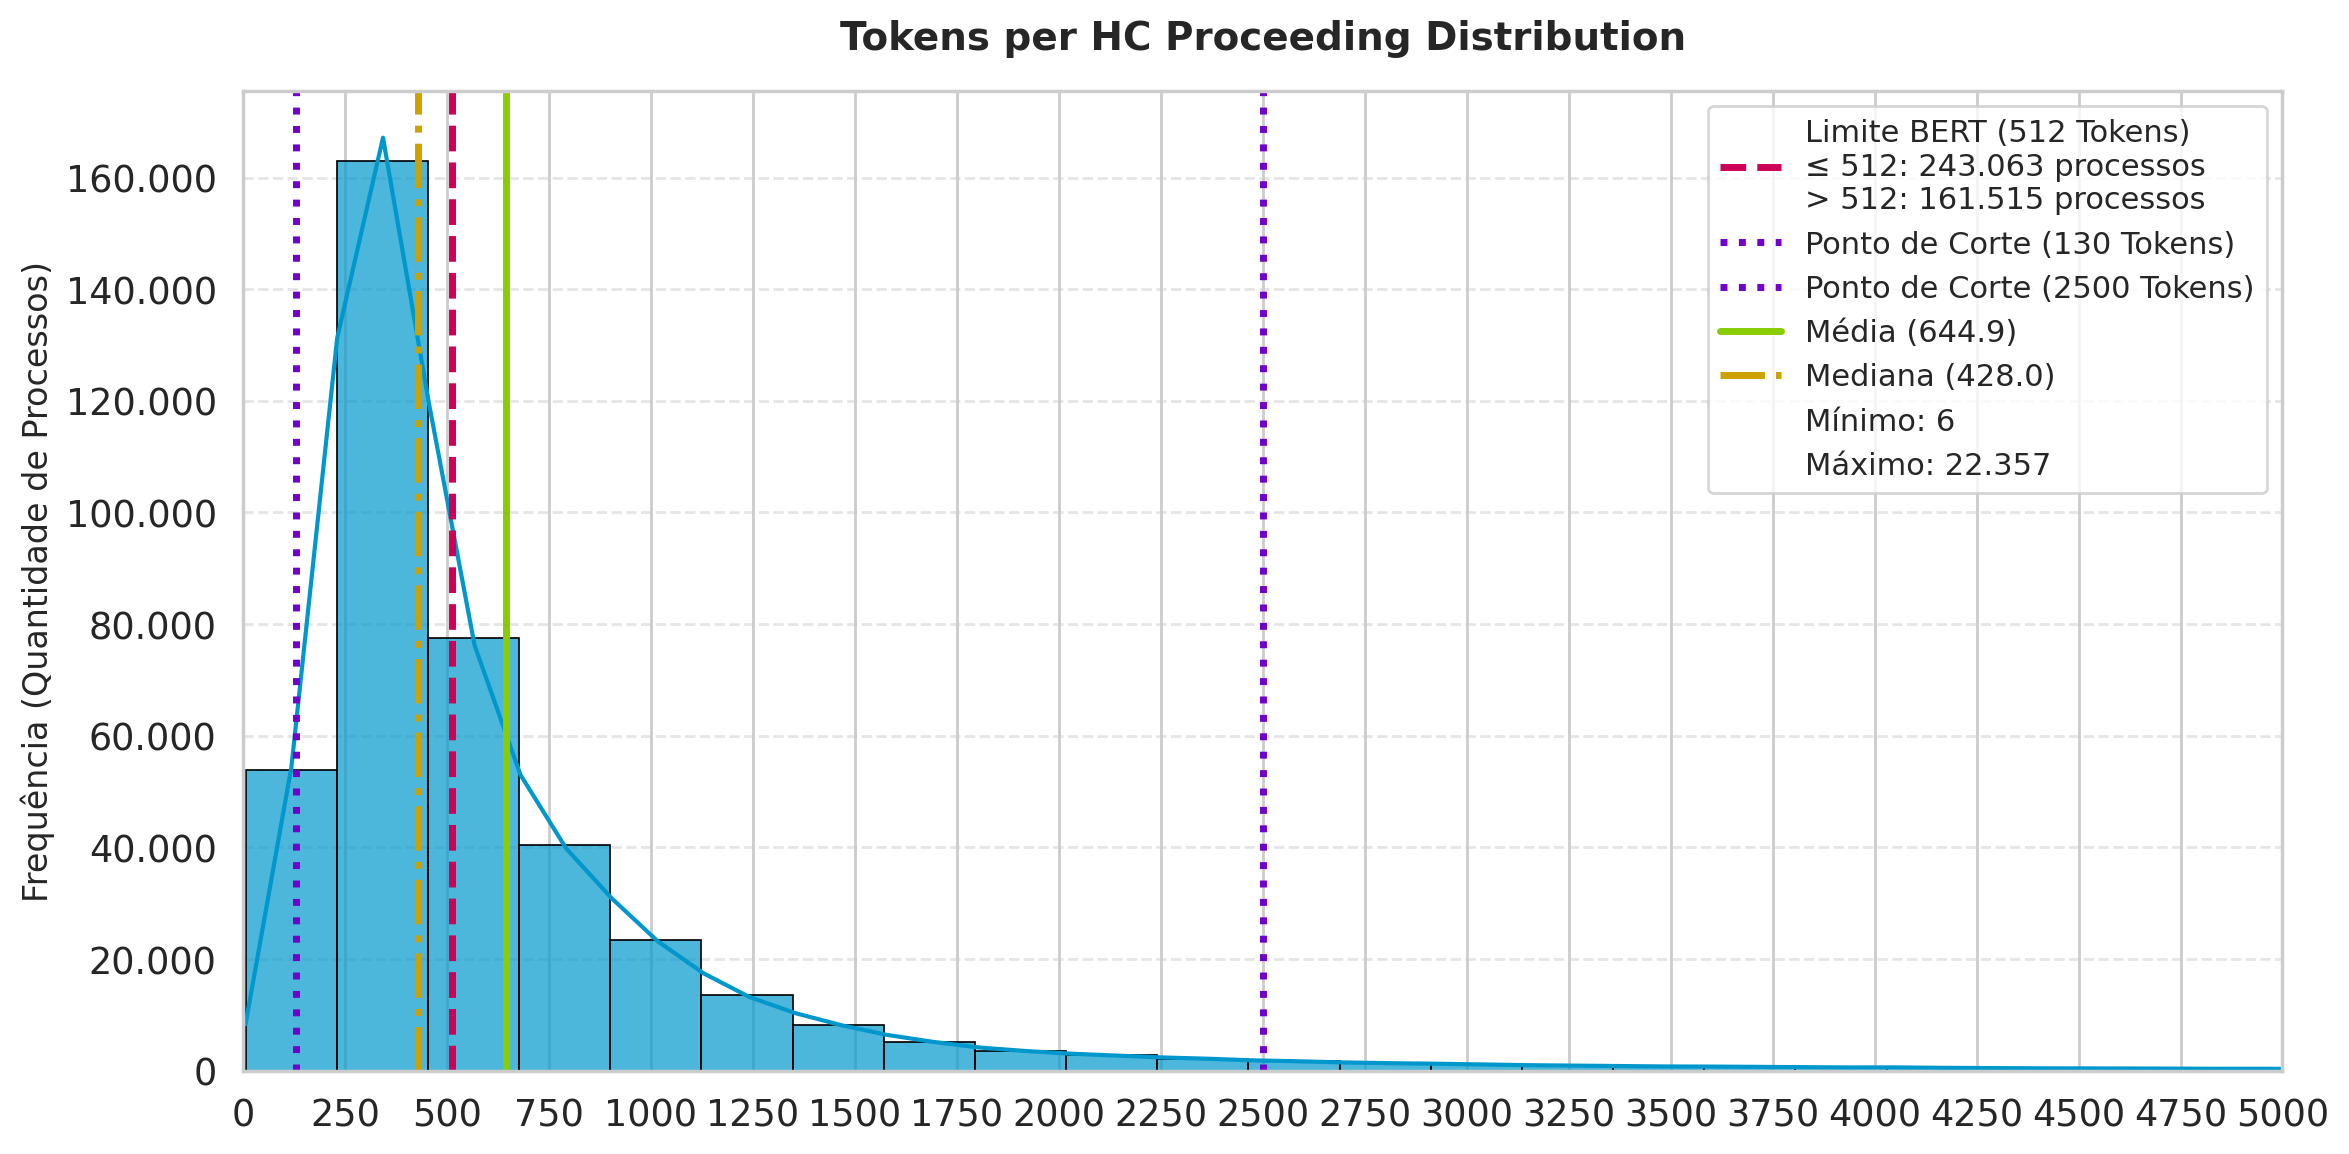

In [ ]:

# Chamada da função com o dataframe desejado
plot_token_distribution(df)

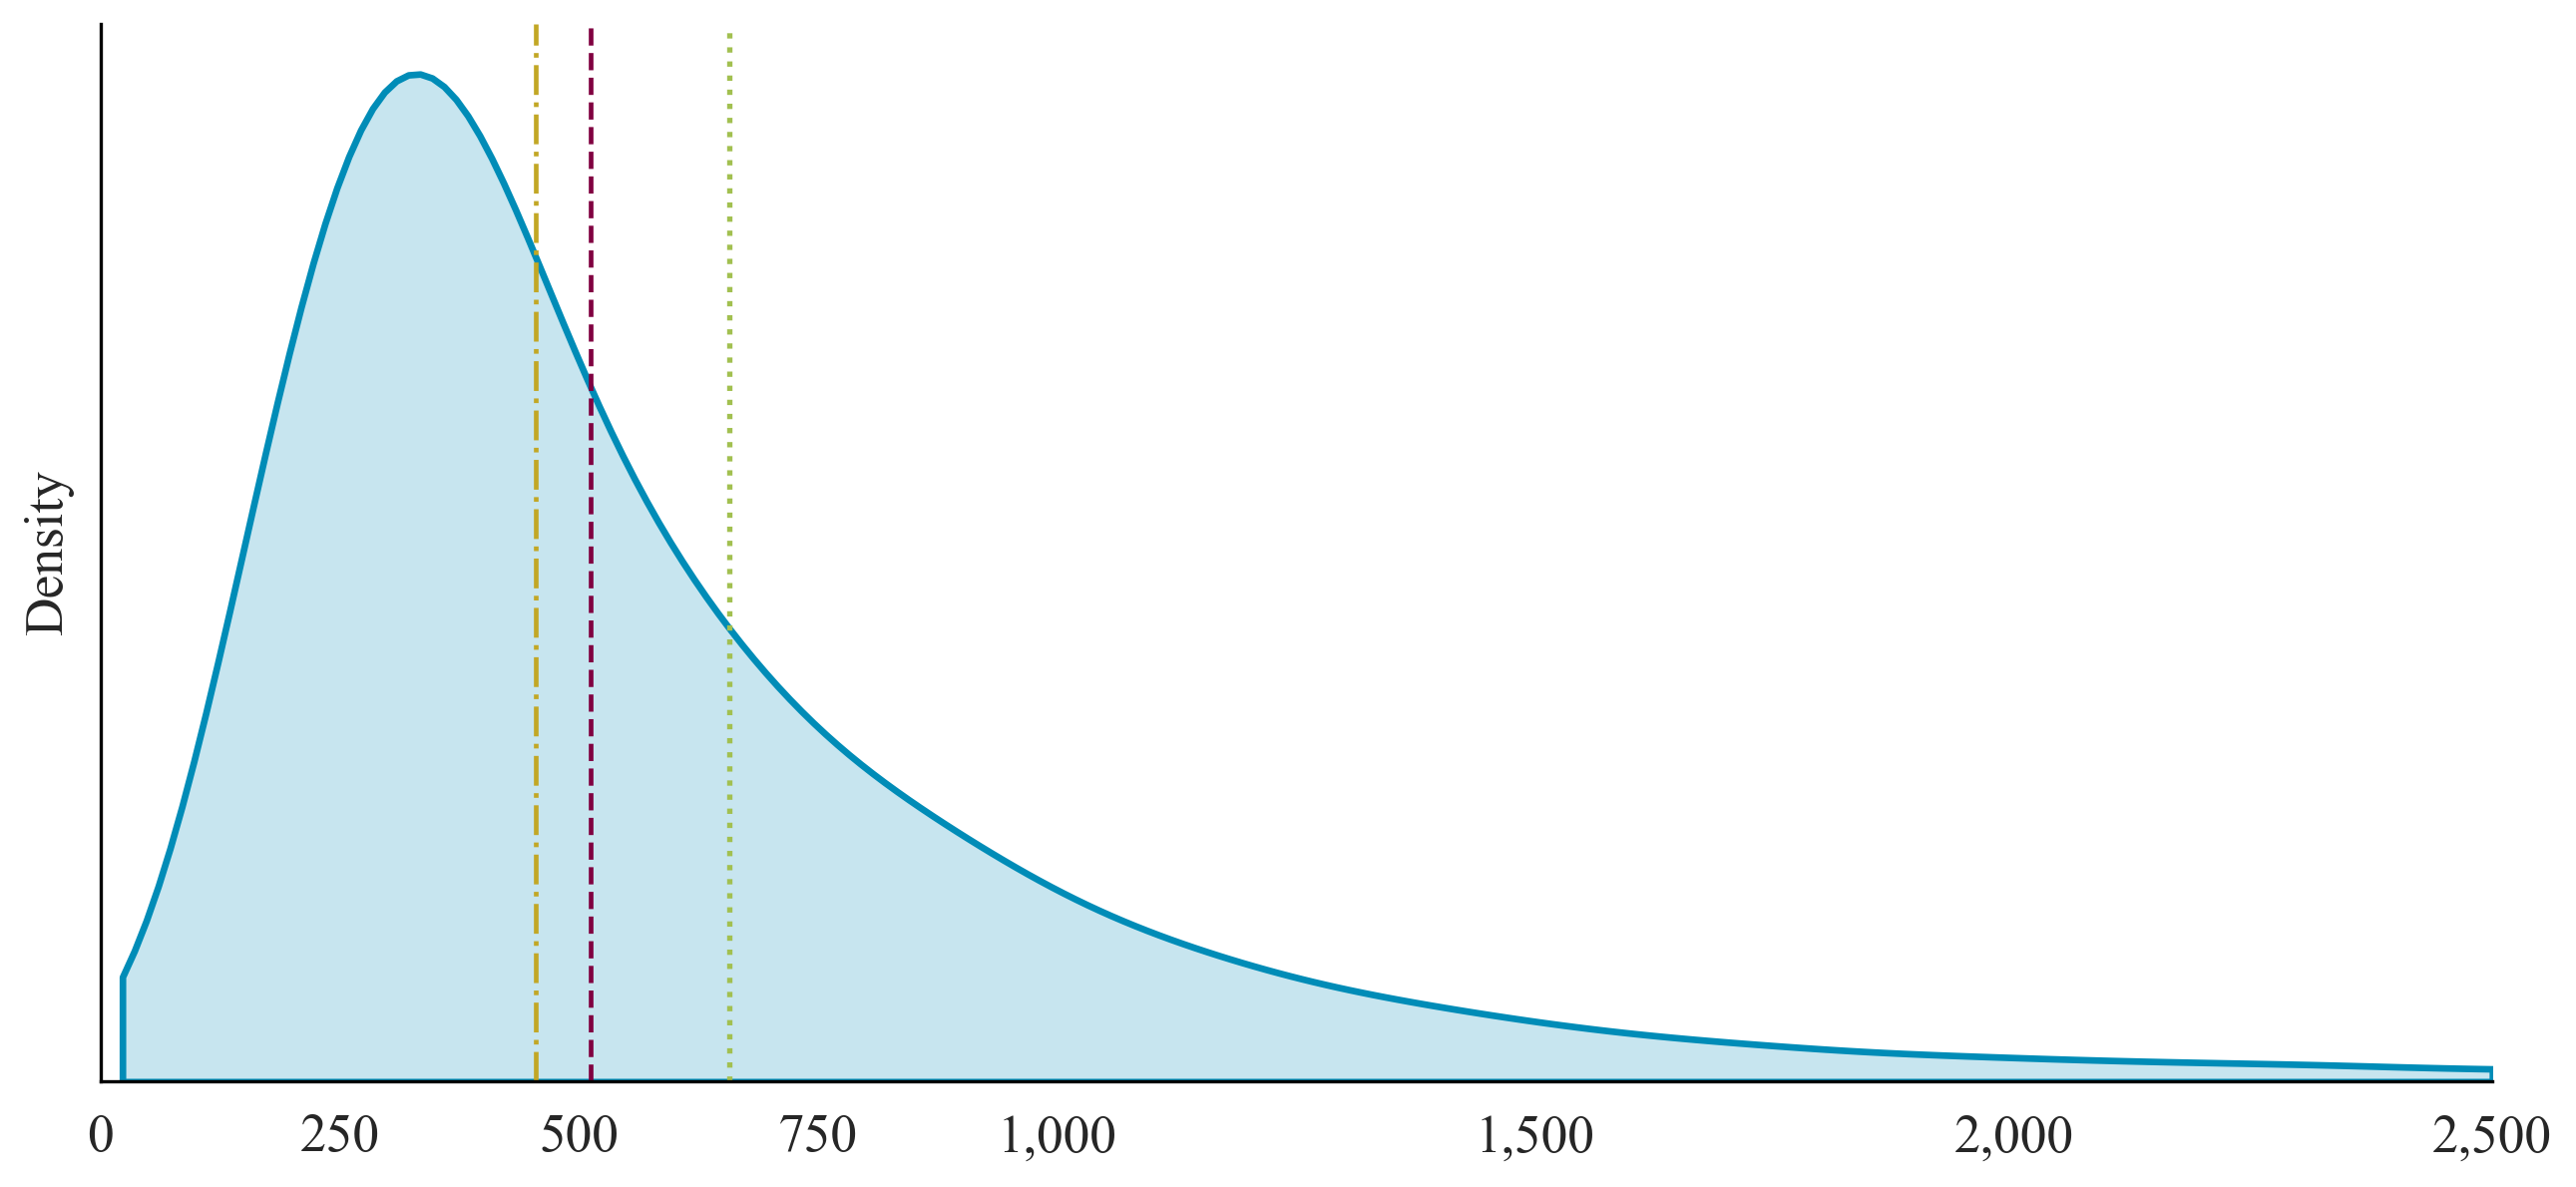

In [ ]:
def plot_token_distribution(dataset):

    vFONT_SIZE = FONT_SIZE-8

    from matplotlib.lines import Line2D

    # 1. Configuração do ambiente visual
    sns.set_style("white")

    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman']
    })

    tokens = dataset['NUM_TOKENS_RELATORIO'].dropna()

    # 2. Estatísticas Reais
    min_val = int(tokens.min())
    max_val = int(tokens.max())
    median_val = float(np.median(tokens))
    mean_val = float(np.mean(tokens))
    bert_limit = 512

    fig, ax = plt.subplots(figsize=(11, 5.2), dpi=120)

    # 3. KDE idêntico: clip=(0, None) e cut=0 eliminam a distorção abaixo de zero
    sns.kdeplot(
        tokens,
        fill=True,
        color="#008cb7",       # Azul primário da linha
        alpha=0.22,            # Transparência suave do preenchimento
        linewidth=2.0,
        bw_adjust=1.3,         # Suaviza a curvatura do topo sem achatar
        clip=(0, 2500),        # Prende a distribuição na janela visual exata
        cut=0,                 # Não projeta cauda além dos limites
        ax=ax
    )

    # 4. Linhas de corte verticais (cores e traços idênticos à referência)
    ax.axvline(median_val, color="#c2a725", linestyle="-.", linewidth=1.4) # Mediana (mostarda/ouro)
    ax.axvline(bert_limit, color="#800040", linestyle="--", linewidth=1.4) # BERT Limit (vinho)
    ax.axvline(mean_val, color="#a2c050", linestyle=":", linewidth=1.6)    # Média (verde-oliva)

    if SHOW_LEGEND:
      # 5. Legenda com elementos customizados
      legend_elements = [
          Line2D([0], [0], color='none', label=f'Minimum: {min_val:,}'),
          Line2D([0], [0], color='#c2a725', linestyle='-.', linewidth=1.4, label=f'Median: {median_val:.1f}'),
          Line2D([0], [0], color='#800040', linestyle='--', linewidth=1.4, label='BERT Limit'),
          Line2D([0], [0], color='#a2c050', linestyle=':', linewidth=1.6, label=f'Mean: {mean_val:.1f}'),
          Line2D([0], [0], color='none', label=f'Maximum: {max_val:,}')
      ]

      ax.legend(
          handles=legend_elements,
          loc='upper right',
          frameon=True,
          edgecolor='black',
          facecolor='white',
          framealpha=1.0,
          fontsize=vFONT_SIZE-2,
          handlelength=2.5,
          borderpad=0.7,
          labelspacing=0.5
      )

    # 6. Configuração manual dos Ticks do Eixo X (padrão híbrido da imagem)
    x_ticks = [0, 250, 500, 750, 1000, 1500, 2000, 2500]
    x_labels = ['0', '250', '500', '750', '1,000', '1,500', '2,000', '2,500']
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels, fontsize=vFONT_SIZE)
    ax.set_xlim(0, 2500)

    # 7. Ajuste do Eixo Y e eliminação de folgas
    ax.set_ylim(bottom=0)
    ax.set_yticks([])
    ax.set_ylabel('Density', fontsize=vFONT_SIZE, labelpad=8)
    ax.set_xlabel('')

    # Mantém apenas as linhas pretas inferior e esquerda (spines)
    sns.despine(ax=ax, top=True, right=True, left=False, bottom=False)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')
    ax.spines['left'].set_linewidth(1.0)
    ax.spines['bottom'].set_linewidth(1.0)

    plt.tight_layout()

    if SAVE_GRAPHIC:
      plt.savefig(f"{BASE_PATH_GRAPHIC}density_kde_token_report.pdf", format='pdf', bbox_inches='tight', dpi=DPI_RESOLUTION)

    plt.show()

# Para rodar:
plot_token_distribution(df)

In [ ]:
SAVE_GRAPHIC = True

#### plot_token_distribution_adapted

Graphic saved.


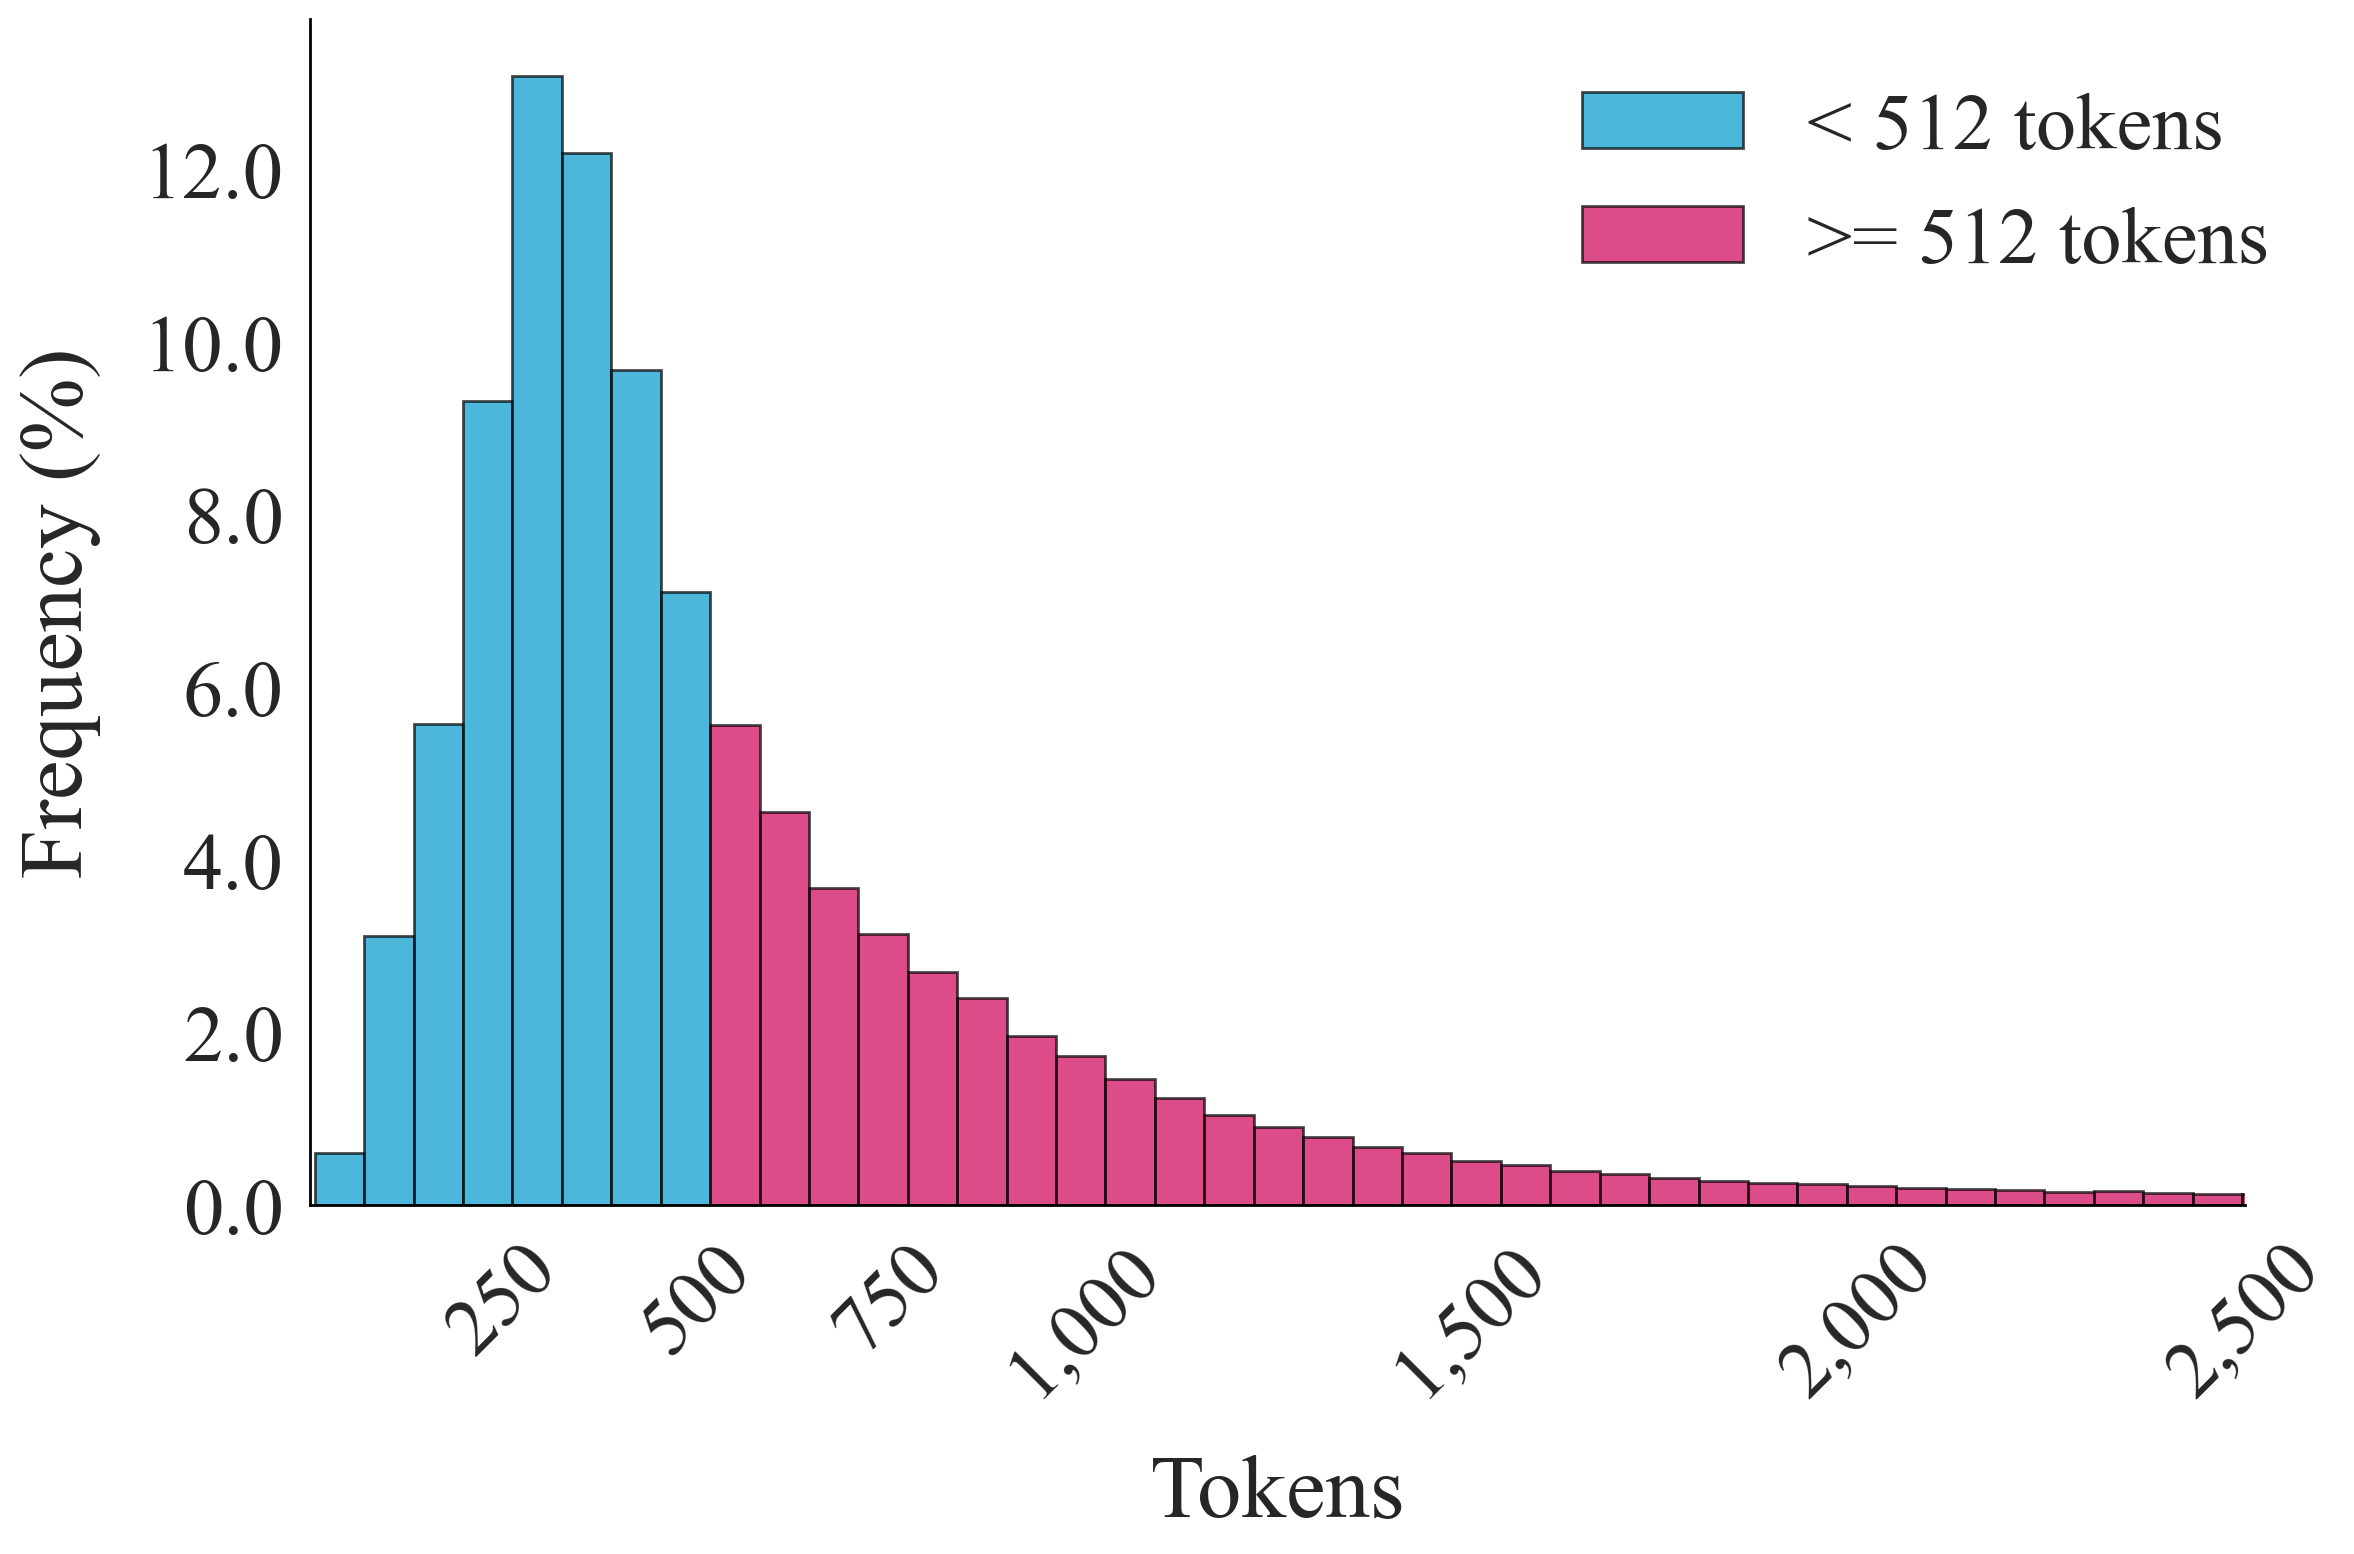

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.ticker as ticker
from matplotlib.patches import Patch

def plot_token_distribution_adapted(dataset, f_font_size=12, nbins=300):
    plt.figure(figsize=(12, 8))

    # Configurando o estilo global para Times New Roman
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman']
    })

    # Gerando os dados para o histograma manualmente
    counts, bins = np.histogram(dataset['NUM_TOKENS_RELATORIO'].dropna(), bins=nbins)

    # Convertendo as contagens absolutas para percentuais
    total_counts = counts.sum()
    percentages = (counts / total_counts) * 100

    # Plotando barra por barra verticalmente (bar) - Invertendo os eixos
    for i in range(len(percentages)):
        left = bins[i]
        right = bins[i+1]
        width = right - left
        # Se o centro do bin for maior que 512, usa a cor de destaque
        color = '#CC0057' if (left + right)/2 >= 512 else '#0098CC'
        plt.bar(left, percentages[i], width=width, color=color, edgecolor='black', alpha=0.7, align='edge')

    # Customizações estéticas ajustadas para eixos invertidos
    plt.title('')
    plt.xlabel('Tokens', fontsize=(f_font_size), labelpad=15)
    plt.ylabel('Frequency (%)', fontsize=f_font_size, labelpad=15)

    ax = plt.gca()
    ax.tick_params(axis='x', which='major', labelsize=(f_font_size-3))
    ax.tick_params(axis='y', which='major', labelsize=(f_font_size-3))

    # Configuração do eixo Y para exibir apenas o valor numérico (sem o símbolo '%')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

    # Ajustando o limite do eixo X para o padrão (2500)
    ax.set_xlim(0, 2500)

    # Configuração manual dos Ticks do Eixo X com rotação de 45 graus
    x_ticks = [0, 250, 500, 750, 1000, 1500, 2000, 2500]
    x_labels = ['', '250', '500', '750', '1,000', '1,500', '2,000', '2,500']
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels, fontsize=(f_font_size-3), rotation=45)

    # Criando elementos de legenda com o box colorido de volta (sem borda na legenda global)
    legend_elements = [
        Patch(facecolor='#0098CC', edgecolor='black', alpha=0.7, label='< 512 tokens'),
        Patch(facecolor='#CC0057', edgecolor='black', alpha=0.7, label='>= 512 tokens')
    ]
    plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.05, 1.0), fontsize=(f_font_size-3), frameon=False, ncol=1)

    # Removendo a grade (grid)
    plt.grid(False)

    # Mantém apenas as linhas pretas inferior e esquerda (spines)
    sns.despine(ax=ax, top=True, right=True, left=False, bottom=False)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')
    ax.spines['left'].set_linewidth(1.0)
    ax.spines['bottom'].set_linewidth(1.0)

    plt.tight_layout()

    if SAVE_GRAPHIC:
        plt.savefig(f"{BASE_PATH_GRAPHIC}histogram_token_report_column.pdf", format='pdf', bbox_inches='tight', dpi=DPI_RESOLUTION)
        print("Graphic saved.")
    plt.show()

# Chamada da função com o dataframe desejado, passando o tamanho da fonte por parâmetro
plot_token_distribution_adapted(df, f_font_size=32, nbins=350)


In [ ]:
# Example usage string to be provided to the user:
SAVE_GRAPHIC = True
SHOW_LEGEND = False
plot_token_distribution(df)

NameError: name 'plot_token_distribution' is not defined

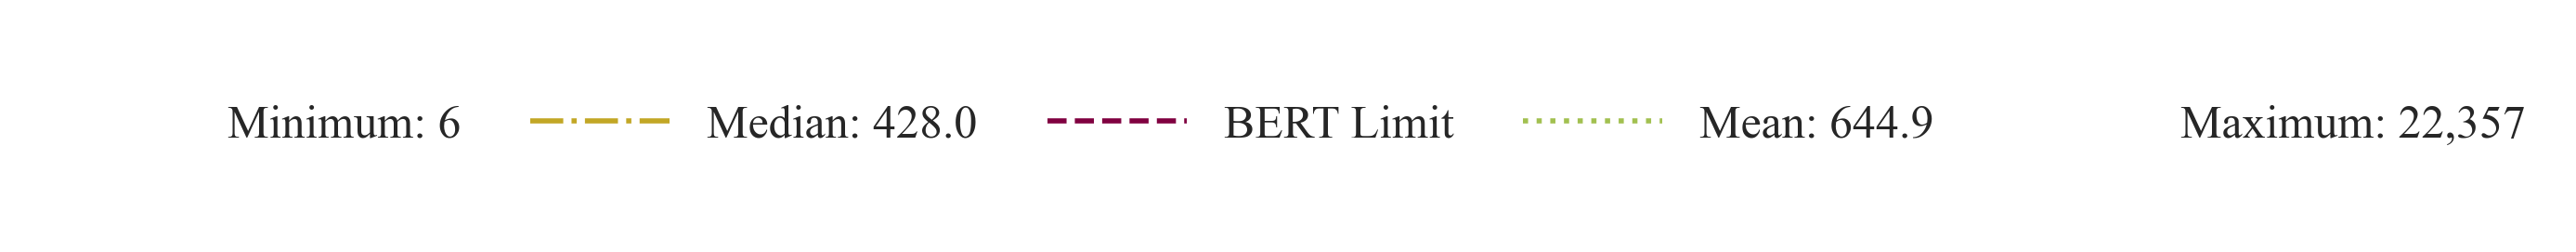

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# 1. Configuração do ambiente visual (mesma do gráfico principal)
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})

# 2. Obter estatísticas atualizadas da base
tokens = df['NUM_TOKENS_RELATORIO'].dropna()
min_val = int(tokens.min())
max_val = int(tokens.max())
median_val = float(np.median(tokens))
mean_val = float(np.mean(tokens))

# Fonte para a legenda externa
vFONT_SIZE = FONT_SIZE - 6

# 3. Criar figura vazia e sem eixos
fig, ax = plt.subplots(figsize=(14, 1.5))
ax.axis('off')

# 4. Construir elementos da legenda de forma idêntica ao gráfico original
legend_elements = [
    Line2D([0], [0], color='none', label=f'Minimum: {min_val:,}'),
    Line2D([0], [0], color='#c2a725', linestyle='-.', linewidth=2.0, label=f'Median: {median_val:.1f}'),
    Line2D([0], [0], color='#800040', linestyle='--', linewidth=2.0, label='BERT Limit'),
    Line2D([0], [0], color='#a2c050', linestyle=':', linewidth=2.0, label=f'Mean: {mean_val:.1f}'),
    Line2D([0], [0], color='none', label=f'Maximum: {max_val:,}')
]

# 5. Plotar a legenda centralizada e horizontal (ncol=5)
leg = ax.legend(
    handles=legend_elements,
    loc='center',
    ncol=5,
    frameon=False,
    fontsize=vFONT_SIZE,
    handlelength=3.0,
    borderpad=0.7,
    columnspacing=1.5
)

if SAVE_GRAPHIC:
    plt.savefig(f"{BASE_PATH_GRAPHIC}density_kde_token_report_legend_standalone.pdf", format='pdf', bbox_inches='tight', dpi=DPI_RESOLUTION)

plt.show()


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_token_boxplot(dataset):
    # Configurar o tamanho da figura para orientação vertical
    plt.figure(figsize=(8, 10))

    # Criar apenas o boxplot na vertical usando o dataset parametrizado
    sns.boxplot(
        y=dataset['NUM_TOKENS_RELATORIO'],
        color='#0098CC',
        flierprops={"marker": "x", "markeredgecolor": "#CC0057"}
    )

    # Limitar o eixo y até 1500 tokens conforme definido
    plt.ylim(0, 1500)

    # Customizações de título e rótulos
    plt.title('Boxplot da Quantidade de Tokens por Processo (Limitado a 1500)', fontsize=14, pad=15, fontweight='bold')
    plt.ylabel('Quantidade de Tokens', fontsize=12)

    # Ajustar layout e exibir
    plt.tight_layout()
    plt.show()

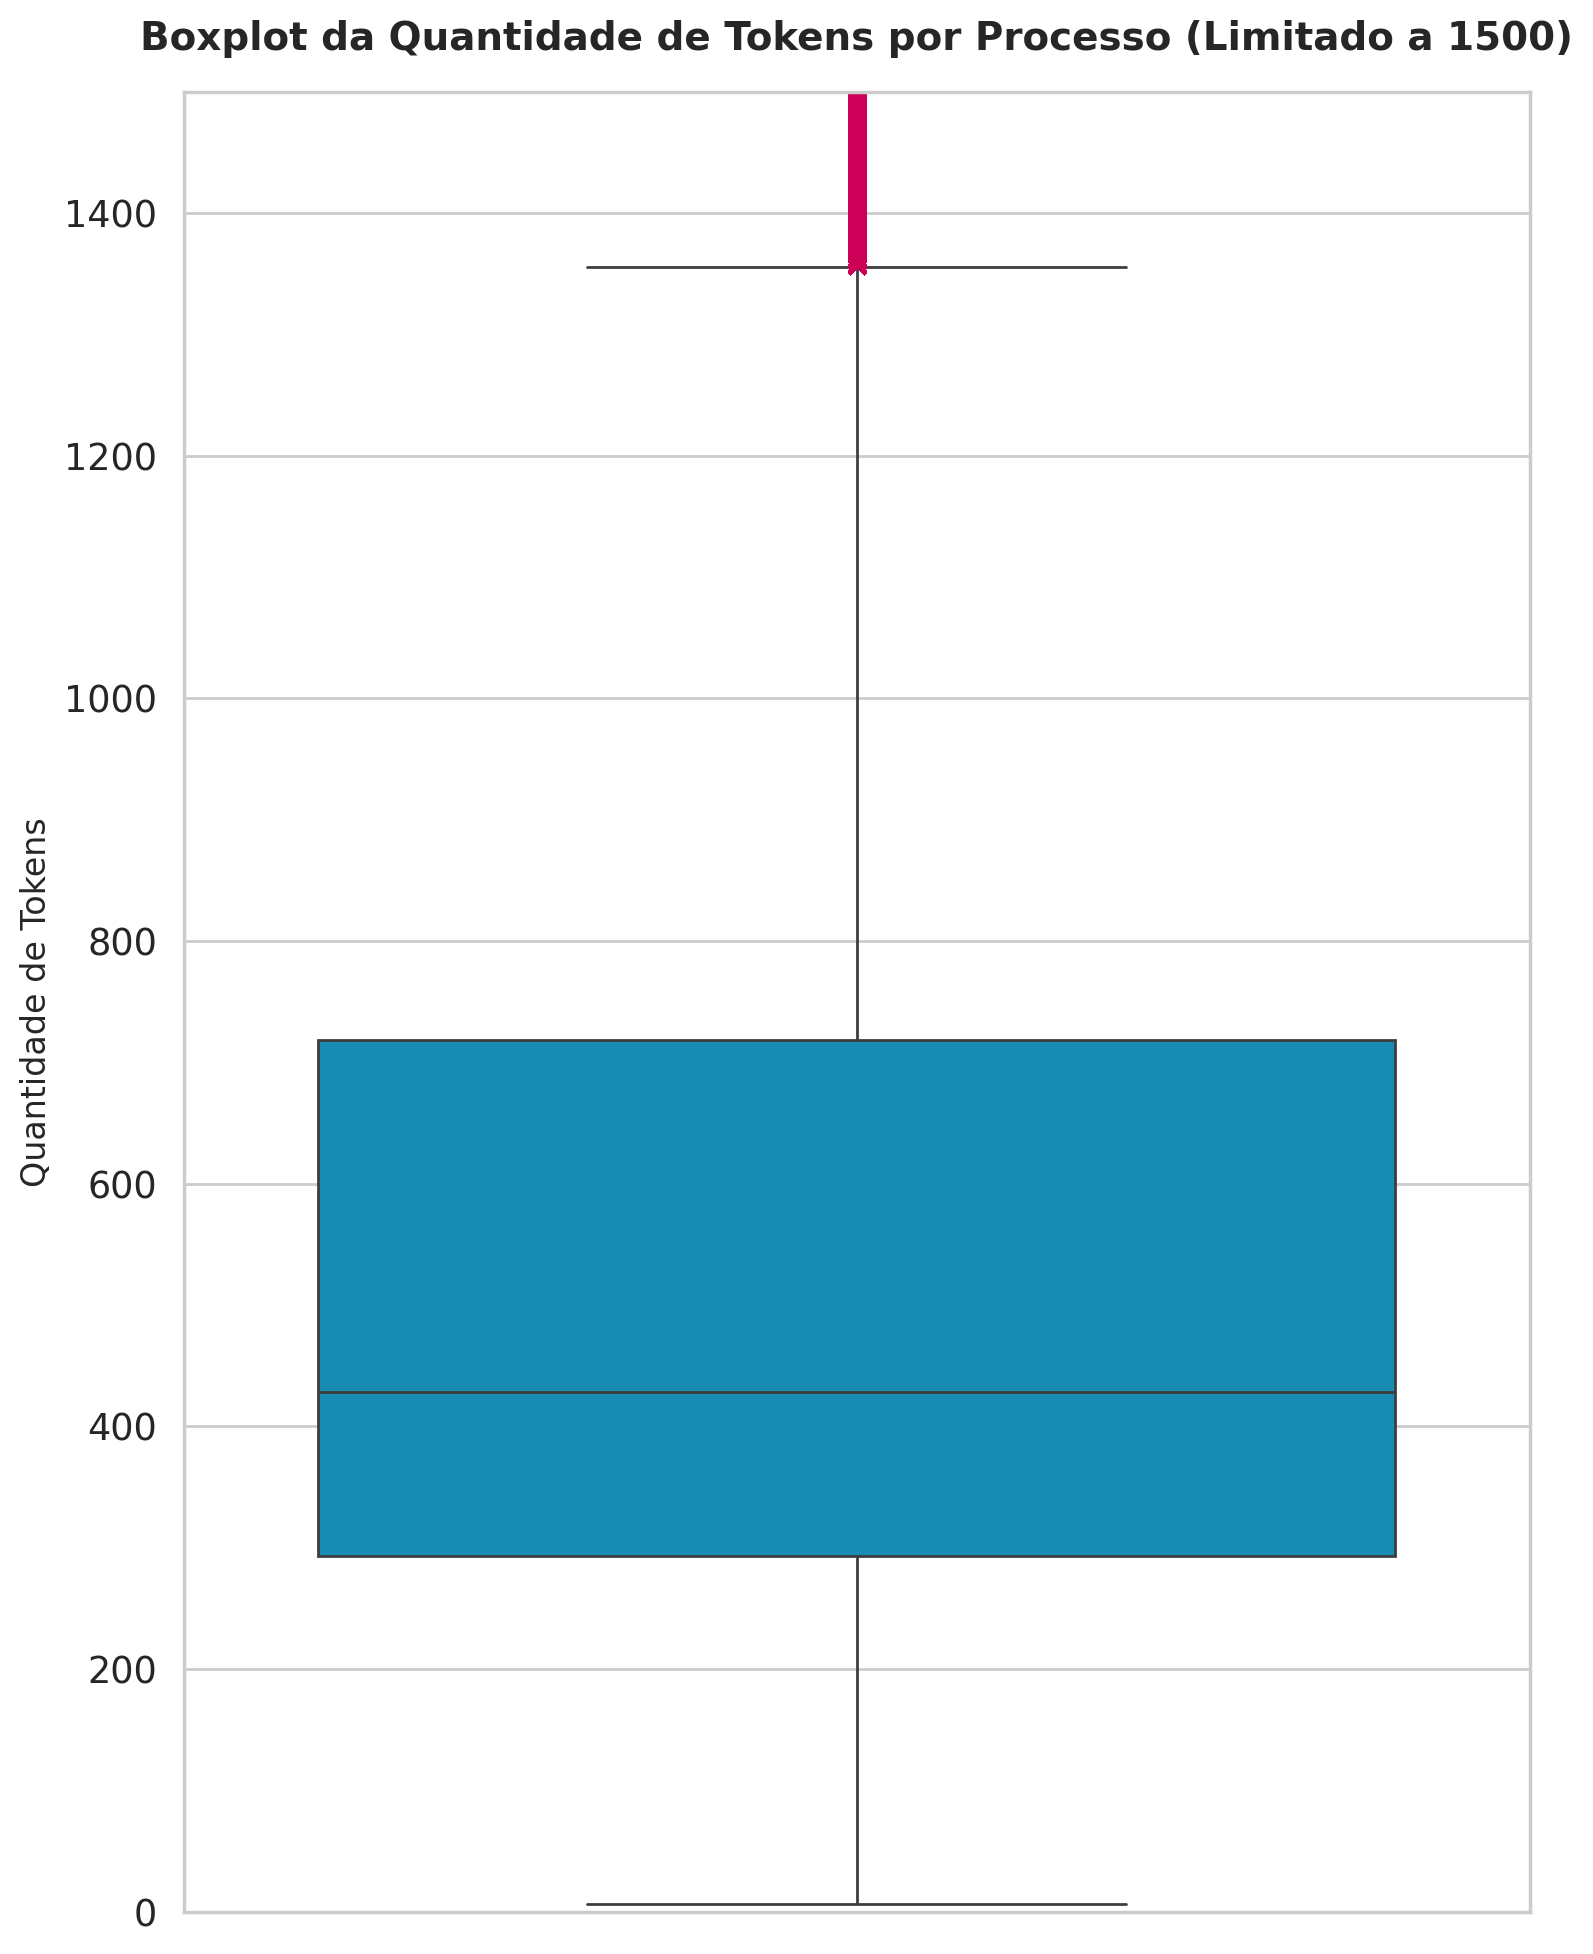

In [ ]:
# Chamada da função com o dataframe desejado
plot_token_boxplot(df)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_token_violin(dataset):
    # Configuração de estilo acadêmico
    sns.set_theme(style="white", palette="muted")
    plt.figure(figsize=(8, 6))

    # Criar o Violin Plot com design minimalista usando o dataset parametrizado
    ax = sns.violinplot(
        y=dataset['NUM_TOKENS_RELATORIO'],
        color='lightgray', # Cor neutra para o fundo
        inner='quartile',   # Linhas pontilhadas para Q1, Mediana e Q3
        linewidth=1.5,
        cut=0
    )

    # Estilizando as linhas internas do violino (quartis)
    for line in ax.lines:
        line.set_linestyle('--')
        line.set_color('black')
        line.set_alpha(0.6)

    # Limite do eixo Y conforme solicitado
    plt.ylim(0, 3500)

    # Títulos e rótulos formatados para publicações
    plt.title('Figura 1: Distribuição da Densidade de Tokens por Relatório', fontsize=12, fontweight='bold', pad=20)
    plt.ylabel('Quantidade de Tokens', fontsize=11)
    plt.xlabel('Processos de Habeas Corpus', fontsize=11)

    # Remoção de eixos desnecessários (estilo Tufte/Acadêmico)
    sns.despine(left=False, bottom=False)

    # Adicionar grid apenas no eixo Y para referência
    plt.grid(axis='y', linestyle=':', alpha=0.7)

    # Otimização de layout
    plt.tight_layout()
    plt.show()

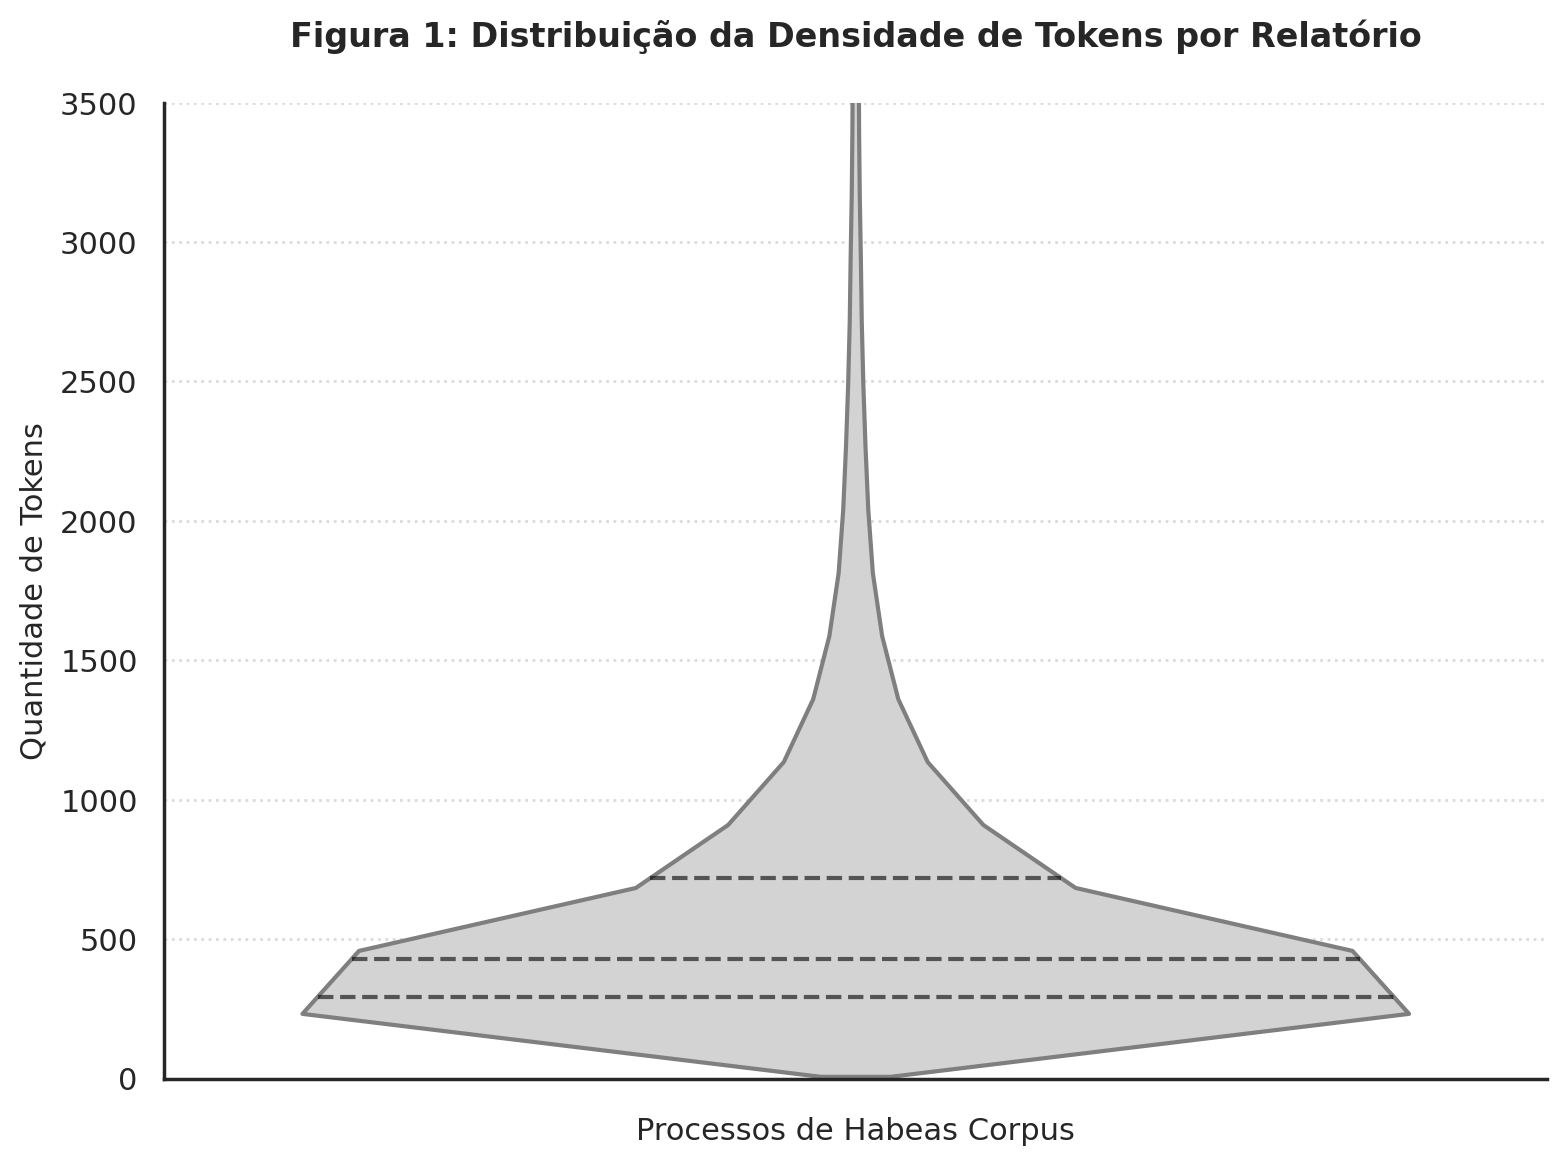

In [ ]:
# Chamada da função com o dataframe desejado
plot_token_violin(df)

In [ ]:
raise Exception("Stop execution. Verificar se há necessidade de sobreescrita de dados! Se houver, descomente o código abaixo e execute-o.")

In [ ]:
file_path = f"{BASE_PATH_DATASET}preprocessed_geral_HC_2021_2025.csv"
print(f"Salvando o DataFrame no caminho padrão: {file_path}...")
try:
    df.to_csv(file_path, sep=';', index=False)
    print(f"✅ DataFrame salvo com sucesso em: {file_path}")
    print(f"Shape do DataFrame salvo: {df.shape}")
except Exception as e:
    print(f"❌ Erro ao salvar o arquivo: {e}")

## Fase 02 - Undersampling

In [ ]:
df.info()

### Distribuição de DECISAO_FAVORAVEL com TEXTO_LONGO

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df,
    x='DECISAO_FAVORAVEL',
    hue='TEXTO_LONGO',
    palette=['#0098CC', '#CC0057'],
    order=['N', 'S']
)

plt.title('Distribuição de Decisões Favoráveis por Tamanho do Texto', fontsize=14, pad=15)
plt.xlabel('Decisão Favorável (S=Sim, N=Não)', fontsize=12)
plt.ylabel('Quantidade de Processos', fontsize=12)

# Adicionar rótulos de valores nas barras
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=11)

plt.legend(title='Texto Longo (> 512 Tokens)', labels=['Não (<= 512)', 'Sim (> 512)'])
plt.tight_layout()
plt.show()


In [ ]:
2/0

### Investigação de Valores Nulos no df_under
Vamos verificar os registros onde a decisão não foi mapeada para entender por que eles foram parar no dataset balanceado.

In [ ]:
# Identificar registros onde DECISAO_FAVORAVEL é nulo no df_under
df_nulos = df_under[df_under['DECISAO_FAVORAVEL'].isna()]

print(f"Quantidade de registros com DECISAO_FAVORAVEL nula no df_under: {len(df_nulos)}")
display(df_nulos[['NUMEROREGISTRO', 'MINISTRO', 'DECISAO_FAVORAVEL', 'TEOR']].head())

# Verificar se a origem é o df original
nulos_original = df['DECISAO_FAVORAVEL'].isna().sum()
print(f"\nQuantidade de nulos no DataFrame original (df): {nulos_original}")

In [ ]:
file_path_under = f"{BASE_PATH_DATASET}preprocessed_geral_HC_under_2021_2025.csv"
print(f"Salvando o DataFrame no caminho padrão: {file_path_under}...")
try:
    df_under.to_csv(file_path, sep=';', index=False)
    print(f"✅ DataFrame salvo com sucesso em: {file_path}")
    print(f"Shape do DataFrame salvo: {df_under.shape}")
except Exception as e:
    print(f"❌ Erro ao salvar o arquivo: {e}")


### Corte Outliers tamanho de tokens do Relatório

In [ ]:
import os
from sklearn.model_selection import train_test_split

# df_base_mix = df_under # base sequência normal
df_base_mix = df # base para sequência excepcional

In [ ]:
df_base_mix['NUM_TOKENS_RELATORIO'].describe()

In [ ]:
print(f'Registros antes da filtragem: {len(df_base_mix)}')

# Remover registros com mais de 5000 tokens
df_base_mix = df_base_mix[df_base_mix['NUM_TOKENS_RELATORIO'] <= 5000].copy()

# Remover registros com menos de 128 tokens
df_base_mix = df_base_mix[df_base_mix['NUM_TOKENS_RELATORIO'] >= 128].copy()

print(f'Registros após a filtragem (> 5000 tokens removidos): {len(df_base_mix)}')
print('\nNovas estatísticas de tokens:')
display(df_base_mix['NUM_TOKENS_RELATORIO'].describe())

In [ ]:
df_base_mix.info()

## Elaboração da Base para Textos Longos e Curtos

A construção destes subdatasets deverá preservar os Acórdãos, devido a alta qualidade do conteúdo jurídico, a equalização dos ministros e ano do processo (para evitar vieses) e balanceamento do rótulo (DECISAO DO JULGAMENTO).

In [ ]:
# Obter dataset a partir da célula abrir dataset principal
# file_path = f"{BASE_PATH_DATASET}preprocessed_geral_HC_2021_2025.csv"

# df = pd.read_csv(file_path, sep=";")

DATASET_TYPE = 'LONG' # 'LONG' or 'SMALL

In [ ]:
df_base_mix = df.copy()

In [ ]:
dataset_type = 'S' if DATASET_TYPE == 'LONG' else 'N'
df_long = df_base_mix[df_base_mix['TEXTO_LONGO'] == dataset_type].copy()
df_long.info()

<class 'pandas.core.frame.DataFrame'>
Index: 95261 entries, 3 to 218263
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   SEQDOCUMENTO                 95261 non-null  int64 
 1   DATAPUBLICACAO               95261 non-null  object
 2   TIPODOCUMENTO                95261 non-null  object
 3   NUMEROREGISTRO               95261 non-null  int64 
 4   DATARECEBIMENTO              95261 non-null  object
 5   DATADISTRIBUICAO             95257 non-null  object
 6   MINISTRO                     95261 non-null  object
 7   RECURSO                      9664 non-null   object
 8   TEOR                         95261 non-null  object
 9   ASSUNTOS                     95261 non-null  object
 10  NUM_DIAS_CONCLUSAO_PROCESSO  95261 non-null  int64 
 11  TIPOPROCESSO                 95261 non-null  object
 12  NUMEROPROCESSO               95261 non-null  int64 
 13  DECISAO_FAVORAVEL            95261 

In [ ]:
df_long['TIPODOCUMENTO'].value_counts()

,count
TIPODOCUMENTO,
DECISAO,86515
ACORDAO,8746


In [ ]:
df.NUM_TOKENS_RELATORIO.describe()

,NUM_TOKENS_RELATORIO
count,218267.000000
mean,657.394645
std,709.473157
min,23.000000
25%,300.000000
50%,455.000000
75%,759.000000
max,22357.000000


In [ ]:
df_long = df[(df['NUM_TOKENS_RELATORIO'] >=1024) & (df['NUM_TOKENS_RELATORIO'] < 6000)].copy()

In [ ]:
#df_base_mix.shape
df_long.NUM_TOKENS_RELATORIO.describe()

,NUM_TOKENS_RELATORIO
count,31352.000000
mean,1768.701295
std,897.920088
min,1024.000000
25%,1181.000000
50%,1431.000000
75%,1991.000000
max,5991.000000


In [ ]:
df_long['TEOR'].value_counts()

,count
TEOR,
Negando,12435
Não Conhecendo,10467
Concedendo,8430
Admitindo Embargo,20


In [ ]:
# Calcular os tamanhos exatos para responder a dúvida sobre o tamanho final do dataset
if DATASET_TYPE == 'LONG':
    mask_acordao = df_long['TIPODOCUMENTO'].isin(['ACÓRDÃO', 'ACORDAO'])
else:
    mask_acordao = pd.Series([False] * len(df_long), index=df_long.index)

df_acordaos = df_long[mask_acordao]

total_c0_disponivel = len(df_long[df_long['classe'] == 0])
total_c1_disponivel = len(df_long[df_long['classe'] == 1])
target_por_classe = min(total_c0_disponivel, total_c1_disponivel)

total_dataset_final = target_por_classe * 2

print(f"Registros totais na Classe 0 disponíveis: {total_c0_disponivel}")
print(f"Registros totais na Classe 1 disponíveis: {total_c1_disponivel}")
print(f"Tamanho final do dataset balanceado (50% Classe 0 e 50% Classe 1): {total_dataset_final} registros")
if DATASET_TYPE == 'LONG':
    print(f"Desses {total_dataset_final} registros, teremos {len(df_acordaos)} acórdãos garantidos e o restante preenchido por decisões monocráticas.")
else:
    print("Para o dataset SMALL, os acórdãos não são forçados na amostragem, permitindo o balanceamento perfeito.")

Registros totais na Classe 0 disponíveis: 22902
Registros totais na Classe 1 disponíveis: 8450
Tamanho final do dataset balanceado (50% Classe 0 e 50% Classe 1): 16900 registros
Desses 16900 registros, teremos 2302 acórdãos garantidos e o restante preenchido por decisões monocráticas.


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Identificar Acórdãos (devem ser 100% mantidos apenas se for LONG)
if DATASET_TYPE == 'LONG':
    mask_acordao = df_long['TIPODOCUMENTO'].isin(['ACÓRDÃO', 'ACORDAO'])
else:
    # Para SMALL, ignoramos a obrigatoriedade dos acórdãos para não prejudicar o balanceamento
    mask_acordao = pd.Series([False] * len(df_long), index=df_long.index)

df_acordaos = df_long[mask_acordao].copy()
df_decisoes = df_long[~mask_acordao].copy()

# Criar coluna auxiliar de estratificação em ambos
df_decisoes['strata'] = df_decisoes['MINISTRO'].astype(str) + '_' + df_decisoes['ANO_RECEBIMENTO'].astype(str)

# 2. Contar quantidade de acórdãos por classe
acordaos_c0 = df_acordaos[df_acordaos['classe'] == 0]
acordaos_c1 = df_acordaos[df_acordaos['classe'] == 1]

len_ac0 = len(acordaos_c0)
len_ac1 = len(acordaos_c1)

# Para balancear perfeitamente a classe 0 e classe 1
total_c0_disponivel = len(df_long[df_long['classe'] == 0])
total_c1_disponivel = len(df_long[df_long['classe'] == 1])
target_por_classe = min(total_c0_disponivel, total_c1_disponivel)

print(f"Total de Acórdãos Classe 0 (forçados): {len_ac0}")
print(f"Total de Acórdãos Classe 1 (forçados): {len_ac1}")
print(f"Alvo final por classe (balanceado): {target_por_classe}")

# 3. Amostrar decisões para preencher o que falta em cada classe
def sample_decisions(df_dec, target_size, existing_acordaos_count):
    needed = target_size - existing_acordaos_count
    if needed <= 0:
        return pd.DataFrame() # Caso os acórdãos já excedam o alvo

    # Filtrar estratos com pelo menos 2 amostras para viabilizar a estratificação
    strata_counts = df_dec['strata'].value_counts()
    valid_strata = strata_counts[strata_counts > 1].index
    df_dec_valid = df_dec[df_dec['strata'].isin(valid_strata)]

    # Se precisarmos de mais registros do que os válidos disponíveis,
    # retornamos todas as decisões válidas disponíveis para esta classe.
    if needed >= len(df_dec_valid):
        return df_dec_valid

    sampled, _ = train_test_split(
        df_dec_valid,
        train_size=needed,
        stratify=df_dec_valid['strata'],
        random_state=RANDOM_SEED
    )
    return sampled

# Amostrar para classe 0
decisoes_c0 = df_decisoes[df_decisoes['classe'] == 0]
sampled_dec_c0 = sample_decisions(decisoes_c0, target_por_classe, len_ac0)

# Amostrar para classe 1
decisoes_c1 = df_decisoes[df_decisoes['classe'] == 1]
sampled_dec_c1 = sample_decisions(decisoes_c1, target_por_classe, len_ac1)

# 4. Concatenar tudo (Acórdãos originais + Decisões amostradas) e embaralhar
df_long_under = pd.concat([
    acordaos_c0,
    acordaos_c1,
    sampled_dec_c0,
    sampled_dec_c1
]).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

# Remover coluna auxiliar de estratificação
df_long_under = df_long_under.drop(columns=['strata'], errors='ignore')

print("\n--- Resultado do Undersampling em df_long ---")
print(f"Tamanho final do dataset: {len(df_long_under)}")
print("Distribuição do campo classe:")
print(df_long_under['classe'].value_counts())

print("\nVerificação da distribuição (Acórdãos vs Decisões):")
print(df_long_under['TIPODOCUMENTO'].value_counts())

Total de Acórdãos Classe 0 (forçados): 2154
Total de Acórdãos Classe 1 (forçados): 148
Alvo final por classe (balanceado): 8450

--- Resultado do Undersampling em df_long ---
Tamanho final do dataset: 16894
Distribuição do campo classe:
classe
0    8450
1    8444
Name: count, dtype: int64

Verificação da distribuição (Acórdãos vs Decisões):
TIPODOCUMENTO
DECISAO    14592
ACORDAO     2302
Name: count, dtype: int64


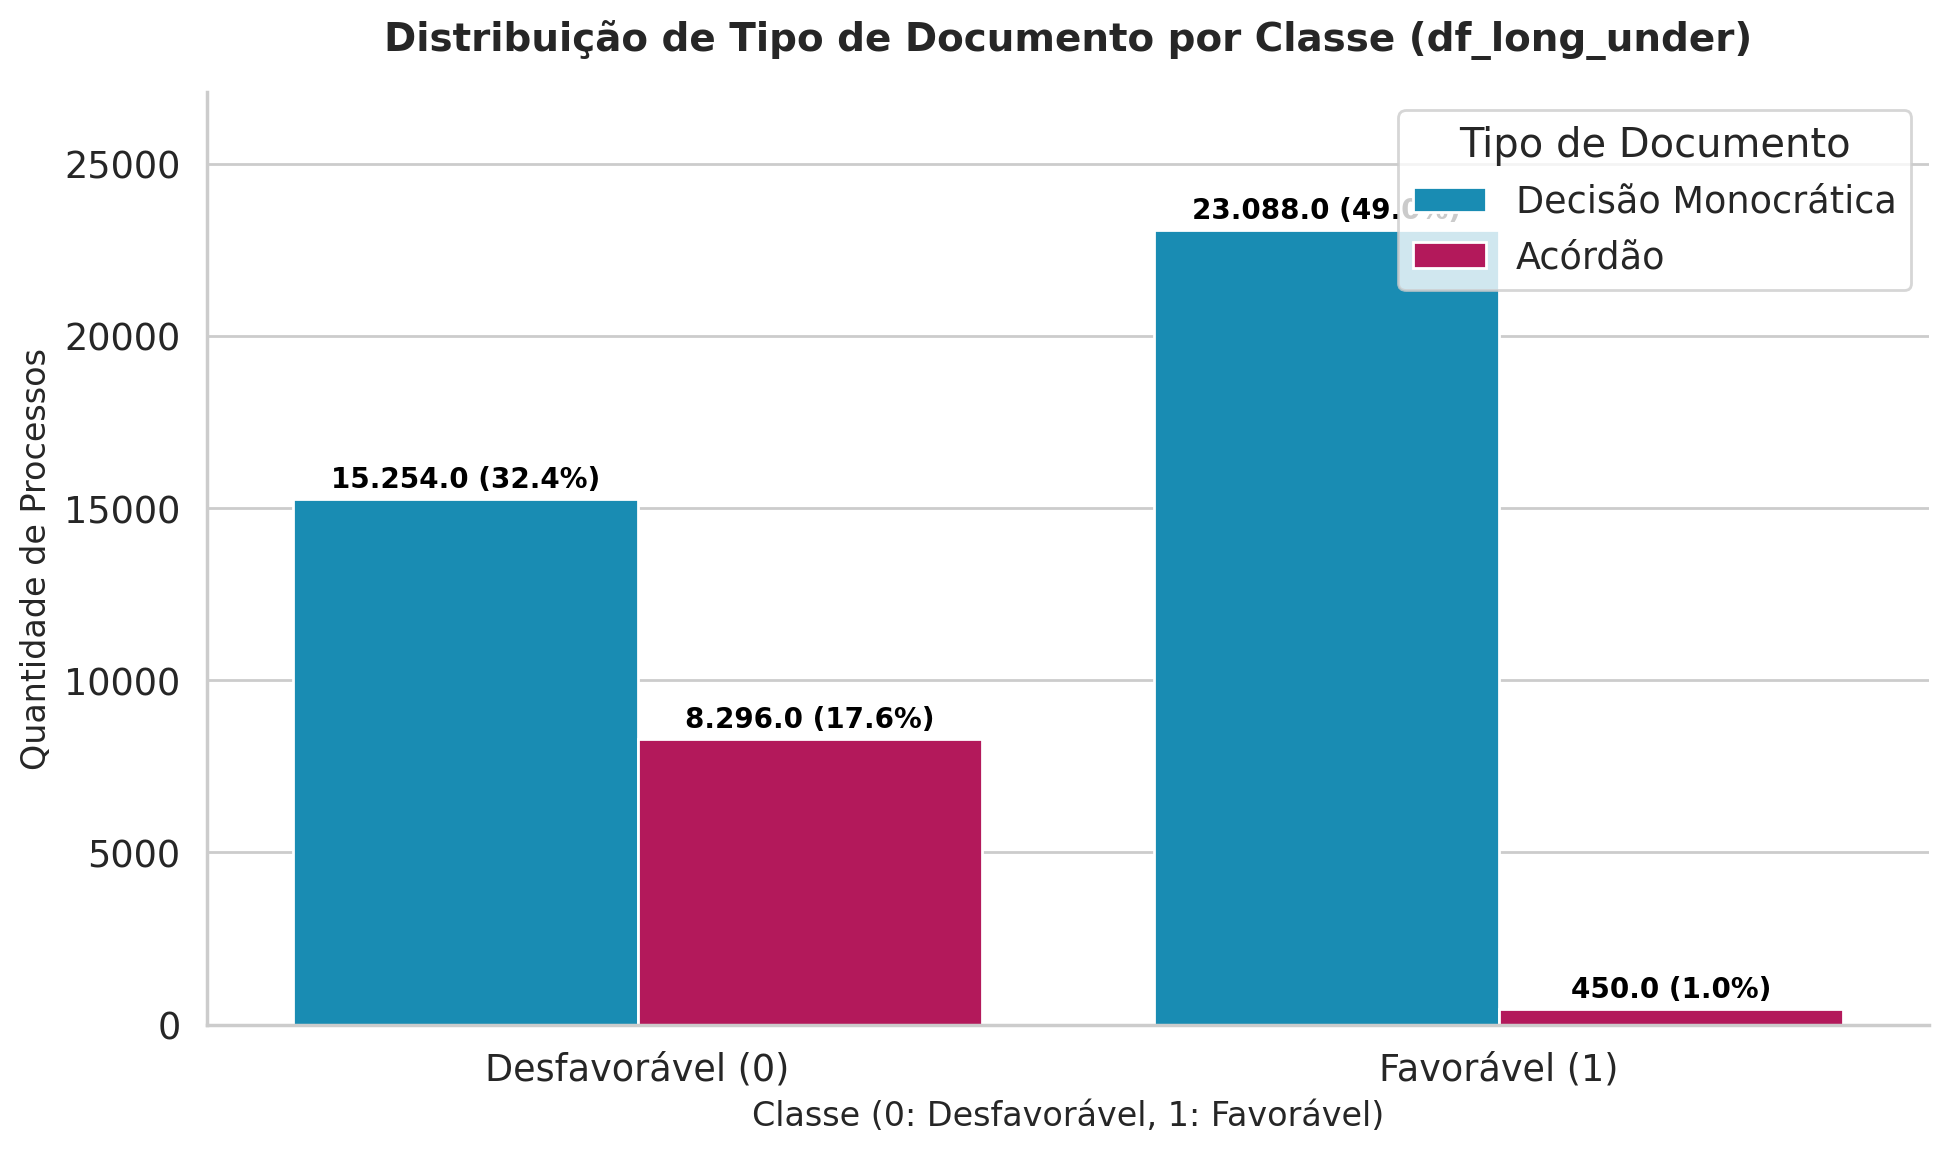

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Criar uma cópia para não alterar o dataset original
df_plot = df_long_under.copy()

# Unificar as grafias de TIPODOCUMENTO
df_plot['TIPO_UNIFICADO'] = df_plot['TIPODOCUMENTO'].replace({
    'ACÓRDÃO': 'Acórdão',
    'ACORDAO': 'Acórdão',
    'DECISÃO': 'Decisão Monocrática',
    'DECISAO': 'Decisão Monocrática'
})

# Configurar tamanho da figura
plt.figure(figsize=(10, 6))

# Criar o gráfico de contagem cruzando o tipo de documento com a classe
ax = sns.countplot(
    data=df_plot,
    x='classe',
    hue='TIPO_UNIFICADO',
    palette=['#0098CC', '#CC0057'],
    order=[0, 1]
)

# Customizações de títulos e eixos
plt.title('Distribuição de Tipo de Documento por Classe (df_long_under)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Classe (0: Desfavorável, 1: Favorável)', fontsize=12)
plt.ylabel('Quantidade de Processos', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['Desfavorável (0)', 'Favorável (1)'])

# Adicionar os rótulos de valores absolutos e percentuais sobre cada barra
total = len(df_plot)
for p in ax.patches:
    height = p.get_height()
    if height > 0: # Evita anotações vazias caso alguma barra seja zero
        percentage = (height / total) * 100
        ax.annotate(f'{height:,} ({percentage:.1f}%)'.replace(',', '.'),
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', fontsize=10, color='black', xytext=(0, 7),
                    textcoords='offset points', fontweight='bold')

# Ajustar limite superior do eixo Y para os labels caberem
plt.ylim(0, max(df_plot['classe'].value_counts()) * 1.15)

# Ajustar legenda
plt.legend(title='Tipo de Documento', loc='upper right')

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# from sklearn.model_selection import train_test_split
# import os

# # 1. Realizar a divisão em treino (70%) e teste (30%) de forma estratificada por classe
# df_train_long, df_test_long = train_test_split(
#     df_long_under,
#     test_size=0.3,
#     random_state=RANDOM_SEED,
#     stratify=df_long_under['classe']
# )

# # 2. Definir caminhos de destino completos
# if DATASET_TYPE == 'LONG':
#   train_path_v3 = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_long_v4.csv"
#   test_path_v3 = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_long_v4.csv"
# elif DATASET_TYPE == 'SMALL':
#   train_path_v3 = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_small_v4.csv"
#   test_path_v3 = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_small_v4.csv"

# # 3. Salvar os dataframes utilizando separador ';'
# try:
#     df_train_long.to_csv(train_path_v3, sep=';', index=False)
#     df_test_long.to_csv(test_path_v3, sep=';', index=False)
#     print("✅ Arquivos de treino e teste v3 salvos com sucesso!")
#     print(f"Treino: {df_train_long.shape[0]} registros -> {train_path_v3}")
#     print(f"Teste: {df_test_long.shape[0]} registros -> {test_path_v3}")
# except Exception as e:
#     print(f"❌ Erro ao salvar os arquivos: {e}")

✅ Arquivos de treino e teste v3 salvos com sucesso!
Treino: 32961 registros -> /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_geral_under_2021_2025_train_long_v4.csv
Teste: 14127 registros -> /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_geral_under_2021_2025_test_long_v4.csv


In [ ]:
print("Verificando balanceamento de classes nos novos arquivos salvos:")
print("\nDistribuição de Classe no Treino (%):")
print(df_train_long['classe'].value_counts(normalize=True).round(4) * 100)
print("\nDistribuição de Classe no Teste (%):")
print(df_test_long['classe'].value_counts(normalize=True).round(4) * 100)

Verificando balanceamento de classes nos novos arquivos salvos:

Distribuição de Classe no Treino (%):
classe
0    50.01
1    49.99
Name: proportion, dtype: float64

Distribuição de Classe no Teste (%):
classe
0    50.01
1    49.99
Name: proportion, dtype: float64


## Análise Individual de Dados

In [ ]:
DATA_BASE_TYPE = [
    {
        'type': 'train-long',
        'path': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_long_v2.csv",
    },
    {
        'type': 'train-small',
        'path': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_small_v2.csv",
    },
    {
        'type': 'train-mix',
        'path': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_mix_v2.csv",
    },
    {
        'type': 'test-long',
        'path': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_long_v2.csv",
    },
    {
        'type': 'test-small',
        'path': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_small_v2.csv",
    },
    {
        'type': 'test-mix',
        'path': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_mix_v2.csv",
    }
]

In [ ]:
def load_dataset(type):
    file_path = None
    for item in DATA_BASE_TYPE:
        if item['type'] == type:
            file_path = item['path']
            break

    if file_path is None:
        raise ValueError(f"Tipo de arquivo não encontrado: {type}")

    df_temp = pd.read_csv(file_path, sep=';')
    return df_temp

In [ ]:
df_train_s = load_dataset('train-small')
df_test_s = load_dataset('test-small')

df_train_l = load_dataset('train-long')
df_test_l = load_dataset('test-long')

df = pd.concat([df_train_s, df_test_s, df_train_l, df_test_l], axis=0)

In [ ]:
df_test_l.NUM_TOKENS_RELATORIO.describe()

,NUM_TOKENS_RELATORIO
count,9047.000000
mean,930.465016
std,411.240710
min,511.000000
25%,629.000000
50%,798.000000
75%,1099.500000
max,2499.000000


In [ ]:
# df.info()
# df.shape
df.head()

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,DECISAO_FAVORAVEL,RELATORIO,ANO_RECEBIMENTO,classe,NUM_TOKENS_RELATORIO,TEXTO_LONGO
0,135620532,2021-09-17,DECISAO,202102261283,2021-07-16,2021-07-16,REYNALDO SOARES DA FONSECA,NaN,Concedendo,01209.07942.07791.,63,HC,681316,S,"Cuida-se de habeas corpus, com pedido de limin...",2021,1,499,N
1,207682004,2023-09-14,DECISÃO,202302822972,2023-08-08,2023-08-10,JOEL ILAN PACIORNIK,EMBARGOS DE DECLARAÇÃO,Concedendo,3372;3633;3372,37,HC,845214,S,Trata-se de embargos de declaração opostos por...,2023,1,217,N
2,307192040,2025-04-14,DECISÃO,202402813775,2024-07-29,2024-07-30,ROGERIO SCHIETTI CRUZ,RCD,Não Conhecendo,3608,259,HC,932866,N,"GUILHERME PEREIRA DE SOUSA, por meio da Petiçã...",2024,0,382,N
3,346107983,2025-11-13,DECISÃO,202503814772,2025-10-01,2025-10-01,ROGERIO SCHIETTI CRUZ,NaN,Negando,"10891, 3417",43,HC,1040086,N,MARCUS VINICIUS WATANABE FANTINE DE OLIVEIRA a...,2025,0,173,N
4,277245275,2024-10-22,DECISÃO,202403943249,2024-10-16,2024-10-17,RIBEIRO DANTAS,NaN,Não Conhecendo,"3608, 3633, 5897",6,HC,954101,N,Trata-se de habeas corpus substitutivo de recu...,2024,0,223,N


In [ ]:
df.shape

(64682, 19)

In [ ]:
df.NUM_TOKENS_RELATORIO.describe()

,NUM_TOKENS_RELATORIO
count,64682.000000
mean,615.213815
std,423.365961
min,128.000000
25%,323.000000
50%,482.000000
75%,770.000000
max,2500.000000


In [ ]:
df[df['NUM_TOKENS_RELATORIO'] == 510].head(3)

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,DECISAO_FAVORAVEL,RELATORIO,ANO_RECEBIMENTO,classe,NUM_TOKENS_RELATORIO,TEXTO_LONGO
323,141520489,2021-12-01,DECISAO,202103106076,2021-09-23,2021-09-24,JOEL ILAN PACIORNIK,NaN,Concedendo,"00287.03415.05566., 12467.12612.",69,HC,696414,S,Cuida-se de habeas corpus substitutivo de recu...,2021,1,510,N
545,348740658,2025-12-01,DECISÃO,202504582773,2025-11-18,2025-11-19,SEBASTIÃO REIS JÚNIOR,NaN,Negando,3608,13,HC,1054054,N,Trata-se de habeas corpus impetrado em favor d...,2025,0,510,N
1992,309104514,2025-04-30,DECISÃO,202500172807,2025-01-24,2025-01-24,RIBEIRO DANTAS,NaN,Concedendo,10635,96,HC,976378,S,Trata-se de habeas corpus impetrado em favor d...,2025,1,510,N


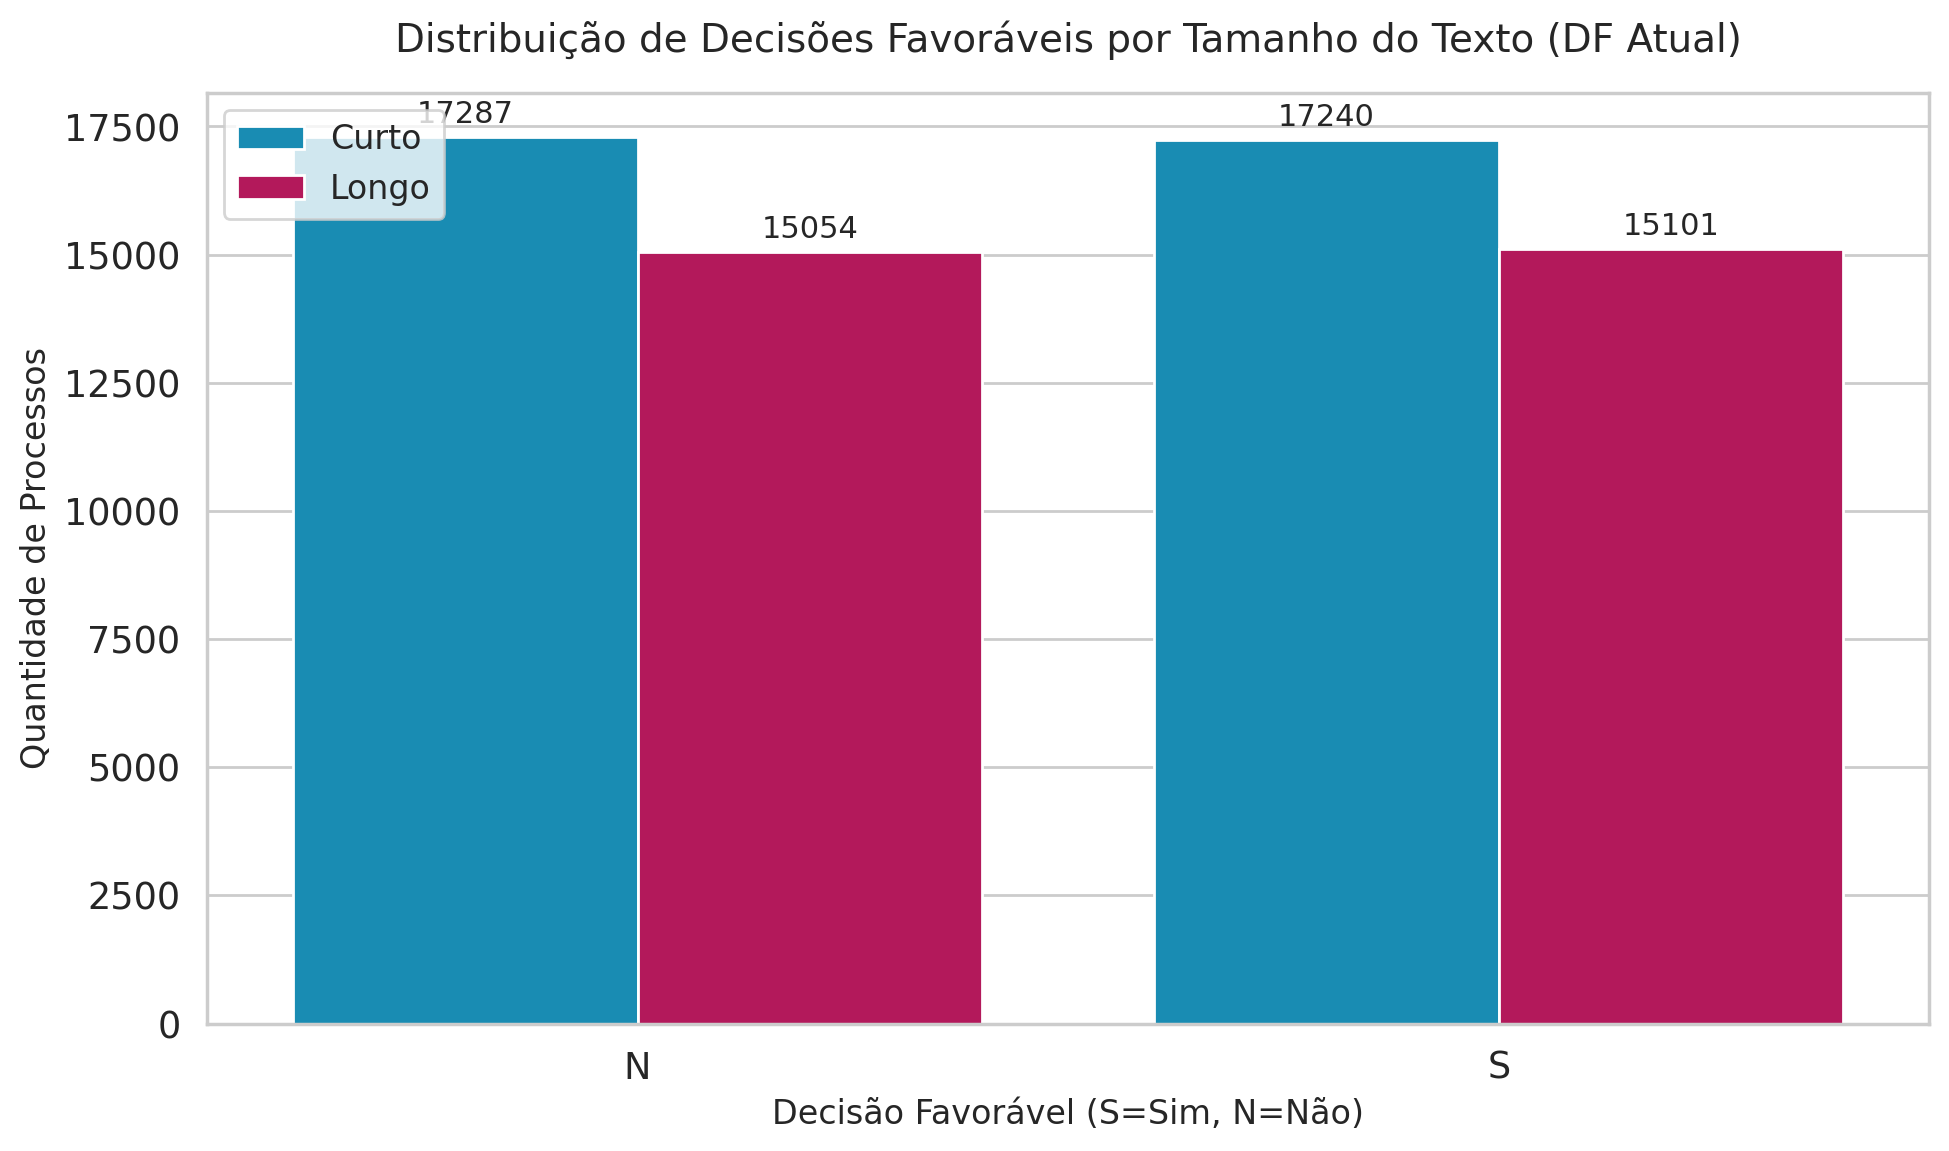

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o tamanho da figura
plt.figure(figsize=(10, 6))

# Criar o gráfico de barras (countplot)
ax = sns.countplot(
    data=df,
    x='DECISAO_FAVORAVEL',
    hue='TEXTO_LONGO',
    palette=['#0098CC', '#CC0057'],
    order=['N', 'S']
)

# Customizações de título e rótulos
plt.title('Distribuição de Decisões Favoráveis por Tamanho do Texto (DF Atual)', fontsize=14, pad=15)
plt.xlabel('Decisão Favorável (S=Sim, N=Não)', fontsize=12)
plt.ylabel('Quantidade de Processos', fontsize=12)

# Adicionar rótulos de valores nas barras para facilitar a leitura
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=11)

# Ajustar legenda: tamanho menor e lado esquerdo
plt.legend(
    #title='Texto Longo (> 512 Tokens)',
    labels=['Curto', 'Longo'],
    loc='upper left',
    fontsize='small',
    title_fontsize='small'
)

plt.tight_layout()
plt.show()

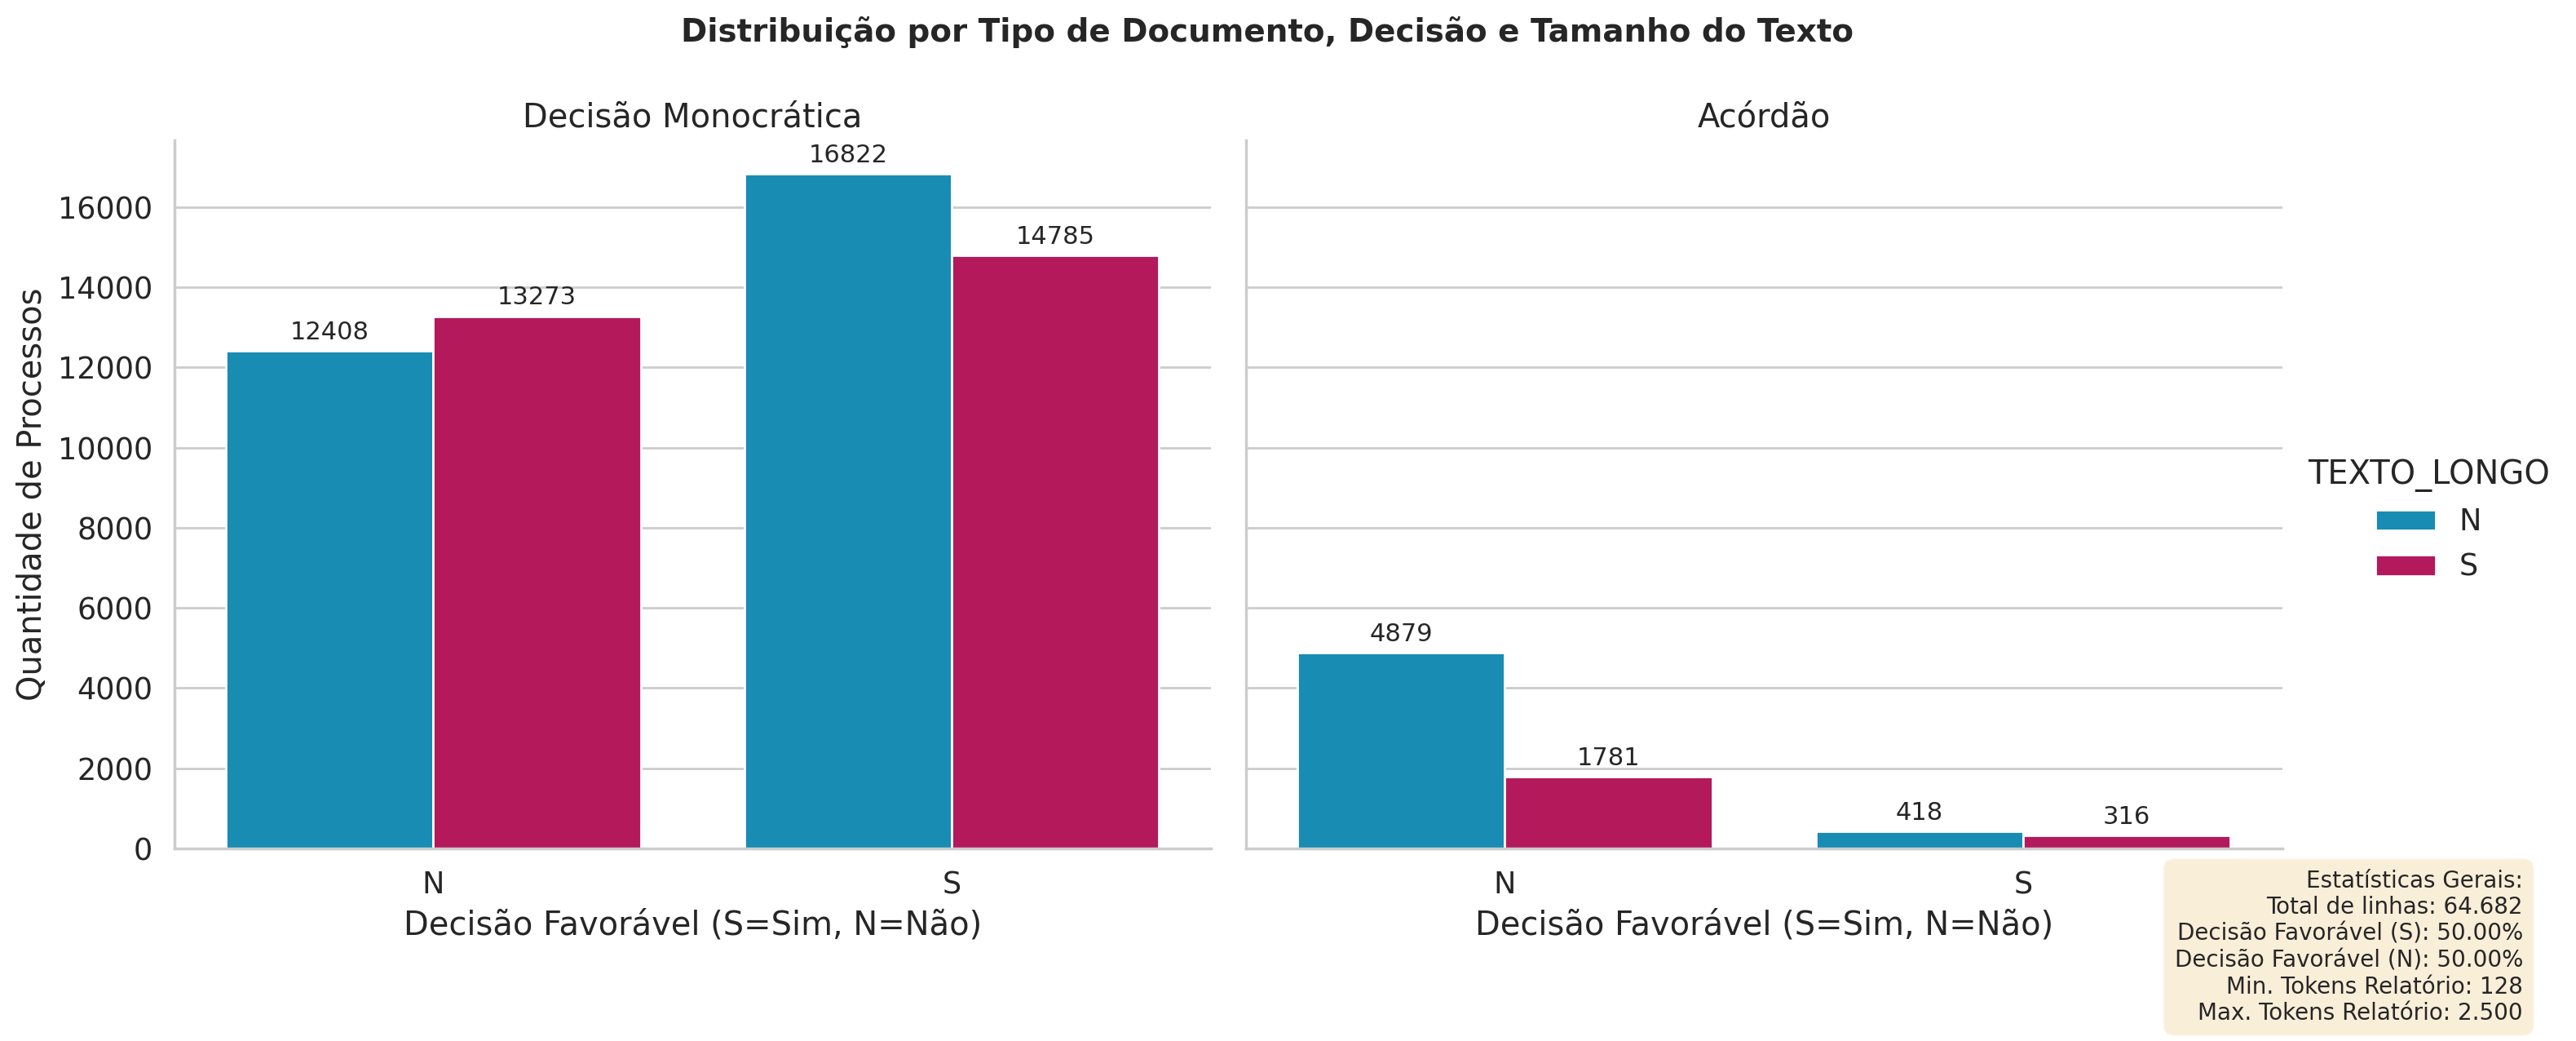

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Unificar as grafias de TIPODOCUMENTO para o gráfico
df_plot = df.copy()
df_plot['TIPO_UNIFICADO'] = df_plot['TIPODOCUMENTO'].replace({
    'ACÓRDÃO': 'Acórdão',
    'ACORDAO': 'Acórdão',
    'DECISÃO': 'Decisão Monocrática',
    'DECISAO': 'Decisão Monocrática'
})

# Calcular estatísticas para a legenda
total_linhas = len(df_plot)
decisao_counts = df_plot['DECISAO_FAVORAVEL'].value_counts(normalize=True)
percent_s = decisao_counts.get('S', 0) * 100
percent_n = decisao_counts.get('N', 0) * 100

min_tokens = df_plot['NUM_TOKENS_RELATORIO'].min()
max_tokens = df_plot['NUM_TOKENS_RELATORIO'].max()

# Formatar estatísticas para o texto da legenda, garantindo formato de número brasileiro
legend_text_lines = [
    "Estatísticas Gerais:",
    f"Total de linhas: {total_linhas:,.0f}".replace(',', '.'),
    f"Decisão Favorável (S): {percent_s:.2f}%",
    f"Decisão Favorável (N): {percent_n:.2f}%",
    f"Min. Tokens Relatório: {min_tokens:,.0f}".replace(',', '.'),
    f"Max. Tokens Relatório: {max_tokens:,.0f}".replace(',', '.'),
]
legend_text = "\n".join(legend_text_lines)

# Criar gráfico facetado (catplot)
g = sns.catplot(
    data=df_plot,
    x='DECISAO_FAVORAVEL',
    hue='TEXTO_LONGO',
    col='TIPO_UNIFICADO',
    kind='count',
    palette=['#0098CC', '#CC0057'],
    order=['N', 'S'],
    height=6,
    aspect=1.2
)

# Customizações de título e rótulos
g.fig.suptitle('Distribuição por Tipo de Documento, Decisão e Tamanho do Texto', y=1.05, fontsize=14, fontweight='bold')
g.set_axis_labels('Decisão Favorável (S=Sim, N=Não)', 'Quantidade de Processos')
g.set_titles('{col_name}')

# Adicionar rótulos de valores nas barras
for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', padding=3, fontsize=11)

# Ajustar os parâmetros do subplot para criar espaço para o texto na parte inferior
g.fig.subplots_adjust(bottom=0.2)

# Adicionar as estatísticas personalizadas como uma caixa de texto na figura
# Posicionar na parte inferior direita
g.fig.text(0.98, 0.02, legend_text,
           horizontalalignment='right',
           verticalalignment='bottom',
           bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5),
           fontsize=10,
           transform=g.fig.transFigure)

plt.show()

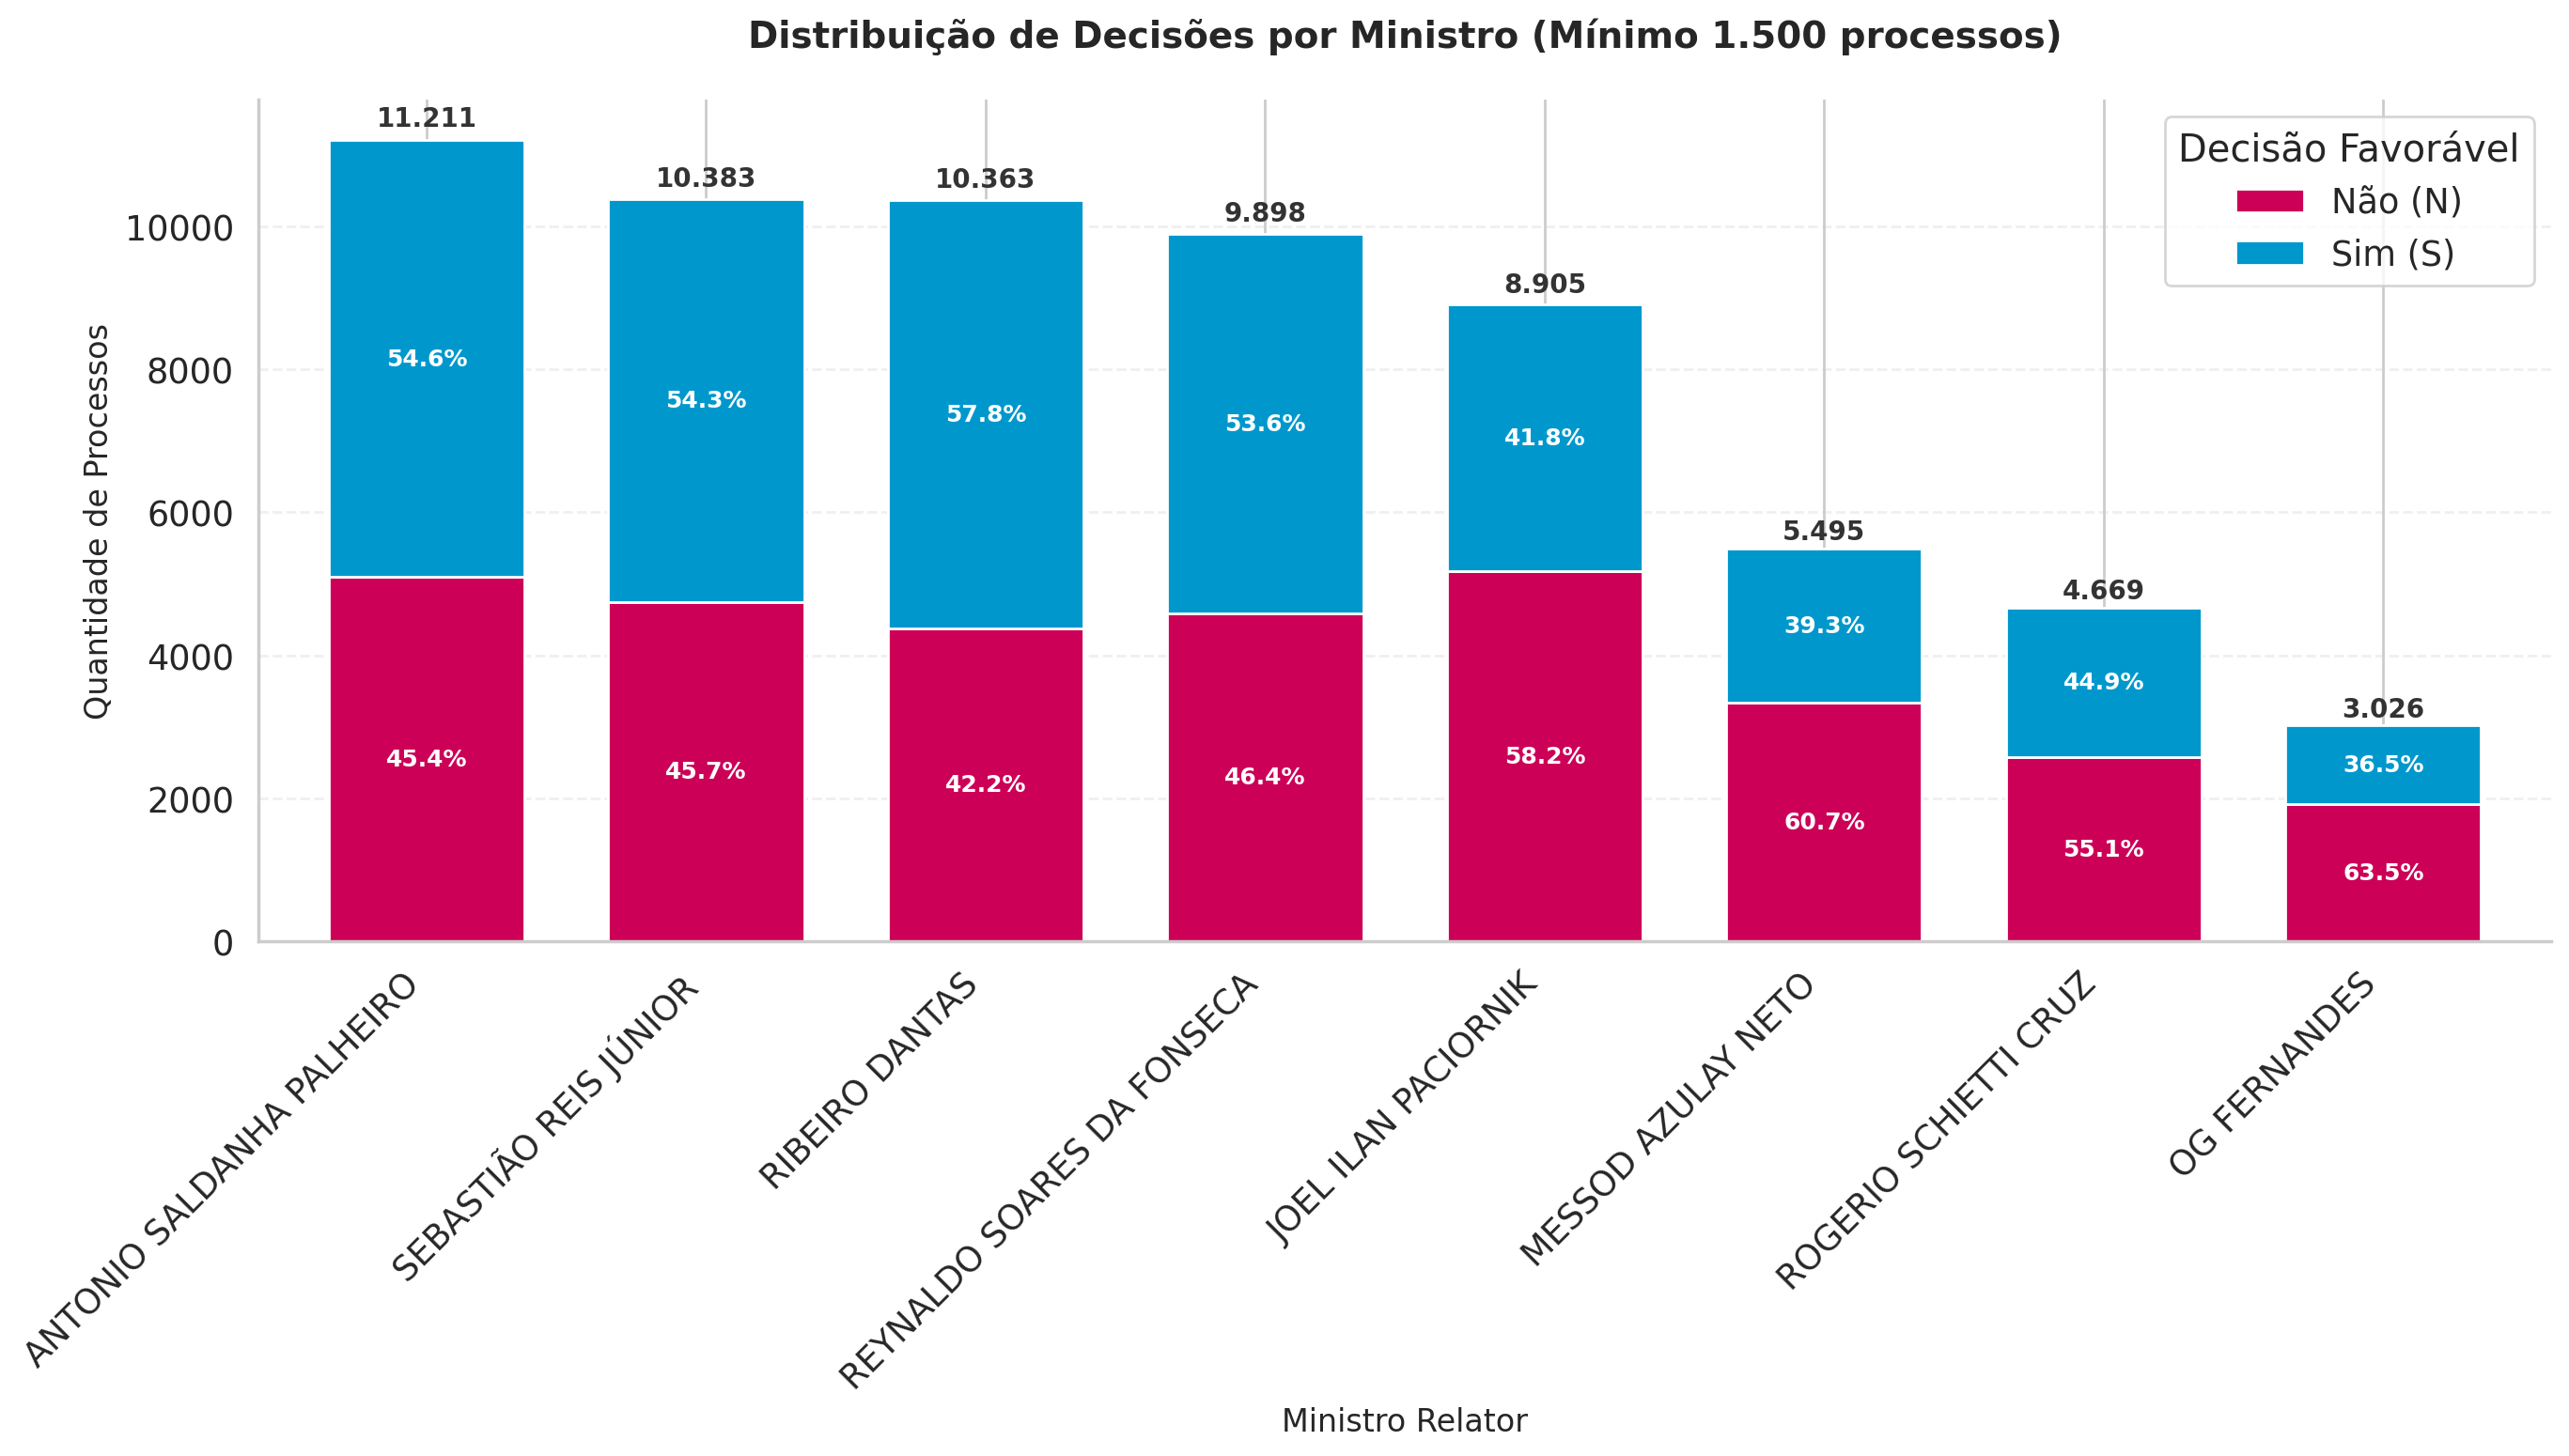

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Preparar os dados: Agrupar por Ministro e Decisão
df_min = df.groupby(['MINISTRO', 'DECISAO_FAVORAVEL']).size().unstack(fill_value=0)

# Calcular totais
df_min['Total'] = df_min.sum(axis=1)

# FILTRO: Omitir ministros com total inferior a 1500
df_min = df_min[df_min['Total'] >= 1500]

# Ordenar de forma decrescente
df_min = df_min.sort_values(by='Total', ascending=False)

# Criar a figura
plt.figure(figsize=(14, 8))
ax = plt.gca()

# Plotar barras empilhadas
df_min[['N', 'S']].plot(kind='bar', stacked=True, color=['#CC0057', '#0098CC'], ax=ax, width=0.7)

# Adicionar percentuais dentro das barras e o total no topo
for i, (index, row) in enumerate(df_min.iterrows()):
    total = row['Total']
    y_offset = 0

    # Rótulos percentuais (N e S)
    for col in ['N', 'S']:
        val = row[col]
        if val > 0:
            percentage = (val / total) * 100
            # Só exibe se houver espaço razoável na barra
            if percentage > 3:
                ax.text(i, y_offset + val/2, f'{percentage:.1f}%',
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)
            y_offset += val

    # Rótulo do total no topo da barra
    ax.text(i, total + (total * 0.01), f'{int(total):,}'.replace(',', '.'),
            ha='center', va='bottom', fontweight='bold', fontsize=10, color='#333333')

# Customizações estéticas
plt.title('Distribuição de Decisões por Ministro (Mínimo 1.500 processos)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Ministro Relator', fontsize=12)
plt.ylabel('Quantidade de Processos', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Decisão Favorável', labels=['Não (N)', 'Sim (S)'], loc='upper right')

sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# import pandas as pd
# from sklearn.model_selection import train_test_split
# import os

# # Lista para armazenar os novos metadados, se necessário
# DATA_BASE_TYPE_V2 = []

# for db_info in DATA_BASE_TYPE:
#     tipo = db_info['type']
#     path = db_info['path']

#     print(f"Processando dataset: {tipo}...")

#     # 1. Carregar
#     temp_df = pd.read_csv(path, sep=';')
#     orig_len = len(temp_df)

#     # 2. Filtrar tokens (128 a 2500)
#     temp_df = temp_df[(temp_df['NUM_TOKENS_RELATORIO'] >= 128) & (temp_df['NUM_TOKENS_RELATORIO'] <= 2500)].copy()
#     filt_len = len(temp_df)

#     # 3. Undersampling estratificado por DECISAO_FAVORAVEL
#     counts = temp_df['DECISAO_FAVORAVEL'].value_counts()
#     if len(counts) < 2:
#         print(f"⚠️ Dataset {tipo} possui apenas uma classe. Pulando undersampling.")
#         df_resampled = temp_df
#     else:
#         min_class_size = counts.min()

#         df_s = temp_df[temp_df['DECISAO_FAVORAVEL'] == 'S']
#         df_n = temp_df[temp_df['DECISAO_FAVORAVEL'] == 'N']

#         # Função auxiliar para samplear
#         def get_sample(sub_df, size):
#             return sub_df.sample(n=size, random_state=RANDOM_SEED) if len(sub_df) > size else sub_df

#         df_s_res = get_sample(df_s, min_class_size)
#         df_n_res = get_sample(df_n, min_class_size)

#         df_resampled = pd.concat([df_s_res, df_n_res]).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

#     # 4. Definir novo path e salvar
#     new_path = path.replace('.csv', '_v2.csv')
#     df_resampled.to_csv(new_path, sep=';', index=False)

#     print(f"✅ {tipo}: Original: {orig_len} | Filtrado: {filt_len} | Final (Under): {len(df_resampled)}")
#     print(f"   Salvo em: {new_path}\n")

#     DATA_BASE_TYPE_V2.append({'type': f"{tipo}_v2", 'path': new_path})

## Código Auxiliares

### Persistir um dataset

In [ ]:
raise Exception("Área restrita... faça passo a passo.")

In [ ]:
#file_path = f"{BASE_PATH_DATASET}dataset_decisoes_acordaos_HC_2021_2025_tokenized.csv"
file_path = f"{BASE_PATH_DATASET}preprocessed_geral_HC_2021_2025.csv"

dataframe = df_geral

print(f"Salvando o DataFrame no caminho padrão: {file_path}...")
try:
    dataframe.to_csv(file_path, sep=';', index=False)
    print(f"✅ DataFrame salvo com sucesso em: {file_path}")
    print(f"Shape do DataFrame salvo: {dataframe.shape}")
except Exception as e:
    print(f"❌ Erro ao salvar o arquivo: {e}")

### Abrir um dataset

In [ ]:
file_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_under_2021_2025_train_long-punct.csv"

df = pd.read_csv(file_path, sep=";")

In [ ]:
df.info(
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18127 entries, 0 to 18126
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   SEQDOCUMENTO                 18127 non-null  int64 
 1   DATAPUBLICACAO               18127 non-null  object
 2   TIPODOCUMENTO                18127 non-null  object
 3   NUMEROREGISTRO               18127 non-null  int64 
 4   DATARECEBIMENTO              18127 non-null  object
 5   DATADISTRIBUICAO             18125 non-null  object
 6   MINISTRO                     18127 non-null  object
 7   RECURSO                      1740 non-null   object
 8   TEOR                         18112 non-null  object
 9   ASSUNTOS                     18127 non-null  object
 10  NUM_DIAS_CONCLUSAO_PROCESSO  18127 non-null  int64 
 11  TIPOPROCESSO                 18127 non-null  object
 12  NUMEROPROCESSO               18127 non-null  int64 
 13  DECISAO_FAVORAVEL            18

In [ ]:
#Separando os dados por um ano específico
df_acordaos_2025 = df[(df['ANO_RECEBIMENTO'] == 2025) & (df['TIPODOCUMENTO'] == 'ACORDAO')].copy()
df_acordaos_2025.head(3)

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,DECISAO_FAVORAVEL,RELATORIO,NUM_TOKENS_RELATORIO,ANO_RECEBIMENTO,classe,TEXTO_LONGO,DS_RECURSO
11,346935321,2025-11-19,ACORDAO,202504005071,2025-10-13,2025-10-15,REYNALDO SOARES DA FONSECA,AgRg,Negando,"12334, 3628",37,HC,1043772,N,Trata-se de agravo regimental interposto por M...,1548,2025,0,S,AGRAVO REGIMENTAL
13,346935194,2025-11-19,ACORDAO,202503975996,2025-10-10,2025-10-10,REYNALDO SOARES DA FONSECA,AgRg,Negando,"5555, 4355, 12091",40,HC,1042988,N,Trata-se de agravo regimental interposto por J...,1113,2025,0,S,AGRAVO REGIMENTAL
65,333591384,2025-09-09,ACORDAO,202502295650,2025-06-23,2025-06-24,ANTONIO SALDANHA PALHEIRO,AgRg,Negando,"12334, 3633, 3628",78,HC,1013893,N,O EXMO. SR. MINISTRO ANTONIO SALDANHA PALHEIRO...,940,2025,0,S,AGRAVO REGIMENTAL


In [ ]:
df_acordaos_2025.shape

(423, 20)

### Salvar um dataset

In [ ]:
file_path = f"{BASE_PATH_DATASET}preprocessed_HC_acordaos_2025_goldset.csv"

print(f"Salvando o DataFrame no caminho padrão: {file_path}...")
try:
    df.to_csv(file_path, sep=';', index=False)
    print(f"✅ DataFrame salvo com sucesso em: {file_path}")
    print(f"Shape do DataFrame salvo: {df.shape}")
except Exception as e:
    print(f"❌ Erro ao salvar o arquivo: {e}")

Salvando o DataFrame no caminho padrão: /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_acordaos_2025_goldset.csv...
✅ DataFrame salvo com sucesso em: /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_acordaos_2025_goldset.csv
Shape do DataFrame salvo: (423, 20)


### Reorganizar dados de treino e teste
Unir os dados de treino e teste e aplicar uma proporção diferente da original

In [ ]:
DATASET_TYPE = 'long'

file_path_train = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_{DATASET_TYPE}_v3.csv" # Extreme: mudar a proporção de treino/teste de 80/20 para 70/30.
file_path_test = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_{DATASET_TYPE}_v3.csv"

df_train = pd.read_csv(file_path_train, sep=";")
df_test = pd.read_csv(file_path_test, sep=";")

print(f"Shape do dataset de treino: {df_train.shape}")
print(f"Shape do dataset de teste: {df_test.shape}")

Shape do dataset de treino: (37670, 19)
Shape do dataset de teste: (9418, 19)


In [ ]:
df_all = pd.concat([df_train, df_test], axis=0)
df_all.shape

(47088, 19)

In [ ]:
from sklearn.model_selection import train_test_split
import os

# 1. Realizar a divisão em treino (70%) e teste (30%) de forma estratificada por classe
df_train_v4, df_test_v4 = train_test_split(
    df_all,
    test_size=0.3,
    random_state=RANDOM_SEED,
    stratify=df_all['classe']
)

# 2. Definir caminhos de destino completos
train_path_v4 = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_{DATASET_TYPE}_v4.csv"
test_path_v4 = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_{DATASET_TYPE}_v4.csv"

# 3. Salvar os dataframes utilizando separador ';'
try:
    df_train_v4.to_csv(train_path_v4, sep=';', index=False)
    df_test_v4.to_csv(test_path_v4, sep=';', index=False)
    print("✅ Arquivos de treino e teste v3 salvos com sucesso!")
    print(f"Treino: {df_train_v4.shape[0]} registros -> {train_path_v4}")
    print(f"Teste: {df_test_v4.shape[0]} registros -> {test_path_v4}")
except Exception as e:
    print(f"❌ Erro ao salvar os arquivos: {e}")

✅ Arquivos de treino e teste v3 salvos com sucesso!
Treino: 30784 registros -> /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_geral_under_2021_2025_train_small_v4.csv
Teste: 13194 registros -> /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_geral_under_2021_2025_test_small_v4.csv


In [ ]:
print('--- df_train_v4 ---')
print(f"Total de registros: {len(df_train_v4)}")
print("Distribuição de DECISAO_FAVORAVEL:")
display(df_train_v4['DECISAO_FAVORAVEL'].value_counts())
print("\n--- df_test_v4 ---")
print(f"Total de registros: {len(df_test_v4)}")
print("Distribuição de DECISAO_FAVORAVEL:")
display(df_test_v4['DECISAO_FAVORAVEL'].value_counts())

--- df_train_v4 ---
Total de registros: 30784
Distribuição de DECISAO_FAVORAVEL:


,count
DECISAO_FAVORAVEL,
N,15397
S,15387



--- df_test_v4 ---
Total de registros: 13194
Distribuição de DECISAO_FAVORAVEL:


,count
DECISAO_FAVORAVEL,
N,6599
S,6595


In [ ]:
df_all[df_all['NUM_TOKENS_RELATORIO'] > 510].head()

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,DECISAO_FAVORAVEL,RELATORIO,NUM_TOKENS_RELATORIO,TEXTO_LONGO,classe,ANO_RECEBIMENTO
0,278924469,2024-10-30,DECISAO,202202014322,2022-06-29,2022-07-04,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,5566,854,HC,753187,S,JHONATAN PAULO DOS SANTOS alega ser vítima de ...,6341,S,1,2022
1,129479475,2021-06-29,ACORDAO,202101655330,2021-05-27,2021-05-28,SEBASTIÃO REIS JÚNIOR,AgRg,Negando,"00287.03369.03372., 00287.05874.03580.",33,HC,670141,N,Trata-se de agravo regimental interposto por M...,1042,S,0,2021
2,333589792,2025-09-09,ACORDAO,202404783745,2024-12-13,2024-12-16,SEBASTIÃO REIS JÚNIOR,AgRg,Negando,"10904, 7791",270,HC,968867,N,Trago a julgamento desta Sexta Turma o agravo ...,584,S,0,2024
3,246640223,2024-05-22,DECISAO,202304585935,2023-12-15,2023-12-18,JOEL ILAN PACIORNIK,NaN,Não Conhecendo,3372,159,HC,878518,N,"Cuida-se de habeas corpus, com pedido liminar,...",1382,S,0,2023
4,181235777,2023-03-14,DECISAO,202300768771,2023-03-10,2023-03-13,REYNALDO SOARES DA FONSECA,NaN,Concedendo,7791;7791;7791,4,HC,807780,S,"Trata-se de habeas corpus, com pedido de limin...",586,S,1,2023


In [ ]:
df_all['NUM_TOKENS_RELATORIO'].describe()

,NUM_TOKENS_RELATORIO
count,47088.000000
mean,1124.318744
std,949.868948
min,511.000000
25%,633.000000
50%,826.000000
75%,1202.000000
max,18281.000000


###Undersampling simples - ajustando apenas classe

In [ ]:
print(df_long['classe'].value_counts())

classe
0    22902
1     8450
Name: count, dtype: int64


In [ ]:
df_under = df_long.copy()
df_under.shape

(31352, 19)

In [ ]:
import pandas as pd

# Identificar a menor classe disponível no dataset df_under
contagem_classes = df_under['classe'].value_counts()
menor_classe_tamanho = contagem_classes.min()

# Agrupar e amostrar de forma a equilibrar as classes
df_under_balanceado = df_under.groupby('classe').apply(lambda x: x.sample(n=menor_classe_tamanho, random_state=RANDOM_SEED)).reset_index(drop=True)

# Atualizar a variável df_under com os dados balanceados
df_under = df_under_balanceado

print("Distribuição das classes após undersampling:")
print(df_under['classe'].value_counts())
print(f"\nShape final do df_under: {df_under.shape}")

Distribuição das classes após undersampling:
classe
0    8450
1    8450
Name: count, dtype: int64

Shape final do df_under: (16900, 19)


###Realizar a divisão dos dados entre treino e teste

* **Dataset v5:** Especializado com textos longos variando de 1024 até 6000 tokens.

In [ ]:
df_base_split = df_under.copy()
df_base_split.shape

(16900, 19)

In [ ]:
from sklearn.model_selection import train_test_split
import os

SPLIT_TEST_SIZE = 0.2
DATASET_VERSION = 5
DATASET_TYPE = 'long'

df_train, df_test = train_test_split(
    df_base_split,
    test_size=SPLIT_TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=df_base_split['classe']
)

train_path = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_{DATASET_TYPE}_v{DATASET_VERSION}.csv"
test_path = f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_{DATASET_TYPE}_v{DATASET_VERSION}.csv"

try:
    df_train.to_csv(train_path, sep=';', index=False)
    df_test.to_csv(test_path, sep=';', index=False)
    print(f"✅ Arquivos de treino e teste version {DATASET_VERSION} salvos com sucesso!")
    print(f"Treino: {df_train.shape[0]} registros -> {train_path}")
    print(f"Teste: {df_test.shape[0]} registros -> {test_path}")
except Exception as e:
    print(f"❌ Erro ao salvar os arquivos: {e}")

✅ Arquivos de treino e teste version 5 salvos com sucesso!
Treino: 13520 registros -> /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_geral_under_2021_2025_train_long_v5.csv
Teste: 3380 registros -> /content/drive/MyDrive/_Mestrado/Datasets/preprocessed_HC_geral_under_2021_2025_test_long_v5.csv


# Trade-off

## Dataset loading

In [ ]:
file_path = f"{BASE_PATH_GENERAL}/models/log_trade_off_events.csv"

if os.path.exists(file_path):
    try:
        df_tradeoff = pd.read_csv(file_path, sep=';')
        loaded_from = file_path
        print(f"✅ Arquivo carregado com sucesso de: {file_path}")
        print(f"Shape: {df_tradeoff.shape}")
        display(df_tradeoff.head(3))
    except Exception as e:
        print(f"❌ Erro ao ler {file_path}: {e}")
else:
    print(f"⚠️ Arquivo CSV não encontrado no caminho: {file_path}")
    print("Por favor, verifique se o arquivo existe ou o caminho está correto.")

✅ Arquivo carregado com sucesso de: /content/drive/MyDrive/_Mestrado//models/log_trade_off_events.csv
Shape: (699896, 10)


,id_model,name,label,approach,dataset_version,auc_train,NUMEROREGISTRO,NUM_TOKENS_RELATORIO,TIPODOCUMENTO,inference_time_ms
0,1,legalbertpt_fp,Legal BERT,Truncation (512),4,0.829,202202544706,473,DECISAO,12.9454
1,1,legalbertpt_fp,Legal BERT,Truncation (512),4,0.829,202504051669,342,DECISAO,20.6166
2,1,legalbertpt_fp,Legal BERT,Truncation (512),4,0.829,202400023900,364,DECISAO,13.6240


## Preprocessing

In [ ]:
df_tradeoff.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699896 entries, 0 to 699895
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id_model              699896 non-null  int64  
 1   name                  699896 non-null  object 
 2   label                 699896 non-null  object 
 3   approach              699896 non-null  object 
 4   dataset_version       699896 non-null  int64  
 5   auc_train             699896 non-null  float64
 6   NUMEROREGISTRO        699896 non-null  int64  
 7   NUM_TOKENS_RELATORIO  699896 non-null  int64  
 8   TIPODOCUMENTO         699896 non-null  object 
 9   inference_time_ms     699896 non-null  float64
dtypes: float64(2), int64(4), object(4)
memory usage: 53.4+ MB


## Gráficos

In [ ]:
LIST_MODEL_INFERENCE_TRAINED = [
    #Truncation approach -------------------------------------------------------
     {
        'id': 0,
        'id_model': 1,
        'name': 'legalbertpt_fp',
        'label': 'Legal BERT',
        'approach': 'Truncation (512)',
        'graphic_label': 'Legal BERT',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.829,
            'long': 0.806
          }
        },
    {
        'id': 1,
        'id_model': 4,
        'name': 'bert-base-portuguese-based',
        'label': 'BERTimbau Base',
        'approach': 'Truncation (512)',
        'graphic_label': 'BERTimbau Base',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.802,
            'long': 0.778
        }
    },
    {
        'id': 2,
        'id_model': 2,
        'name': 'Legal-BERTimbau-base',
        'label': 'Legal BERTimbau',
        'approach': 'Truncation (512)',
        'graphic_label': 'Legal BERTimbau',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.736,
            'long': 0.779
        }
    },

    {
        'id': 3,
        'id_model': 6,
        'name': 'bert-base-multilingual-cased',
        'label': 'BERT Multilingual',
        'approach': 'Truncation (512)',
        'graphic_label': 'BERT Multilingual',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.750,
            'long': 0.684
        }
    },

# Sliding Windows Approach -----------------------------------------------------
    {
        'id': 4,
        'id_model': 1,
        'name': 'legalbertpt_fp',
        'label': 'Legal BERT',
        'approach': 'Mean Pooling - Stride 0',
        'graphic_label': 'Stride 0',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.829,
            'long': 0.859
        }
    },
    {
        'id': 5,
        'id_model': 4,
        'name': 'bert-base-portuguese-based',
        'label': 'BERTimbau Base',
        'approach': 'Mean Pooling - Stride 384',
        'graphic_label': 'Stride 384',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.802,
            'long': 0.833
        }
    },
    {
        'id': 6,
        'id_model': 2,
        'name': 'Legal-BERTimbau-base',
        'label': 'Legal BERTimbau',
        'approach': 'Mean Pooling - Stride 384',
        'graphic_label': 'Stride 384',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.736,
            'long': 0.825
        }
    },
    {
        'id': 7,
        'id_model': 6,
        'name': 'bert-base-multilingual-cased',
        'label': 'BERT Multilingual',
        'approach': 'Mean Pooling - Stride 0',
        'graphic_label': 'Stride 0',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.750,
            'long': 0.779
        }
    },
    {
        'id': 8,
        'id_model': 1,
        'name': 'legalbertpt_fp',
        'label': 'Legal BERT',
        'approach': 'Mean Pooling - Stride 448',
        'graphic_label': 'Mean Pool. - Stride 448',
        'dataset_version': 4,
        'suffix_model_name': 'MLP_4k_NLB',
        'auc_train': {
            'small': 0.0,
            'long': 0.0
        }
    },
    {
        'id': 9,
        'id_model': 1,
        'name': 'legalbertpt_fp',
        'label': 'Legal BERT',
        'approach': 'Max Pooling - Stride 448',
        'graphic_label': 'Max Pool. - Stride 448',
        'dataset_version': 4,
        'suffix_model_name': 'MLP_4k_NLB',
        'auc_train': {
            'small': 0.0,
            'long': 0.0
        }
    }
]

In [ ]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})

In [ ]:
df_tradeoff.label.unique()

array(['Legal BERT', 'BERTimbau Base', 'Legal BERTimbau',
       'BERT Multilingual'], dtype=object)

In [ ]:
# ==============================================================================
# 1. ESCOLHA DO MODELO
# ==============================================================================
MODELO_ALVO = "Legal BERTimbau"

# ==============================================================================
# 2. FILTRAGEM E AGREGAÇÃO DOS DADOS
# ==============================================================================
# Filtra o dataframe para o modelo especificado
df_model = df_tradeoff[df_tradeoff["label"] == MODELO_ALVO].copy()

In [ ]:
df_model.approach.unique()

array(['Truncation (512)', 'Mean Pooling - Stride 384'], dtype=object)

In [ ]:
# Mapear os valores de AUC da LIST_MODEL_INFERENCE_TRAINED (auc_train['long'])
auc_mapping = {}
for item in LIST_MODEL_INFERENCE_TRAINED:
    if item['label'] == MODELO_ALVO:
        auc_mapping[item['approach']] = item['auc_train']['long']

print(auc_mapping)

# Obtendo abordagens dinamicamente do df_model
approaches = df_model['approach'].unique()
app_trad = [app for app in approaches if 'Truncation' in app][0]
app_ours = [app for app in approaches if 'Pooling' in app][0]

auc_trad = auc_mapping[app_trad]
auc_ours = auc_mapping[app_ours]

print(f"\ntrad. ({app_trad}): {auc_trad} ours ({app_ours}): {auc_ours} ")

{'Truncation (512)': 0.779, 'Mean Pooling - Stride 384': 0.825}

trad. (Truncation (512)): 0.779 ours (Mean Pooling - Stride 384): 0.825 


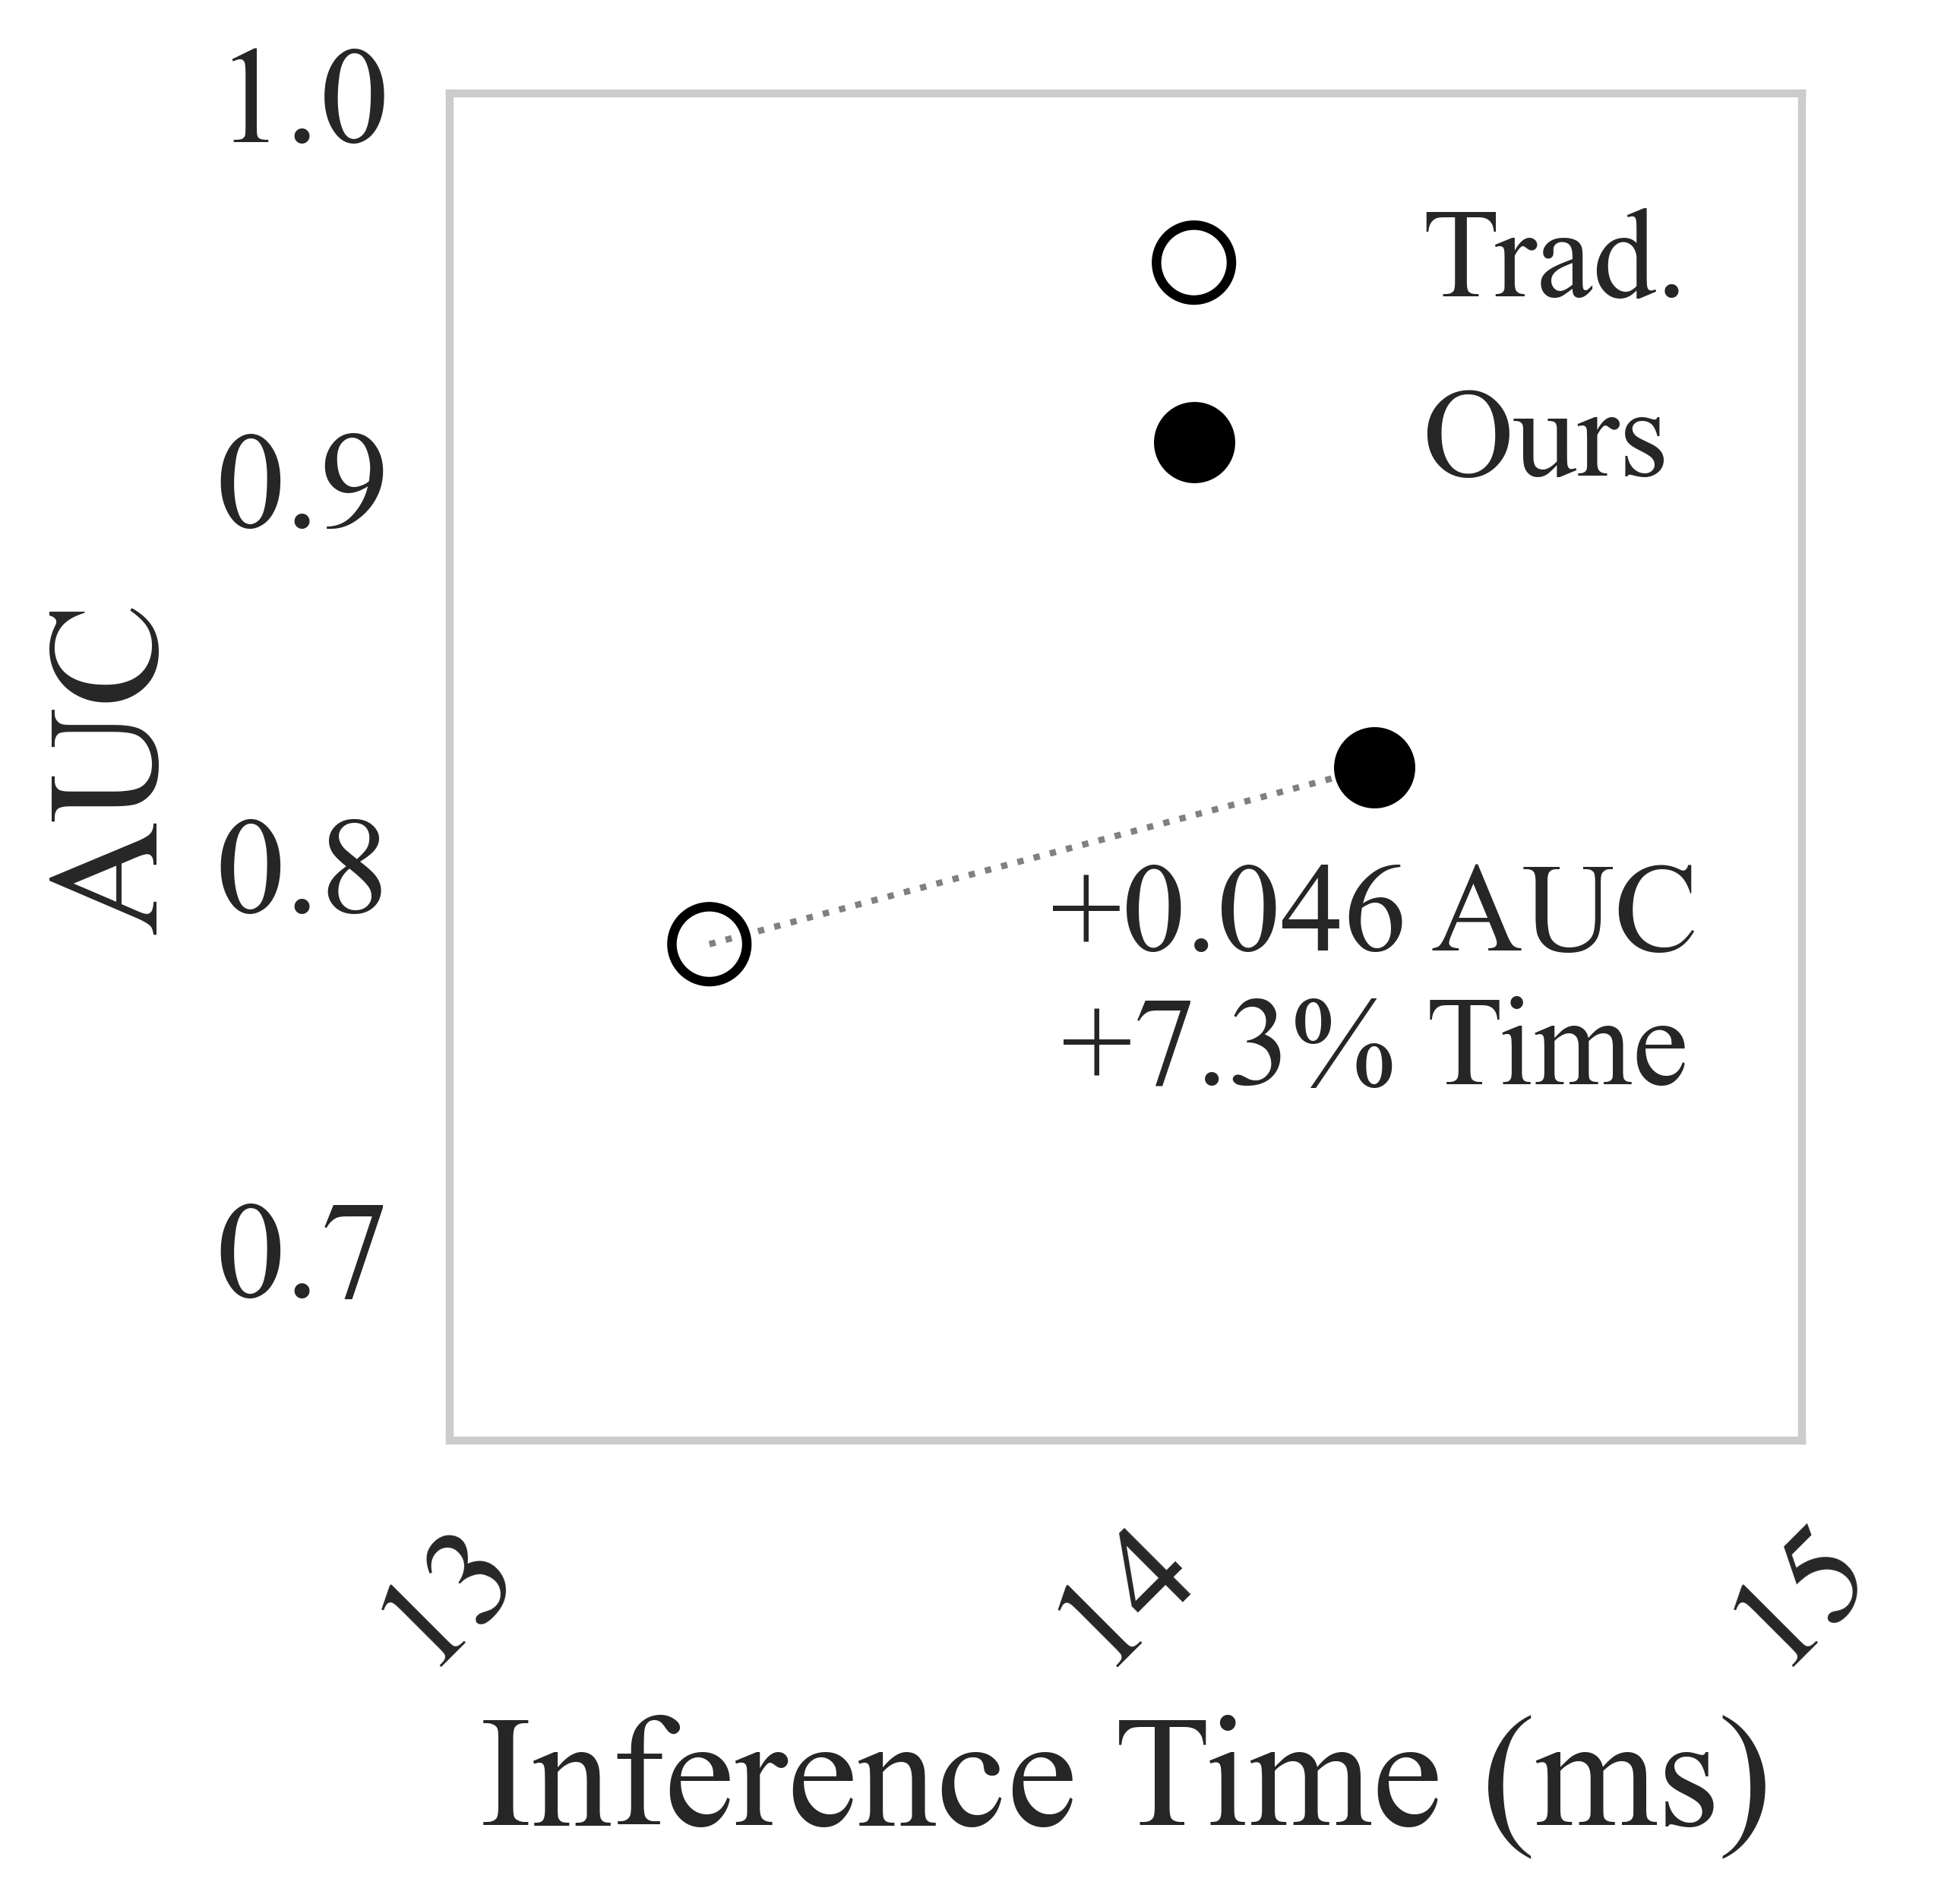

✅ Gráfico salvo em: /content/drive/MyDrive/_Mestrado/models/tradeoff_per_event_legal_bertimbau.pdf


In [ ]:
# AUC por Tempo de Inferência

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# CONFIGURAÇÃO DE ESTILO E TIPOGRAFIA (Padrão Artigo / IEEE / ACM)
# ==============================================================================
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "font.size": 22,
        "axes.labelsize": 25,  # Rótulos dos eixos (AUC, Event Processing Time)
        "axes.titlesize": 24,
        "xtick.labelsize": 22,  # Números e escalas nos eixos X e Y
        "ytick.labelsize": 22,
        "legend.fontsize": 20,  # Texto da legenda (Traditional / Ours)
        "lines.linewidth": 2.0,  # Espessura da linha pontilhada visível na redução
        "figure.autolayout": True,
    }
)

# Calcula a média do tempo de inferência por evento
df_agg = (
    df_model.groupby("approach")
    .agg(
        time_ms=("inference_time_ms", "mean")
    )
    .reset_index()
)

# Identifica os tempos utilizando os mesmos rótulos dinâmicos definidos anteriormente
t_trad = df_agg[df_agg["approach"] == app_trad]["time_ms"].values[0]
t_ours = df_agg[df_agg["approach"] == app_ours]["time_ms"].values[0]

# Cálculos de delta (utilizando auc_trad e auc_ours identificados previamente)
delta_auc = auc_ours - auc_trad
pct_time = ((t_ours - t_trad) / t_trad) * 100

# ==============================================================================
# GERAÇÃO DO GRÁFICO (REPRODUZINDO O ESTILO ANEXO)
# ==============================================================================
fig, ax = plt.subplots(figsize=(4.8, 4.8), dpi=300)

# Linha pontilhada conectando os dois pontos (atualizada para cor cinza conforme solicitação)
ax.plot(
    [t_trad, t_ours],
    [auc_trad, auc_ours],
    linestyle=":",
    color="gray",
    linewidth=1.0,
    zorder=1,
)

# Ponto Tradicional: círculo preto sem preenchimento
ax.scatter(
    t_trad,
    auc_trad,
    s=140,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Trad.",
    zorder=3,
)

# Ponto Proposto (Ours): círculo preto totalmente preenchido
ax.scatter(
    t_ours,
    auc_ours,
    s=140,
    color="black",
    marker="o",
    label="Ours",
    zorder=3,
)

# Rótulo de texto anotando o trade-off
signal_auc = "+" if delta_auc >= 0 else ""
signal_time = "+" if pct_time >= 0 else ""
annotation_text = (
    f"{signal_auc}{delta_auc:.3f} AUC\n{signal_time}{pct_time:.1f}% Time"
)

# Posição da anotação logo abaixo do ponto da nossa abordagem
ax.annotate(
    annotation_text,
    xy=(t_ours, auc_ours),
    xytext=(0, -15),
    textcoords="offset points",
    fontsize=20,
    ha="center",
    va="top",
)

# Formatação dos Eixos e Legenda
ax.set_xlabel("Inference Time (ms)")
ax.set_ylabel("AUC")

# Escalas fixas solicitadas pelo usuário para padronização multimodelo
ax.set_xlim(13.0, 15.0)
ax.set_ylim(0.65, 1.0)

# Rotacionar xticks em 45 graus
plt.xticks(rotation=45)

# Garantir que o grid esteja desativado
ax.grid(False)

# Legenda sem borda e posicionada no canto inferior direito
ax.legend(frameon=False, loc="upper right")

# Exibe o gráfico
plt.show()

# Salvar diretamente em PDF para incluir no Overleaf (corrigindo espaço em branco no início do path)
if 'SAVE_GRAPHIC' in globals() and SAVE_GRAPHIC:
    output_path = f"{BASE_PATH_GRAPHIC}tradeoff_per_event_{MODELO_ALVO.replace(' ', '_').lower()}.pdf"
    fig.savefig(output_path, bbox_inches='tight', dpi=DPI_RESOLUTION)
    print(f"✅ Gráfico salvo em: {output_path}")

In [ ]:
2/0

ZeroDivisionError: division by zero

# Construção da Base para Inferência

**Traditional x Melhor resultado por Modelo (ours):** baseando-se no gráfico de apresentado pelo professor, deverá ser produzido 4 gráficos, uma para cada modelo, comparando a abordagem Tradicional (Truncation) com o melhor resultado de Mean Pooling with Stride (Ours).

**Event Processing Time:** o tempo de inferência calculado por modelo deve ser medido pela média do tempo total de inferência pela quantidade de eventos (registros - Relatório).
A Inferência deve ser realizada com a base total, agrupando os dados de treino e teste, bem como a base composta por textos curtos e textos longos. A respeito da restrição do tamanho dos número de tokens do campo relatório, considerar apenas no range de 2_500 <= tokens >= 128.

In [ ]:

list_file_path = [
    f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_small_v4.csv",
    f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_small_v4.csv",
    f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_long_v4.csv",
    f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_long_v4.csv",
]

list_df = []
for file_path in list_file_path:
  print(f"Abrindo dataset no caminho padrão: {file_path}...")
  try:
      df = pd.read_csv(file_path, sep=";")
      print(f"✅ DataFrame aberto com sucesso em: {file_path}")
      print(df.shape)
      list_df.append(df)
  except Exception as e:
      print(f"❌ Erro ao salvar o arquivo: {e}")

In [ ]:
df_geral = pd.concat(list_df, ignore_index=True)

df_geral.shape

In [ ]:
df_geral = df_geral[(df_geral['NUM_TOKENS_RELATORIO'] >= 128) & (df_geral['NUM_TOKENS_RELATORIO'] <= 2500)].copy()

In [ ]:
df_geral.shape

In [ ]:
file_path = f"{BASE_PATH_DATASET}preprocessed_HC_geral_2021_2025_inference.csv"

print(f"Salvando o DataFrame no caminho padrão: {file_path}...")
try:
    df_geral.to_csv(file_path, sep=';', index=False)
    print(f"✅ DataFrame salvo com sucesso em: {file_path}")
    print(f"Shape do DataFrame salvo: {df_geral.shape}")
except Exception as e:
    print(f"❌ Erro ao salvar o arquivo: {e}")

```markdown
### Tempo Médio de Inferência por Processo (Modelo vs. Abordagem)

Análise adaptada considerando a nova base de dados `df_tradeoff` utilizando as colunas `label`, `approach`, e `inference_time_ms`.
```

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Configuração global de estilo acadêmico (Times New Roman)
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})

# 2. Calcular o tempo médio de inferência por processo por Modelo (label) e Abordagem (approach)
df_grouped = df_tradeoff.groupby(['label', 'approach'])['inference_time_ms'].mean().reset_index()

# Ordenar para garantir uma visualização padronizada
df_grouped = df_grouped.sort_values(by=['label', 'inference_time_ms'])

# 3. Plotagem do gráfico de barras adaptado
plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=df_grouped,
    x='label',
    y='inference_time_ms',
    hue='approach',
    palette='muted'
)

# Customizações estéticas
plt.title('Tempo Médio de Inferência por Processo (ms)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Modelo (Model)', fontsize=12)
plt.ylabel('Tempo Médio de Inferência (ms)', fontsize=12)
plt.xticks(rotation=15, fontsize=11)
plt.yticks(fontsize=11)

# Adicionar rótulos numéricos com as médias no topo de cada barra
for container in ax.containers:
    labels = [f'{val:.2f} ms' for val in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9, fontweight='bold')

# Legenda e eixos
plt.legend(title='Abordagem (Approach)', loc='upper right', frameon=True)
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

# Salvar o gráfico caso SAVE_GRAPHIC esteja habilitado
if 'SAVE_GRAPHIC' in globals() and SAVE_GRAPHIC:
    output_path = f"{BASE_PATH_GRAPHIC}mean_inference_time_by_model.pdf"
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=DPI_RESOLUTION)
    print(f"✅ Gráfico salvo com sucesso em: {output_path}")

plt.show()

```markdown
### Variabilidade do Tempo de Inferência por Abordagem (Boxplot)

Análise de dispersão e variabilidade do tempo de inferência por processo (`inference_time_ms`) para cada abordagem (`approach`).
```

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuração de estilo
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})

# 2. Plotagem do Boxplot
plt.figure(figsize=(12, 7))
ax = sns.boxplot(
    data=df_tradeoff,
    x='approach',
    y='inference_time_ms',
    palette='muted',
    flierprops=dict(marker='x', markeredgecolor='red', alpha=0.3)
)

# Customizações estéticas
plt.title('Variabilidade do Tempo de Inferência por Abordagem', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Abordagem (Approach)', fontsize=12)
plt.ylabel('Tempo de Inferência (ms)', fontsize=12)
plt.xticks(rotation=15, fontsize=11)
plt.yticks(fontsize=11)

sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

# Salvar o gráfico caso SAVE_GRAPHIC esteja habilitado
if 'SAVE_GRAPHIC' in globals() and SAVE_GRAPHIC:
    output_path_box = f"{BASE_PATH_GRAPHIC}inference_time_variability_boxplot.pdf"
    plt.savefig(output_path_box, format='pdf', bbox_inches='tight', dpi=DPI_RESOLUTION)
    print(f"✅ Gráfico salvo com sucesso em: {output_path_box}")

plt.show()